
# Prédiction du prix de vente de maisons
## *House Prices - Advanced Regression Techniques*

**Module** : Fondements du Big Data, Projet 1 (Data Science classique)
**Dataset** : Ames Housing (Iowa, 2006-2010), 1 460 ventes, 79 caractéristiques
**Cible** : `SalePrice`, régression supervisée
**Notebook de référence** : [`gusthema/house-prices-prediction-using-tfdf`](https://www.kaggle.com/code/gusthema/house-prices-prediction-using-tfdf)
**Technologie principale** : TensorFlow Decision Forests

## Sommaire

| # | Étape | Contenu | Artefact produit |
|---|-------|---------|------------------|
| [1](#etape-1) | DATA | Comprendre les données sans les modifier | `metadonnees.json` |
| [2](#etape-2) | EDA | Distributions, corrélations, anomalies | `reports/figures/` |
| [3](#etape-3) | PRÉTRAITEMENT | Découpage, nettoyage, imputation | `train_clean.csv` |
| [4](#etape-4) | TRANSFORMATION | Feature engineering, encodage | `preprocessor.joblib` |
| [5](#etape-5) | MACHINE LEARNING | TFDF puis modèles de comparaison | `models/` |
| [6](#etape-6) | ÉVALUATION | RMSE, MAE, R², analyse des erreurs | `comparaison_modeles.csv` |
| [7](#etape-7) | DÉPLOIEMENT | Application de prédiction | `app/` |

## Quatre règles tenues tout au long du notebook

**1. Aucune fuite de données.** Le découpage train/validation est fait à l'étape 3, avant
toute imputation. Les statistiques apprises (médianes, encodages, mises à l'échelle) le sont
sur le train seul. Vérifié par des tests explicites à l'étape 4.

**2. Aucune métrique sur `test.csv`.** Ce fichier ne contient pas `SalePrice` : les vrais
prix sont gardés secrets par Kaggle. Toutes les métriques viennent d'un jeu de validation
découpé dans `train.csv`.

**3. Aucun résultat inventé.** Chaque chiffre affiché provient d'une exécution réelle.

**4. Comparaison équitable.** Tous les modèles utilisent le même découpage, la même graine
et le même jeu de validation.

## Reproductibilité

```bash
python -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt
jupyter lab notebooks/house_prices_pipeline.ipynb
```

In [1]:
# CONFIGURATION GLOBALE (a executer en premier)
import os
import sys
import random
import warnings
from pathlib import Path

import numpy as np

# Graine unique : condition necessaire a la reproductibilite
GRAINE = 42
random.seed(GRAINE)
np.random.seed(GRAINE)
os.environ["PYTHONHASHSEED"] = str(GRAINE)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")

# Arborescence
PROJET = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW = PROJET / "data" / "raw"
DATA_PROC = PROJET / "data" / "processed"
MODELS = PROJET / "models"
REPORTS = PROJET / "reports"
FIGURES = REPORTS / "figures"
APP = PROJET / "app"
for d in (DATA_PROC, MODELS, REPORTS, FIGURES, APP):
    d.mkdir(parents=True, exist_ok=True)

# Style graphique commun a toutes les figures
sys.path.insert(0, str(PROJET / "tools"))
import viz
viz.appliquer_style()

print(f"Projet : {PROJET}")
print(f"Graine : {GRAINE}")

Projet : /home/ssl/Documents/5A/S9/BD/tp_kaggle/PROJECT_1_HOUSE_PRICES
Graine : 42



<a id="etape-1"></a>
# Étape 1 : DATA

**Objectif** : connaître les données avant de les toucher. Cette étape décrit, elle ne
transforme rien.

**Problématique** : prédire `SalePrice` à partir de 79 caractéristiques. Apprentissage
supervisé, régression.

**Métrique Kaggle** : RMSE sur $\log(\text{SalePrice})$. Comme
$\log(\hat{y}) - \log(y) = \log(\hat{y}/y)$, elle mesure une erreur **relative**.
Se tromper de 20 % coûte autant sur une maison à 100 000 \$ que sur une à 500 000. Cela
guidera nos choix à l'étape 5.

**Origine** : dataset Ames Housing (Pr. Dean De Cock), registre officiel des transactions
d'Ames, Iowa, 2006 à 2010. Chaque ligne est une vente réelle.

In [2]:
# Imports de l'etape 1 (PROJET, DATA_RAW... viennent de la cellule precedente)
import pandas as pd

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

print("Python :", sys.version.split()[0])
print("pandas :", pd.__version__)
print("numpy  :", np.__version__)

Python : 3.10.12
pandas : 2.2.3
numpy  : 1.26.4



## 1.1 Chargement

`test.csv` ne contient pas la cible : les vrais prix sont gardés secrets par Kaggle. Toute
évaluation passera donc par un jeu de validation découpé dans `train.csv`.

**Piège à la lecture** : `read_csv` convertit par défaut `"None"` en `NaN`. Or `"None"` est
une modalité légitime de `MasVnrType` (pas de parement en maçonnerie). Une lecture naïve
transforme 864 maisons documentées en données manquantes.

In [3]:
# Lecture naive vs lecture correcte
fichiers = sorted(p for p in DATA_RAW.glob("*") if p.is_file())
display(pd.DataFrame([{"fichier": p.name, "taille_Ko": round(p.stat().st_size / 1024, 1)}
                      for p in fichiers]))

CHEMIN_TRAIN = DATA_RAW / "train.csv"
CHEMIN_TEST = DATA_RAW / "test.csv"
A_UN_TEST = CHEMIN_TEST.exists()

naif = pd.read_csv(CHEMIN_TRAIN)

# On desactive la liste par defaut et on declare ce qui est reellement manquant
NA_EXPLICITES = ["NA", ""]
train = pd.read_csv(CHEMIN_TRAIN, keep_default_na=False, na_values=NA_EXPLICITES)
test = (pd.read_csv(CHEMIN_TEST, keep_default_na=False, na_values=NA_EXPLICITES)
        if A_UN_TEST else None)

display(pd.DataFrame({
    "lecture_naive": naif[["MasVnrType", "MasVnrArea"]].isna().sum(),
    "lecture_correcte": train[["MasVnrType", "MasVnrArea"]].isna().sum(),
}))
print("Modalites reelles de MasVnrType :")
print(train.MasVnrType.value_counts(dropna=False).to_string())

,fichier,taille_Ko
0,train.csv,445.0
1,train_openml_backup.csv,445.0


,lecture_naive,lecture_correcte
MasVnrType,872,8
MasVnrArea,8,8


Modalites reelles de MasVnrType :
MasVnrType
None       864
BrkFace    445
Stone      128
BrkCmn      15
NaN          8


In [4]:
print(f"train : {train.shape[0]} lignes x {train.shape[1]} colonnes")
if test is not None:
    print(f"test  : {test.shape[0]} lignes x {test.shape[1]} colonnes")
    print(f"Colonne(s) absente(s) de test : {set(train.columns) - set(test.columns)}")
else:
    print("test  : non disponible (necessite l'API Kaggle)")
    print("        sans consequence : evaluation sur un jeu de validation (etape 6)")

display(train[["Id", "MSZoning", "LotArea", "Neighborhood", "OverallQual",
               "YearBuilt", "GrLivArea", "GarageCars", "SaleCondition",
               "SalePrice"]].head())

train : 1460 lignes x 81 colonnes
test  : non disponible (necessite l'API Kaggle)
        sans consequence : evaluation sur un jeu de validation (etape 6)


,Id,MSZoning,LotArea,Neighborhood,OverallQual,YearBuilt,GrLivArea,GarageCars,SaleCondition,SalePrice
0,1,RL,8450,CollgCr,7,2003,1710,2,Normal,208500
1,2,RL,9600,Veenker,6,1976,1262,2,Normal,181500
2,3,RL,11250,CollgCr,7,2001,1786,2,Normal,223500
3,4,RL,9550,Crawfor,7,1915,1717,3,Abnorml,140000
4,5,RL,14260,NoRidge,8,2000,2198,3,Normal,250000



**1 460 observations, 79 variables.** Le ratio de 18 observations par variable est faible :
un modèle trop flexible surapprendra, les réseaux de neurones sont inadaptés, et les
méthodes d'ensemble à base d'arbres sont le bon choix. Cela justifie TFDF.


## 1.2 La variable cible

In [5]:
# Statistiques descriptives de la cible
y = train["SalePrice"]
display(pd.Series({
    "Observations": f"{y.count():,}",
    "Moyenne": f"{y.mean():,.0f} $",
    "Mediane": f"{y.median():,.0f} $",
    "Ecart-type": f"{y.std():,.0f} $",
    "Minimum": f"{y.min():,.0f} $",
    "Maximum": f"{y.max():,.0f} $",
    "Asymetrie (skewness)": f"{y.skew():.3f}",
    "Aplatissement (kurtosis)": f"{y.kurt():.3f}",
}, name="Valeur").to_frame())
print(f"Rapport max/min : x{y.max() / y.min():.1f}")

,Valeur
Observations,"1,460"
Moyenne,"180,921 $"
Mediane,"163,000 $"
Ecart-type,"79,443 $"
Minimum,"34,900 $"
Maximum,"755,000 $"
Asymetrie (skewness),1.883
Aplatissement (kurtosis),6.536


Rapport max/min : x21.6



| Constat | Valeur | Conséquence |
|---|---|---|
| Asymétrie à droite | 1,883 | Une transformation log la rendra quasi symétrique |
| Queues épaisses | kurtosis 6,536 | Les maisons de luxe pèseront lourd |
| Forte amplitude | rapport 21,6 | L'erreur absolue n'a pas le même sens partout |

Moyenne (180 921 \$) supérieure à la médiane (163 000 \$) : une minorité de propriétés de
luxe tire la moyenne. La régression linéaire supposant des résidus normaux et de variance
constante, elle marchera mieux sur $\log(\text{SalePrice})$. Vérifié à l'étape 2.


## 1.3 Typologie des variables

On ne se fie pas aux types détectés par pandas. `MSSubClass` est un entier mais c'est un
code de catégorie. `ExterQual`, `KitchenQual` sont du texte mais **ordinales** : il existe
un ordre naturel qu'un encodage nominal détruirait.

In [6]:
# Typologie brute vs typologie corrigee
features = train.drop(columns=["Id", "SalePrice"])

print("Types detectes par pandas :")
for dtype, n in features.dtypes.value_counts().items():
    print(f"  {str(dtype):10s} : {n}")

FAUSSES_NUMERIQUES = ["MSSubClass"]          # codes de categorie
NOTES = ["OverallQual", "OverallCond"]       # notes deja ordinales
ORDINALES = [
    "ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2", "HeatingQC", "KitchenQual", "FireplaceQu",
    "GarageQual", "GarageCond", "GarageFinish", "PoolQC", "Fence", "Functional",
    "LandSlope", "LotShape", "PavedDrive", "CentralAir", "Utilities",
]

num_brut = features.select_dtypes(include=[np.number]).columns.tolist()
cat_brut = features.select_dtypes(exclude=[np.number]).columns.tolist()

numeriques = [c for c in num_brut if c not in FAUSSES_NUMERIQUES + NOTES]
nominales = [c for c in cat_brut if c not in ORDINALES] + FAUSSES_NUMERIQUES
ordinales = ORDINALES + NOTES

print("\nTypologie corrigee :")
print(f"  Numeriques : {len(numeriques)}")
print(f"  Nominales  : {len(nominales)}")
print(f"  Ordinales  : {len(ordinales)}")
print(f"  TOTAL      : {len(numeriques) + len(nominales) + len(ordinales)}")

Types detectes par pandas :
  object     : 43
  int64      : 33
  float64    : 3

Typologie corrigee :
  Numeriques : 33
  Nominales  : 23
  Ordinales  : 23
  TOTAL      : 79


In [7]:
# Plage, cardinalite et part de zeros des variables numeriques
detail_num = pd.DataFrame({
    "min": features[numeriques].min(),
    "max": features[numeriques].max(),
    "valeurs_distinctes": features[numeriques].nunique(),
    "pct_zeros": (features[numeriques] == 0).mean().mul(100).round(1),
}).sort_values("pct_zeros", ascending=False)
display(detail_num.head(12))

,min,max,valeurs_distinctes,pct_zeros
PoolArea,0.0,738.0,8,99.5
3SsnPorch,0.0,508.0,20,98.4
LowQualFinSF,0.0,572.0,24,98.2
MiscVal,0.0,15500.0,21,96.4
BsmtHalfBath,0.0,2.0,3,94.4
ScreenPorch,0.0,480.0,76,92.1
BsmtFinSF2,0.0,1474.0,144,88.6
EnclosedPorch,0.0,552.0,120,85.8
HalfBath,0.0,2.0,3,62.5
MasVnrArea,0.0,1600.0,327,59.0



`pct_zeros` est la colonne la plus instructive. `PoolArea` (99,5 % de zéros), `3SsnPorch`
(98,4 %), `MiscVal` (96,4 %) ne sont pas des données manquantes : ces zéros signifient
"l'équipement n'existe pas". Ces distributions mélangent deux informations, l'existence et
la taille. Nous les séparerons à l'étape 4.

In [8]:
# Cardinalite et concentration des variables categorielles
cat_toutes = nominales + [c for c in ordinales if c not in NOTES]
detail_cat = pd.DataFrame([{
    "variable": col,
    "type": "ordinale" if col in ORDINALES else "nominale",
    "modalites": features[col].nunique(dropna=True),
    "dominante": str(features[col].value_counts(dropna=False).index[0]),
    "pct_dominante": round(100 * features[col].value_counts(dropna=False).iloc[0]
                           / len(features), 1),
} for col in cat_toutes]).sort_values("pct_dominante", ascending=False)
display(detail_cat.head(12))
print(f"Cardinalite maximale : {detail_cat.modalites.max()} "
      f"({detail_cat.loc[detail_cat.modalites.idxmax(), 'variable']})")

,variable,type,modalites,dominante,pct_dominante
43,Utilities,ordinale,2,AllPub,99.9
1,Street,nominale,2,Pave,99.6
36,PoolQC,ordinale,3,nan,99.5
7,Condition2,nominale,8,Norm,99.0
11,RoofMatl,nominale,8,CompShg,98.2
16,Heating,nominale,6,GasA,97.8
19,MiscFeature,nominale,4,nan,96.3
39,LandSlope,ordinale,3,Gtl,94.7
2,Alley,nominale,2,nan,93.8
42,CentralAir,ordinale,2,Y,93.5


Cardinalite maximale : 25 (Neighborhood)



**`Utilities` est quasi constante** (1 459 maisons sur 1 460) : sans variance, elle ne
discrimine rien, elle sera supprimée à l'étape 3.

**`Neighborhood` compte 25 modalités.** Un encodage one-hot créerait 25 colonnes pour
1 460 lignes. TFDF gère nativement les catégorielles : c'est son principal avantage ici.

In [9]:
# Inventaire des valeurs manquantes
nb_nan = train.isna().sum()
nb_nan = nb_nan[nb_nan > 0].sort_values(ascending=False)
display(pd.DataFrame({"nb": nb_nan, "pct": (100 * nb_nan / len(train)).round(2)}))
print(f"Colonnes concernees : {len(nb_nan)} / {train.shape[1]}")

,nb,pct
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageCond,81,5.55
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


Colonnes concernees : 19 / 81


In [10]:
# Controles d'integrite
print("Doublons :")
print(f"  Lignes identiques       : {train.duplicated().sum()}")
print(f"  Id dupliques            : {train['Id'].duplicated().sum()}")
print(f"  Doublons hors Id        : {train.drop(columns=['Id']).duplicated().sum()}")

print("\nCoherence logique :")
for libelle, n in {
    "Renovation avant construction": (train.YearRemodAdd < train.YearBuilt).sum(),
    "Vente avant construction": (train.YrSold < train.YearBuilt).sum(),
    "GrLivArea != somme des etages": (
        train.GrLivArea != train["1stFlrSF"] + train["2ndFlrSF"] + train.LowQualFinSF).sum(),
    "Prix nul ou negatif": (train.SalePrice <= 0).sum(),
    "Garage declare mais surface nulle": (
        (train.GarageCars > 0) & (train.GarageArea == 0)).sum(),
}.items():
    print(f"  [{'OK' if n == 0 else 'A VERIFIER'}] {libelle} : {n}")

print(f"\nPeriode : ventes {train.YrSold.min()}-{train.YrSold.max()}, "
      f"constructions {train.YearBuilt.min()}-{train.YearBuilt.max()}")

Doublons :
  Lignes identiques       : 0
  Id dupliques            : 0
  Doublons hors Id        : 0

Coherence logique :
  [OK] Renovation avant construction : 0
  [OK] Vente avant construction : 0
  [OK] GrLivArea != somme des etages : 0
  [OK] Prix nul ou negatif : 0
  [OK] Garage declare mais surface nulle : 0

Periode : ventes 2006-2010, constructions 1872-2010



19 colonnes ont des valeurs manquantes, mais **15 signifient "équipement absent"**
(`PoolQC`, `Alley`, `Fence`, `Garage*`, `Bsmt*`). Seules 4 demandent une vraie imputation :
`LotFrontage` (259), `MasVnrType` et `MasVnrArea` (8 chacune), `Electrical` (1), soit
**0,23 % des cellules**. Correctement lu, le dataset est remarquablement complet.

Aucun doublon, aucune incohérence. L'identité
`GrLivArea = 1stFlrSF + 2ndFlrSF + LowQualFinSF` est vérifiée sur les 1 460 lignes : c'est
une multicolinéarité parfaite, à traiter à l'étape 4.


## 1.4 Limites du dataset

À énoncer avant tout résultat, pour ne pas survendre le modèle :

1. **Portée géographique nulle** : uniquement Ames, Iowa, 60 000 habitants. Non
   transposable à un autre marché.
2. **Période atypique** : 2006 à 2010 couvre la bulle immobilière et la crise des subprimes.
3. **Obsolescence** : données vieilles de 15 ans, seules les relations relatives restent
   informatives.
4. **Variables absentes** : ni taux d'intérêt, ni qualité des écoles, ni distance au centre.
5. **Taille modeste** : jeu pédagogique, les intervalles de confiance seront larges.

In [11]:
# Sauvegarde de la typologie pour les etapes suivantes
import json

chemin_meta = DATA_PROC / "metadonnees.json"
chemin_meta.write_text(json.dumps({
    "n_lignes": int(len(train)),
    "n_colonnes": int(train.shape[1]),
    "cible": "SalePrice",
    "variables_numeriques": numeriques,
    "variables_nominales": nominales,
    "variables_ordinales": ordinales,
    "colonnes_avec_nan": nb_nan.index.tolist(),
    "a_un_fichier_test": bool(A_UN_TEST),
}, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Metadonnees : {chemin_meta.relative_to(PROJET)}")

Metadonnees : data/processed/metadonnees.json



<a id="etape-2"></a>
# Étape 2 : EDA

**Objectif** : chaque analyse doit produire une **décision**, pas seulement un graphique.

**Lien avec le notebook original** : il consacre son EDA à la distribution de la cible et
aux histogrammes des variables numériques. Nous les reproduisons (§ 2.1 et § 2.6) et
ajoutons ce qui manque : corrélations, multicolinéarité, nature des valeurs manquantes,
anomalies.

**Règle** : l'EDA se fait sur tout `train.csv` et ne transforme rien. Observer avant de
découper ne crée pas de fuite, tant qu'aucune statistique n'est *apprise* ici pour le
modèle.

In [12]:
# Rechargement (lecture correcte, cf. etape 1)
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats

NA_EXPLICITES = ["NA", ""]
df = pd.read_csv(DATA_RAW / "train.csv", keep_default_na=False, na_values=NA_EXPLICITES)

y = df["SalePrice"]
y_log = np.log1p(y)
features = df.drop(columns=["Id", "SalePrice"])
print(f"Donnees : {df.shape[0]} lignes x {df.shape[1]} colonnes")

Donnees : 1460 lignes x 81 colonnes



## 2.1 Distribution de la cible

Décision la plus structurante de l'EDA. Trois angles : histogramme, diagramme
quantile-quantile, test de Shapiro-Wilk.

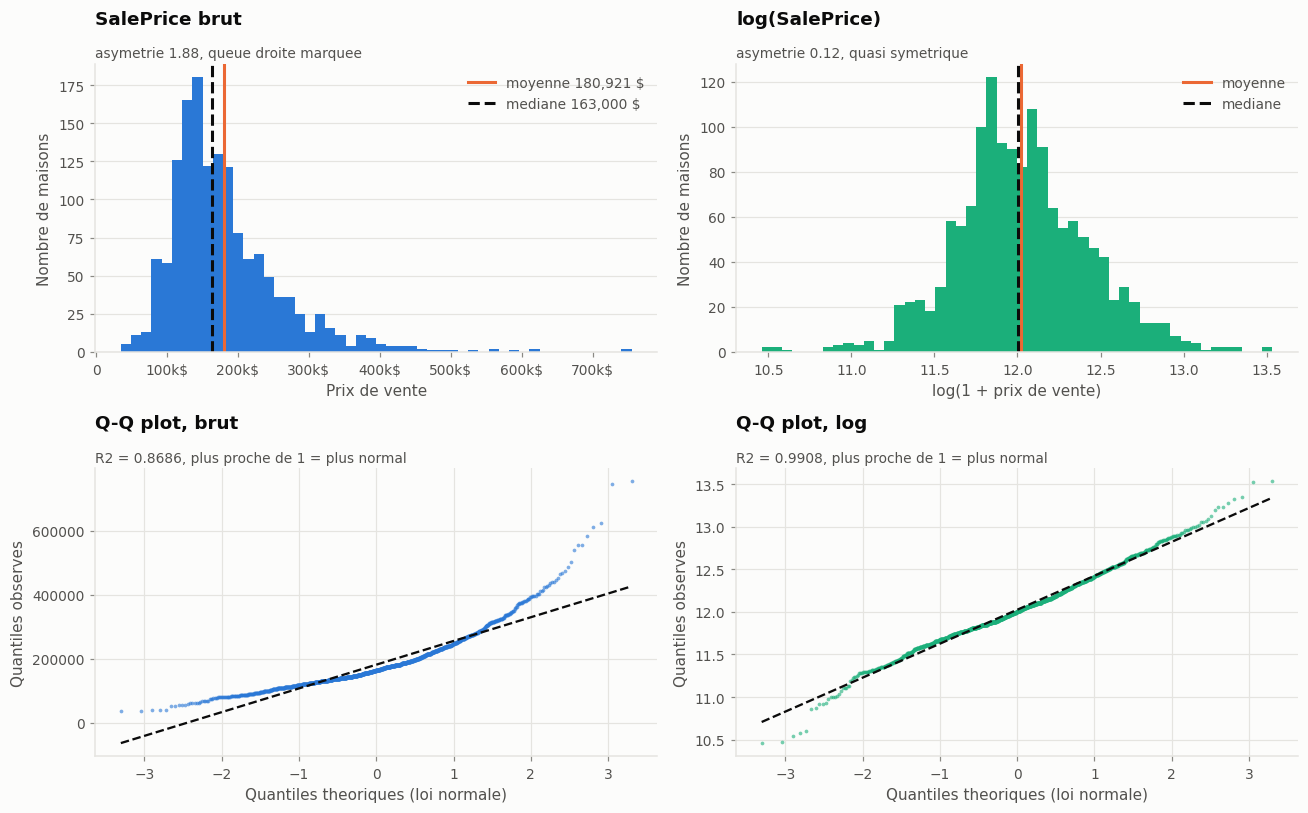

In [13]:
# SalePrice brut vs log(SalePrice)
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))

axes[0, 0].hist(y, bins=50, color=viz.BLEU)
axes[0, 0].axvline(y.mean(), color=viz.ORANGE, lw=2, label=f"moyenne {y.mean():,.0f} $")
axes[0, 0].axvline(y.median(), color=viz.ENCRE, lw=2, ls="--",
                   label=f"mediane {y.median():,.0f} $")
axes[0, 0].set_xlabel("Prix de vente")
axes[0, 0].set_ylabel("Nombre de maisons")
axes[0, 0].legend(loc="upper right")
viz.format_dollars(axes[0, 0], "x")
viz.titrer(axes[0, 0], "SalePrice brut", f"asymetrie {y.skew():.2f}, queue droite marquee")

axes[0, 1].hist(y_log, bins=50, color=viz.AQUA)
axes[0, 1].axvline(y_log.mean(), color=viz.ORANGE, lw=2, label="moyenne")
axes[0, 1].axvline(y_log.median(), color=viz.ENCRE, lw=2, ls="--", label="mediane")
axes[0, 1].set_xlabel("log(1 + prix de vente)")
axes[0, 1].set_ylabel("Nombre de maisons")
axes[0, 1].legend(loc="upper right")
viz.titrer(axes[0, 1], "log(SalePrice)", f"asymetrie {y_log.skew():.2f}, quasi symetrique")

for ax, serie, couleur, titre in [
        (axes[1, 0], y, viz.BLEU, "Q-Q plot, brut"),
        (axes[1, 1], y_log, viz.AQUA, "Q-Q plot, log")]:
    (osm, osr), (pente, origine, r) = stats.probplot(serie, dist="norm")
    ax.scatter(osm, osr, s=6, color=couleur, alpha=0.6)
    ax.plot(osm, pente * osm + origine, color=viz.ENCRE, lw=1.5, ls="--")
    ax.set_xlabel("Quantiles theoriques (loi normale)")
    ax.set_ylabel("Quantiles observes")
    ax.grid(True, axis="both")
    viz.titrer(ax, titre, f"R2 = {r**2:.4f}, plus proche de 1 = plus normal")

fig.tight_layout()
viz.sauver(fig, "fig_01_distribution_cible")
plt.show()

In [14]:
# Verdict statistique : Shapiro-Wilk (H0 = loi normale)
display(pd.DataFrame({
    "SalePrice brut": [y.skew(), y.kurt(), stats.shapiro(y).pvalue],
    "log(SalePrice)": [y_log.skew(), y_log.kurt(), stats.shapiro(y_log).pvalue],
}, index=["Asymetrie", "Aplatissement", "Shapiro-Wilk (p-value)"]))

,SalePrice brut,log(SalePrice)
Asymetrie,1.882876e+00,1.213466e-01
Aplatissement,6.536282e+00,8.095192e-01
Shapiro-Wilk (p-value),3.206141e-33,1.149074e-07



| Indicateur | Brut | Log |
|---|---|---|
| Asymétrie | 1,883 | **0,121** |
| Aplatissement | 6,536 | **0,810** |
| Shapiro-Wilk | 3,2e-33 | 1,2e-07 |

Le log améliore nettement sans rendre parfait. Shapiro-Wilk rejette toujours la normalité,
mais ce test est très sensible sur de grands échantillons : avec $n = 1460$ il détecte le
moindre écart. Les indicateurs utiles sont l'asymétrie, l'aplatissement et le Q-Q plot.

> **Décision : entraîner sur `log(SalePrice)`**, reconvertir en dollars pour l'évaluation.
>
> 1. La métrique Kaggle est une RMSE sur log : on optimise directement la bonne cible.
> 2. Sur les prix bruts, l'erreur croît avec le prix. Le log stabilise cette variance.
> 3. Le log transforme une erreur absolue en erreur relative, ce qui a un sens économique.
>
> Les métriques de l'étape 6 seront rapportées **en dollars**, après reconversion.


## 2.2 Corrélations avec la cible

Pearson mesure la relation **linéaire**. On le calcule contre la cible brute et contre sa
version log : si le log est le bon choix, les corrélations doivent s'améliorer. Limite :
une relation en U donnerait $r \approx 0$ alors que le lien est fort, d'où l'inspection
visuelle du § 2.4.

In [15]:
# Correlations contre la cible brute et contre sa version log
num = df.select_dtypes(include=[np.number]).drop(columns=["Id"])
num_feats = num.drop(columns=["SalePrice"])

corr = pd.DataFrame({"r_brut": num_feats.corrwith(y), "r_log": num_feats.corrwith(y_log)})
corr["gain_log"] = corr.r_log.abs() - corr.r_brut.abs()
corr = corr.sort_values("r_log", ascending=False)

print("10 correlations positives les plus fortes :")
display(corr.head(10).round(3))
print("5 correlations negatives les plus fortes :")
display(corr.tail(5).round(3))
print(f"Correlations ameliorees par le log : {(corr.gain_log > 0).sum()} / {len(corr)}")

10 correlations positives les plus fortes :


,r_brut,r_log,gain_log
OverallQual,0.791,0.817,0.026
GrLivArea,0.709,0.701,-0.008
GarageCars,0.640,0.681,0.040
GarageArea,0.623,0.651,0.027
TotalBsmtSF,0.614,0.612,-0.001
1stFlrSF,0.606,0.597,-0.009
FullBath,0.561,0.595,0.034
YearBuilt,0.523,0.587,0.064
YearRemodAdd,0.507,0.566,0.059
GarageYrBlt,0.486,0.541,0.055


5 correlations negatives les plus fortes :


,r_brut,r_log,gain_log
YrSold,-0.029,-0.037,0.008
LowQualFinSF,-0.026,-0.038,0.012
MSSubClass,-0.084,-0.074,-0.010
KitchenAbvGr,-0.136,-0.148,0.012
EnclosedPorch,-0.129,-0.149,0.020


Correlations ameliorees par le log : 23 / 36


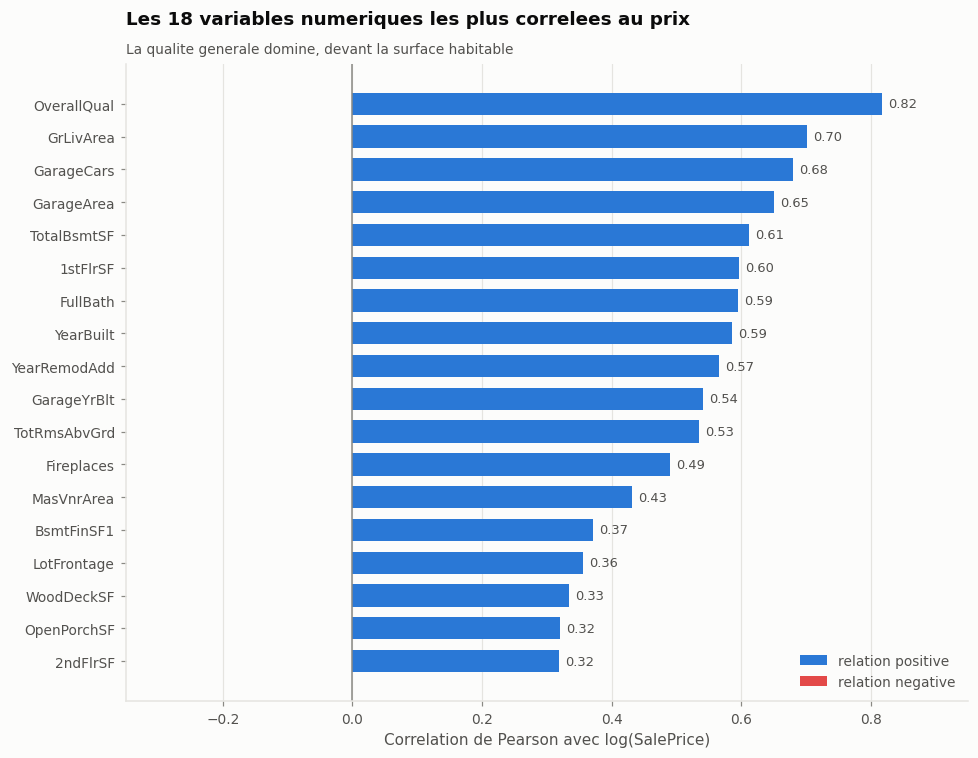

In [16]:
# Polarite (positif / negatif) donc palette divergente
top = corr.reindex(corr.r_log.abs().sort_values(ascending=False).index).head(18)
top = top.sort_values("r_log")

fig, ax = plt.subplots(figsize=(9, 7))
barres = ax.barh(top.index, top.r_log, height=0.68,
                 color=[viz.BLEU if v > 0 else viz.ROUGE for v in top.r_log])
ax.bar_label(barres, fmt="%.2f", padding=4, fontsize=8.5, color=viz.ENCRE_2)
ax.axvline(0, color=viz.ENCRE_3, lw=1)
ax.set_xlim(-0.35, 0.95)
ax.set_xlabel("Correlation de Pearson avec log(SalePrice)")
ax.grid(True, axis="x"); ax.grid(False, axis="y")
ax.legend(handles=[Patch(color=viz.BLEU, label="relation positive"),
                   Patch(color=viz.ROUGE, label="relation negative")], loc="lower right")
viz.titrer(ax, "Les 18 variables numeriques les plus correlees au prix",
           "La qualite generale domine, devant la surface habitable")
fig.tight_layout()
viz.sauver(fig, "fig_02_correlations")
plt.show()


| Rang | Variable | r (log) |
|---|---|---|
| 1 | `OverallQual` | **0,817** |
| 2 | `GrLivArea` | **0,701** |
| 3 | `GarageCars` | 0,681 |
| 4 | `GarageArea` | 0,651 |
| 5 | `TotalBsmtSF` | 0,612 |

**La qualité bat la quantité.** `OverallQual`, simple note de 1 à 10, est plus prédictive
que n'importe quelle surface.

**Le log est validé empiriquement** : `OverallQual` passe de 0,791 à 0,817, `YearBuilt` de
0,523 à 0,587, et 23 variables sur 36 y gagnent.

**Les corrélations négatives sont trompeuses.** `KitchenAbvGr` (-0,148) : 2 cuisines
signale un logement bi-familial, moins valorisé. `OverallCond` (-0,037) : les maisons
anciennes ont une bonne note d'état tout en valant moins cher, la note est relative à
l'âge. La supprimer serait une erreur, les arbres exploitent son interaction avec
`YearBuilt`.


## 2.3 Multicolinéarité

Quand $X_1 \approx X_2$, le modèle linéaire ne peut pas répartir leur effet de façon stable
et les coefficients deviennent ininterprétables. Les arbres y sont insensibles : ils
choisissent simplement l'une des deux à chaque nœud.

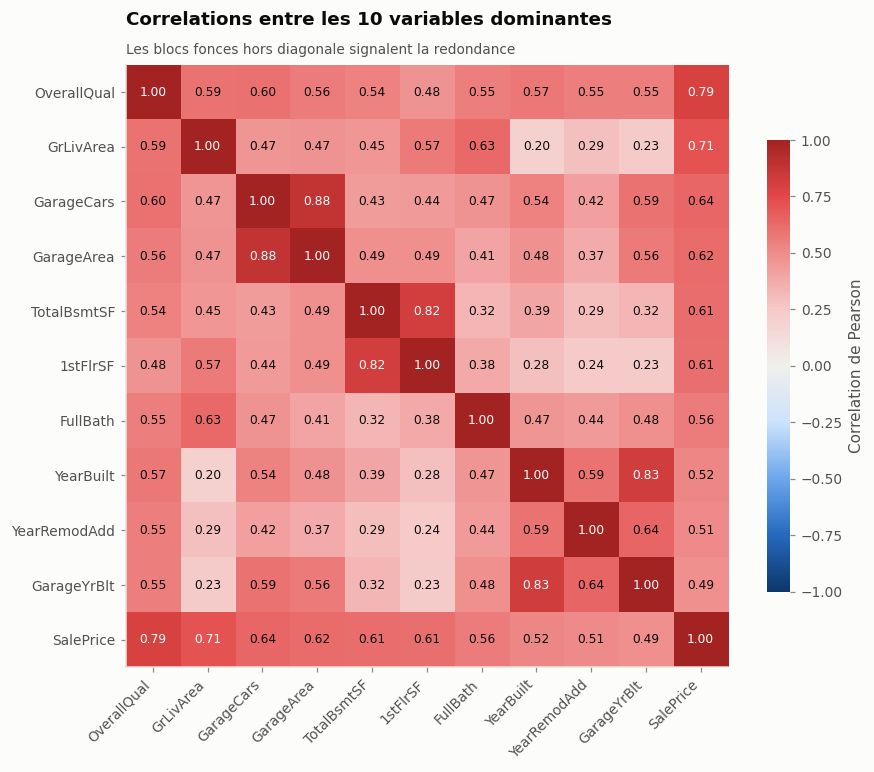

In [17]:
# Matrice de correlation des variables dominantes
top10 = corr.r_log.abs().sort_values(ascending=False).head(10).index.tolist()
matrice = num[top10 + ["SalePrice"]].corr()

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(matrice, cmap=viz.CMAP_DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(matrice)), matrice.columns, rotation=45, ha="right")
ax.set_yticks(range(len(matrice)), matrice.columns)
ax.grid(False)
for i in range(len(matrice)):
    for j in range(len(matrice)):
        v = matrice.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.65 else viz.ENCRE)
cb = fig.colorbar(im, ax=ax, shrink=0.75)
cb.set_label("Correlation de Pearson", color=viz.ENCRE_2)
cb.outline.set_visible(False)
viz.titrer(ax, "Correlations entre les 10 variables dominantes",
           "Les blocs fonces hors diagonale signalent la redondance")
fig.tight_layout()
viz.sauver(fig, "fig_03_matrice_correlation")
plt.show()

In [18]:
# Paires redondantes (|r| > 0.70)
c = num_feats.corr().abs()
paires = (c.where(np.triu(np.ones(c.shape), k=1).astype(bool))
           .stack().sort_values(ascending=False))
redondantes = paires[paires > 0.70]
display(pd.DataFrame({
    "variable_A": [a for a, _ in redondantes.index],
    "variable_B": [b for _, b in redondantes.index],
    "abs_r": redondantes.values.round(3),
}))

,variable_A,variable_B,abs_r
0,GarageCars,GarageArea,0.882
1,YearBuilt,GarageYrBlt,0.826
2,GrLivArea,TotRmsAbvGrd,0.825
3,TotalBsmtSF,1stFlrSF,0.820



| Paire | \|r\| | Pourquoi |
|---|---|---|
| `GarageCars` / `GarageArea` | 0,882 | Même information, en voitures ou en pi² |
| `YearBuilt` / `GarageYrBlt` | 0,826 | Garage construit avec la maison |
| `GrLivArea` / `TotRmsAbvGrd` | 0,825 | Plus grand, plus de pièces |
| `TotalBsmtSF` / `1stFlrSF` | 0,820 | Le sous-sol épouse l'emprise au sol |

> **Décisions.** Arbres : on ne supprime rien. Régression linéaire : régularisation
> **Ridge**, qui stabilise les coefficients sans supprimer arbitrairement de variables. Les
> deux : créer des agrégats (`SurfaceTotale`, `TotalSdB`) à l'étape 4.


## 2.4 Forme des relations

Un $r$ élevé ne garantit pas la linéarité, et c'est elle qui détermine quels modèles
conviennent.

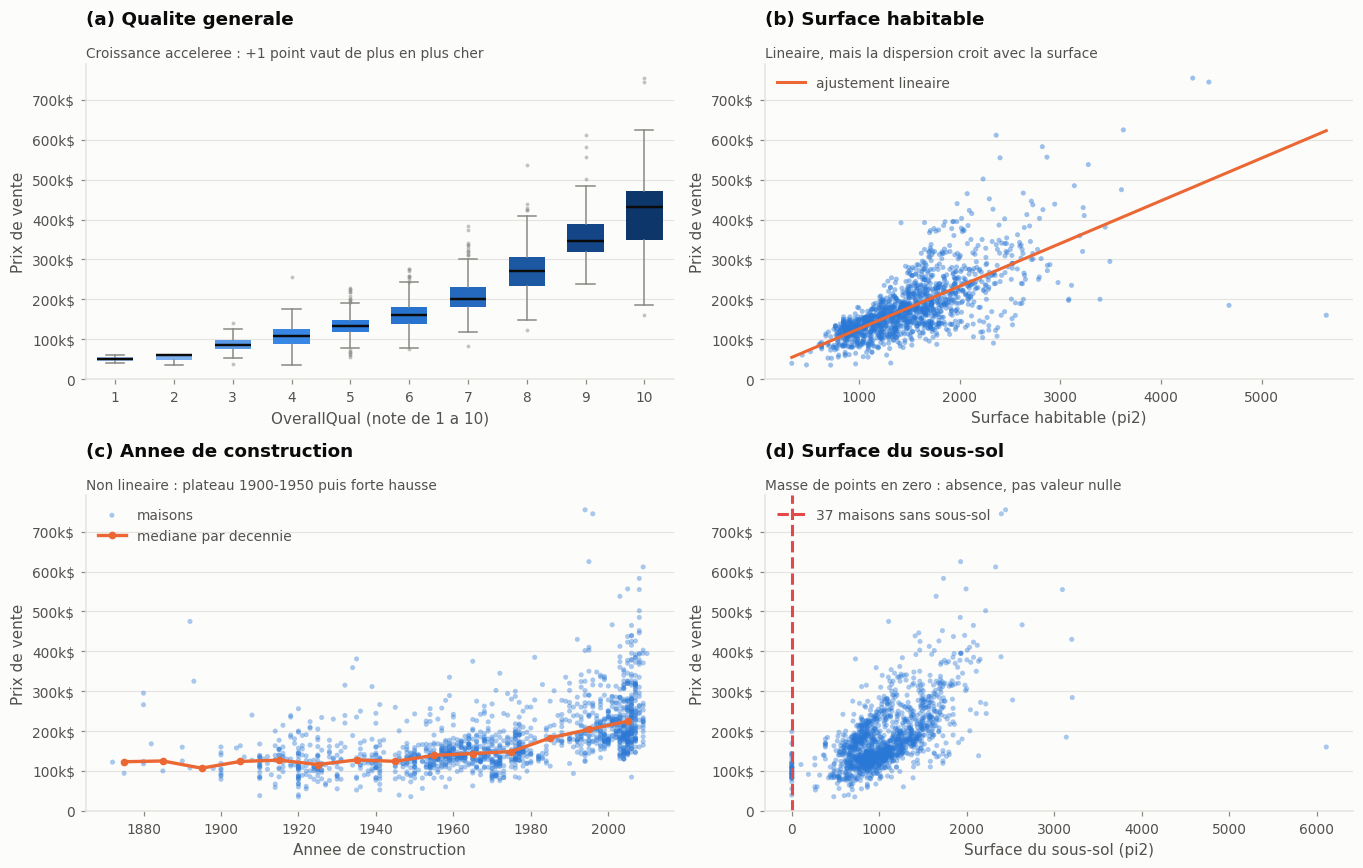

In [19]:
# Style commun aux boites a moustaches de cette section
STYLE_BOITE = dict(
    patch_artist=True,
    medianprops=dict(color=viz.ENCRE, lw=1.6),
    flierprops=dict(marker="o", markersize=2.5, markerfacecolor=viz.ENCRE_3,
                    markeredgecolor="none", alpha=0.5),
    boxprops=dict(edgecolor="none"),
    whiskerprops=dict(color=viz.ENCRE_3),
    capprops=dict(color=viz.ENCRE_3),
)


def colorer(bp, n):
    """Rampe sequentielle : la couleur encode le rang de la modalite."""
    for i, boite in enumerate(bp["boxes"]):
        boite.set_facecolor(viz.CMAP_SEQ(0.15 + 0.85 * i / max(n - 1, 1)))


fig, axes = plt.subplots(2, 2, figsize=(12.5, 8))

qualites = sorted(df.OverallQual.unique())
bp = axes[0, 0].boxplot([df.loc[df.OverallQual == q, "SalePrice"].values for q in qualites],
                        positions=qualites, widths=0.62, **STYLE_BOITE)
colorer(bp, len(qualites))
axes[0, 0].set_xlabel("OverallQual (note de 1 a 10)")
axes[0, 0].set_ylabel("Prix de vente")
viz.format_dollars(axes[0, 0])
viz.titrer(axes[0, 0], "(a) Qualite generale",
           "Croissance acceleree : +1 point vaut de plus en plus cher")

axes[0, 1].scatter(df.GrLivArea, y, s=11, color=viz.BLEU, alpha=0.45, edgecolors="none")
pente, origine = np.polyfit(df.GrLivArea, y, 1)
xs = np.linspace(df.GrLivArea.min(), df.GrLivArea.max(), 50)
axes[0, 1].plot(xs, pente * xs + origine, color=viz.ORANGE, lw=2,
                label="ajustement lineaire")
axes[0, 1].set_xlabel("Surface habitable (pi2)")
axes[0, 1].set_ylabel("Prix de vente")
axes[0, 1].legend(loc="upper left")
viz.format_dollars(axes[0, 1])
viz.titrer(axes[0, 1], "(b) Surface habitable",
           "Lineaire, mais la dispersion croit avec la surface")

axes[1, 0].scatter(df.YearBuilt, y, s=11, color=viz.BLEU, alpha=0.4, edgecolors="none",
                   label="maisons")
decennies = pd.cut(df.YearBuilt, bins=range(1870, 2021, 10))
med = df.groupby(decennies, observed=False)["SalePrice"].median().dropna()
axes[1, 0].plot([iv.mid for iv in med.index], med.values, color=viz.ORANGE, lw=2.2,
                marker="o", ms=4, label="mediane par decennie")
axes[1, 0].set_xlabel("Annee de construction")
axes[1, 0].set_ylabel("Prix de vente")
axes[1, 0].legend(loc="upper left")
viz.format_dollars(axes[1, 0])
viz.titrer(axes[1, 0], "(c) Annee de construction",
           "Non lineaire : plateau 1900-1950 puis forte hausse")

axes[1, 1].scatter(df.TotalBsmtSF, y, s=11, color=viz.BLEU, alpha=0.4, edgecolors="none")
axes[1, 1].axvline(0, color=viz.ROUGE, lw=2, ls="--",
                   label=f"{(df.TotalBsmtSF == 0).sum()} maisons sans sous-sol")
axes[1, 1].set_xlabel("Surface du sous-sol (pi2)")
axes[1, 1].set_ylabel("Prix de vente")
axes[1, 1].legend(loc="upper left")
viz.format_dollars(axes[1, 1])
viz.titrer(axes[1, 1], "(d) Surface du sous-sol",
           "Masse de points en zero : absence, pas valeur nulle")

fig.tight_layout()
viz.sauver(fig, "fig_04_relations_cle")
plt.show()


**(a) `OverallQual` est convexe.** Passer de 5 à 6 ajoute environ 27 000 \$, de 9 à 10
environ 87 000. Une régression linéaire, qui impose un effet constant, ne peut pas le
représenter.

**(b) `GrLivArea` est linéaire mais hétéroscédastique** : le nuage s'évase, l'erreur est
plus grande sur les grandes maisons. C'est ce que le log corrige.

**(c) `YearBuilt` est franchement non linéaire** : plateau 1900-1950 puis forte hausse. Le
$r$ de 0,587 sous-estime son pouvoir prédictif.

**(d) `TotalBsmtSF` est à inflation de zéros** : les maisons sans sous-sol forment une
colonne qui ne suit pas la tendance. D'où le besoin d'une binaire.

> **Trois relations sur quatre sont non linéaires.** C'est l'argument central en faveur des
> forêts de décision : elles capturent ces courbures sans qu'on ait à les spécifier. Nous
> gardons la régression linéaire comme référence, pour quantifier ce que les modèles non
> linéaires apportent.


## 2.5 Variables catégorielles

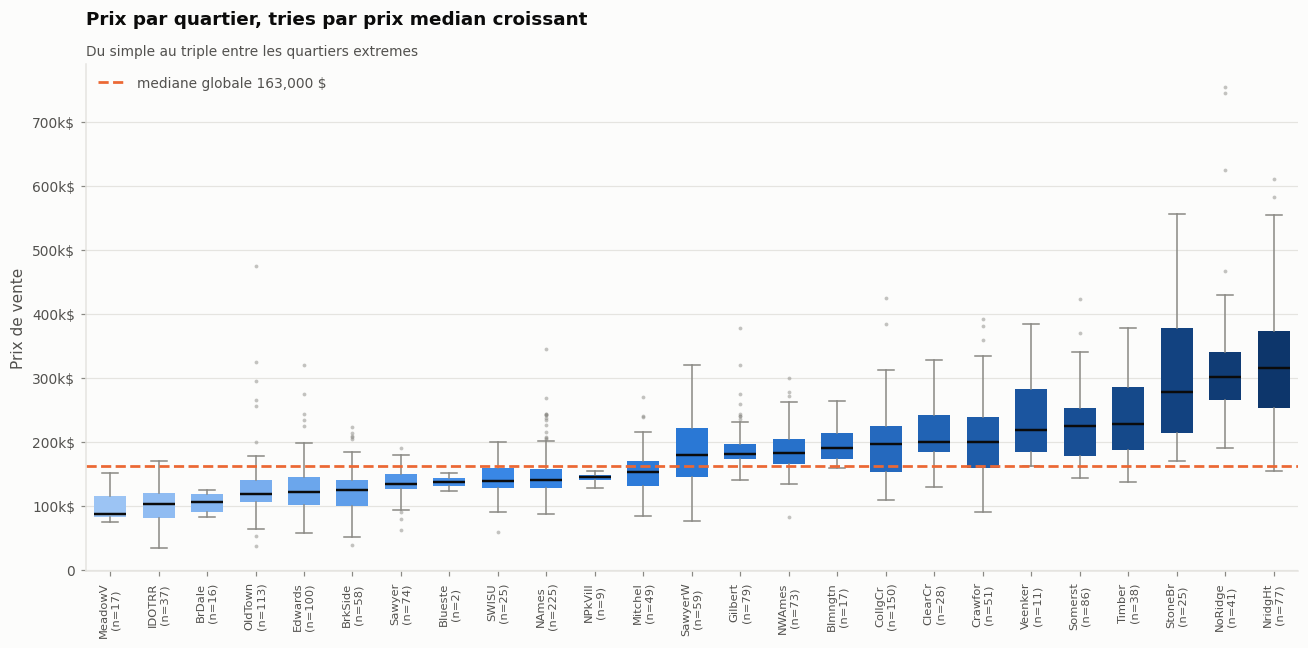

,count,median
Neighborhood,,
MeadowV,17,88000.0
IDOTRR,37,103000.0
BrDale,16,106000.0
StoneBr,25,278000.0
NoRidge,41,301500.0
NridgHt,77,315000.0


Rapport entre extremes : x3.58


In [20]:
# Effet du quartier (25 modalites)
ordre = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index
effectifs = df.Neighborhood.value_counts()

fig, ax = plt.subplots(figsize=(12, 6))
bp = ax.boxplot([df.loc[df.Neighborhood == q, "SalePrice"].values for q in ordre],
                positions=range(len(ordre)), widths=0.66, **STYLE_BOITE)
colorer(bp, len(ordre))
ax.set_xticks(range(len(ordre)), [f"{q}\n(n={effectifs[q]})" for q in ordre],
              rotation=90, fontsize=7.5)
ax.set_ylabel("Prix de vente")
viz.format_dollars(ax)
ax.axhline(y.median(), color=viz.ORANGE, lw=1.8, ls="--",
           label=f"mediane globale {y.median():,.0f} $")
ax.legend(loc="upper left")
viz.titrer(ax, "Prix par quartier, tries par prix median croissant",
           "Du simple au triple entre les quartiers extremes")
fig.tight_layout()
viz.sauver(fig, "fig_05_quartiers")
plt.show()

recap_q = df.groupby("Neighborhood")["SalePrice"].agg(["count", "median"]).sort_values("median")
display(pd.concat([recap_q.head(3), recap_q.tail(3)]))
print(f"Rapport entre extremes : x{recap_q['median'].iloc[-1] / recap_q['median'].iloc[0]:.2f}")

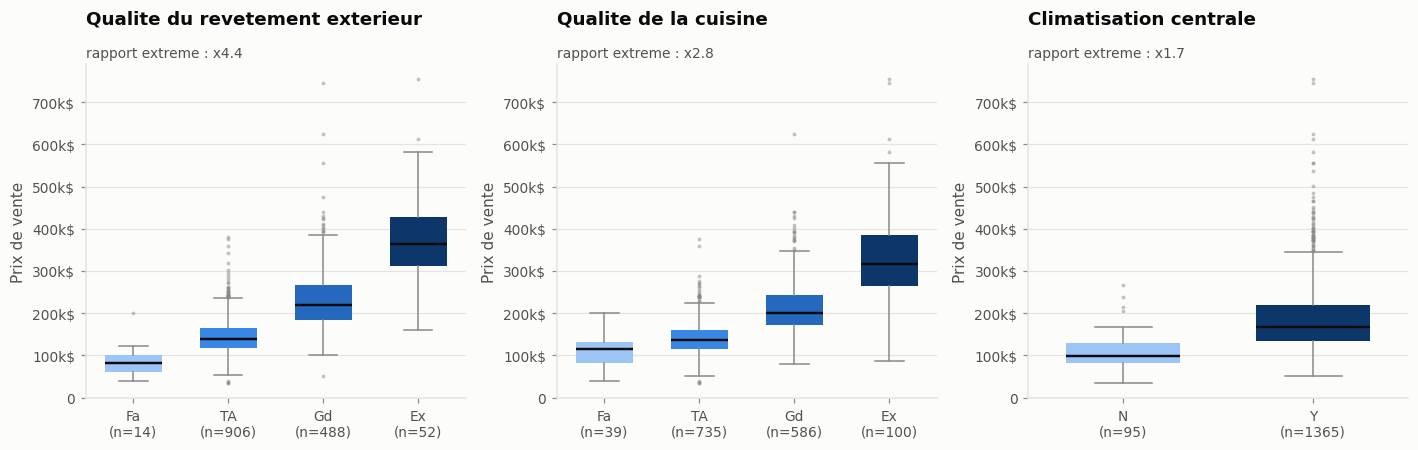

In [21]:
# Trois variables qualitatives
ECHELLES = {
    "ExterQual": (["Fa", "TA", "Gd", "Ex"], "Qualite du revetement exterieur"),
    "KitchenQual": (["Fa", "TA", "Gd", "Ex"], "Qualite de la cuisine"),
    "CentralAir": (["N", "Y"], "Climatisation centrale"),
}

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (col, (ordre_mod, libelle)) in zip(axes, ECHELLES.items()):
    mods = [m for m in ordre_mod if m in df[col].unique()]
    bp = ax.boxplot([df.loc[df[col] == m, "SalePrice"].values for m in mods],
                    positions=range(len(mods)), widths=0.6, **STYLE_BOITE)
    colorer(bp, len(mods))
    ax.set_xticks(range(len(mods)), [f"{m}\n(n={(df[col] == m).sum()})" for m in mods],
                  fontsize=9)
    ax.set_ylabel("Prix de vente")
    viz.format_dollars(ax)
    med = df.groupby(col)["SalePrice"].median()
    viz.titrer(ax, libelle, f"rapport extreme : x{med[mods[-1]] / med[mods[0]]:.1f}")

fig.tight_layout()
viz.sauver(fig, "fig_06_variables_qualitatives")
plt.show()


**Le quartier est un prédicteur de premier ordre** : de 88 000 \$ (`MeadowV`) à
315 000 \$ (`NridgHt`), soit un rapport de **3,6**. Aucune variable numérique ne produit
un tel écart. Deux réserves : effectifs très inégaux (17 maisons contre 225), et 25
modalités en one-hot pour 1 460 lignes. TFDF évite ce problème.

**Les variables de qualité sont très discriminantes** : `ExterQual` x4,4, `KitchenQual`
x2,8, `CentralAir` x1,7 entre modalités extrêmes.

> **Décision** : ces variables sont **ordinales** (`Fa < TA < Gd < Ex`). Un one-hot
> détruirait cette information. Encodage ordinal à l'étape 4, après vérification de
> monotonie.


## 2.6 Valeurs manquantes et distributions

La question n'est pas "combien de trous" mais **"pourquoi ce trou existe"**.

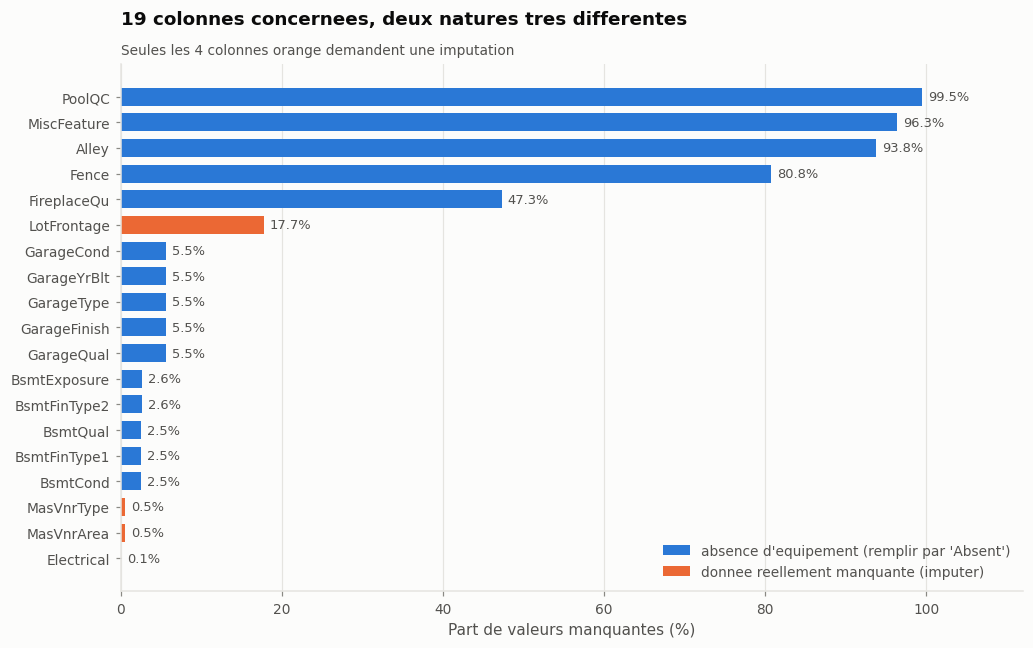

In [22]:
# Classification selon la NATURE du trou
ABSENCE_EQUIPEMENT = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond", "GarageYrBlt",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
]
nb_nan = df.isna().sum()
nb_nan = nb_nan[nb_nan > 0].sort_values()
est_absence = [c in ABSENCE_EQUIPEMENT for c in nb_nan.index]

fig, ax = plt.subplots(figsize=(9.5, 6))
barres = ax.barh(nb_nan.index, 100 * nb_nan.values / len(df), height=0.7,
                 color=[viz.BLEU if a else viz.ORANGE for a in est_absence])
ax.bar_label(barres, fmt="%.1f%%", padding=4, fontsize=8.5, color=viz.ENCRE_2)
ax.set_xlabel("Part de valeurs manquantes (%)")
ax.set_xlim(0, 112)
ax.grid(True, axis="x"); ax.grid(False, axis="y")
ax.legend(handles=[Patch(color=viz.BLEU, label="absence d'equipement (remplir par 'Absent')"),
                   Patch(color=viz.ORANGE, label="donnee reellement manquante (imputer)")],
          loc="lower right")
viz.titrer(ax, "19 colonnes concernees, deux natures tres differentes",
           "Seules les 4 colonnes orange demandent une imputation")
fig.tight_layout()
viz.sauver(fig, "fig_07_valeurs_manquantes")
plt.show()

In [23]:
# Preuve : "NA" signifie-t-il bien "pas d'equipement" ?
# On croise la colonne qualitative avec le compteur quantitatif correspondant.
print("Concordance entre le 'NA' qualitatif et le compteur quantitatif :\n")
for col, condition, libelle in [
        ("FireplaceQu", df.Fireplaces == 0, "sans cheminee"),
        ("GarageType", df.GarageArea == 0, "sans garage"),
        ("BsmtQual", df.TotalBsmtSF == 0, "sans sous-sol"),
        ("PoolQC", df.PoolArea == 0, "sans piscine")]:
    nan_col = df[col].isna()
    print(f"  {col:12s} {nan_col.sum():4d} NaN | {condition.sum():4d} maisons {libelle:14s}"
          f" | concordance {(nan_col == condition).mean() * 100:5.1f} %")

par_q = df.groupby("Neighborhood")["LotFrontage"].median()
print(f"\nLotFrontage : mediane globale {df.LotFrontage.median():.0f} pieds, "
      f"medianes par quartier de {par_q.min():.0f} a {par_q.max():.0f} "
      f"(ecart-type {par_q.std():.1f})")

Concordance entre le 'NA' qualitatif et le compteur quantitatif :

  FireplaceQu   690 NaN |  690 maisons sans cheminee  | concordance 100.0 %
  GarageType     81 NaN |   81 maisons sans garage    | concordance 100.0 %
  BsmtQual       37 NaN |   37 maisons sans sous-sol  | concordance 100.0 %
  PoolQC       1453 NaN | 1453 maisons sans piscine   | concordance 100.0 %

LotFrontage : mediane globale 69 pieds, medianes par quartier de 21 a 91 (ecart-type 20.6)


,skewness
MiscVal,24.48
PoolArea,14.83
LotArea,12.21
3SsnPorch,10.30
LowQualFinSF,9.01
KitchenAbvGr,4.49
BsmtFinSF2,4.26
ScreenPorch,4.12


Variables avec |skew| > 1 : 19 / 36


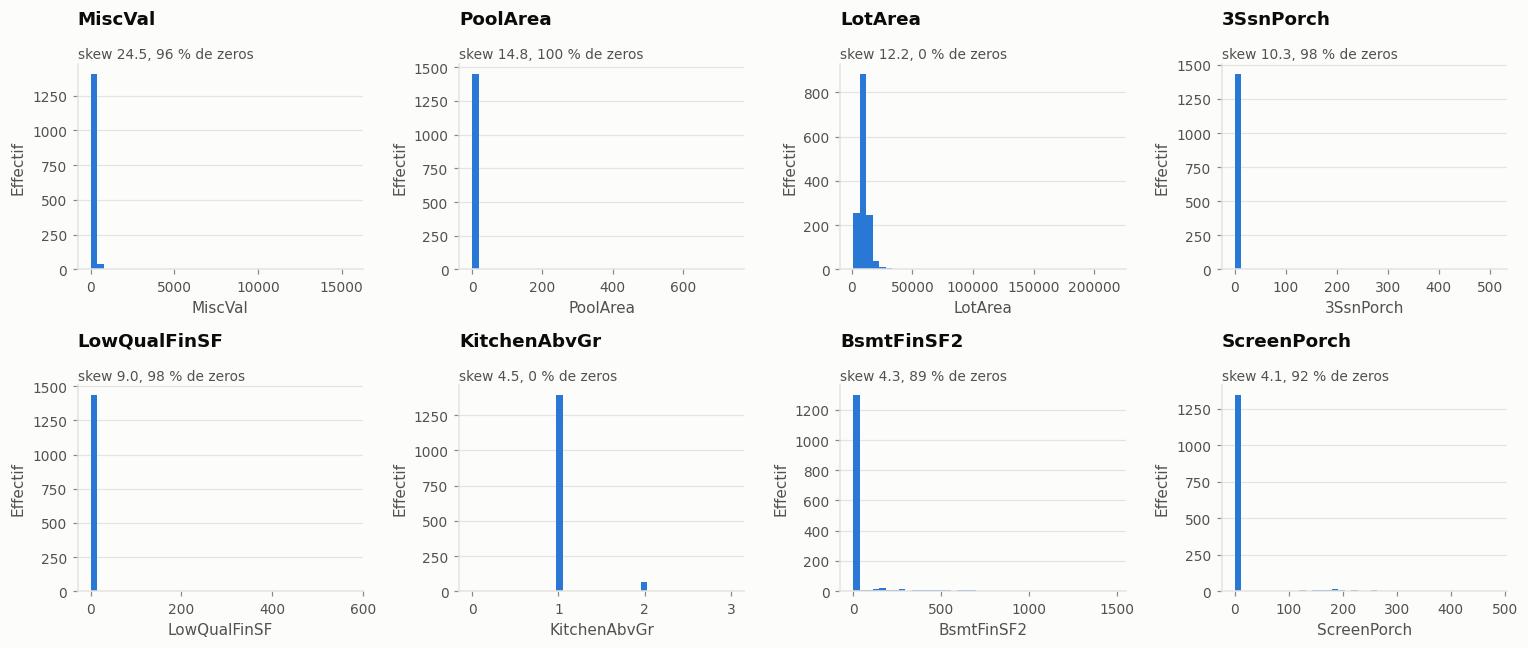

In [24]:
# Distributions des variables numeriques (analyse du notebook original)
asym = num_feats.skew().sort_values(ascending=False)
display(asym.head(8).to_frame("skewness").round(2))
print(f"Variables avec |skew| > 1 : {(asym.abs() > 1).sum()} / {len(asym)}")

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, col in zip(axes.ravel(), asym.head(8).index):
    ax.hist(df[col].dropna(), bins=40, color=viz.BLEU)
    ax.set_xlabel(col)
    ax.set_ylabel("Effectif")
    viz.titrer(ax, col, f"skew {asym[col]:.1f}, {100 * (df[col] == 0).mean():.0f} % de zeros")
fig.tight_layout()
viz.sauver(fig, "fig_08_asymetrie")
plt.show()


**Concordance de 100 % sur les quatre contrôles** : chaque `NaN` de `FireplaceQu`
correspond exactement à une maison sans cheminée, chaque `NaN` de `PoolQC` à une maison
sans piscine. C'est une preuve, pas une supposition. Ces colonnes seront remplies par
`"Absent"`, surtout pas par le mode, ce qui reviendrait à inventer des piscines.

**`LotFrontage` est le seul cas délicat** : médianes par quartier de 21 à 91 pieds,
écart-type 20,6. Les quartiers sont très hétérogènes, l'urbanisme étant homogène à
l'intérieur d'un quartier.

**Les variables les plus asymétriques** ont le même profil : `MiscVal` (skew 24,5) est à
96,4 % nulle, `PoolArea` (14,8) à 99,5 %. Ce sont deux informations mélangées, existence et
taille.

> **Décisions.** 15 colonnes "absence" vers `"Absent"` ou `0`. `LotFrontage` vers la médiane
> du quartier **apprise sur le train seul**. `MasVnrType`/`Area` et `Electrical` par le
> mode. Variables à inflation de zéros : créer une binaire de présence. `LotArea` : log,
> **pour les modèles linéaires seulement**, car une transformation monotone ne change rien
> pour un arbre.


## 2.7 Détection des anomalies

Supprimer des points est lourd : mal fait, cela revient à truquer les données. Nous
n'appliquons pas de règle automatique mais exigeons **deux conditions cumulatives** : le
point est statistiquement extrême, **et** une explication métier le rend non représentatif.
Sans la seconde, on garde : une maison chère n'est pas une erreur.

In [25]:
# Les maisons de tres grande surface
grandes = df[df.GrLivArea > 4000][
    ["Id", "GrLivArea", "SalePrice", "OverallQual", "SaleCondition", "Neighborhood"]]
display(grandes.sort_values("GrLivArea"))

print(f"Prix median au pi2 sur tout le jeu : "
      f"{(df.SalePrice / df.GrLivArea).median():.0f} $/pi2")
for _, r in grandes.iterrows():
    print(f"  Id {int(r.Id):4d} : {r.SalePrice / r.GrLivArea:5.0f} $/pi2  ({r.SaleCondition})")

,Id,GrLivArea,SalePrice,OverallQual,SaleCondition,Neighborhood
691,692,4316,755000,10,Normal,NoRidge
1182,1183,4476,745000,10,Abnorml,NoRidge
523,524,4676,184750,10,Partial,Edwards
1298,1299,5642,160000,10,Partial,Edwards


Prix median au pi2 sur tout le jeu : 120 $/pi2
  Id  524 :    40 $/pi2  (Partial)
  Id  692 :   175 $/pi2  (Normal)
  Id 1183 :   166 $/pi2  (Abnorml)
  Id 1299 :    28 $/pi2  (Partial)


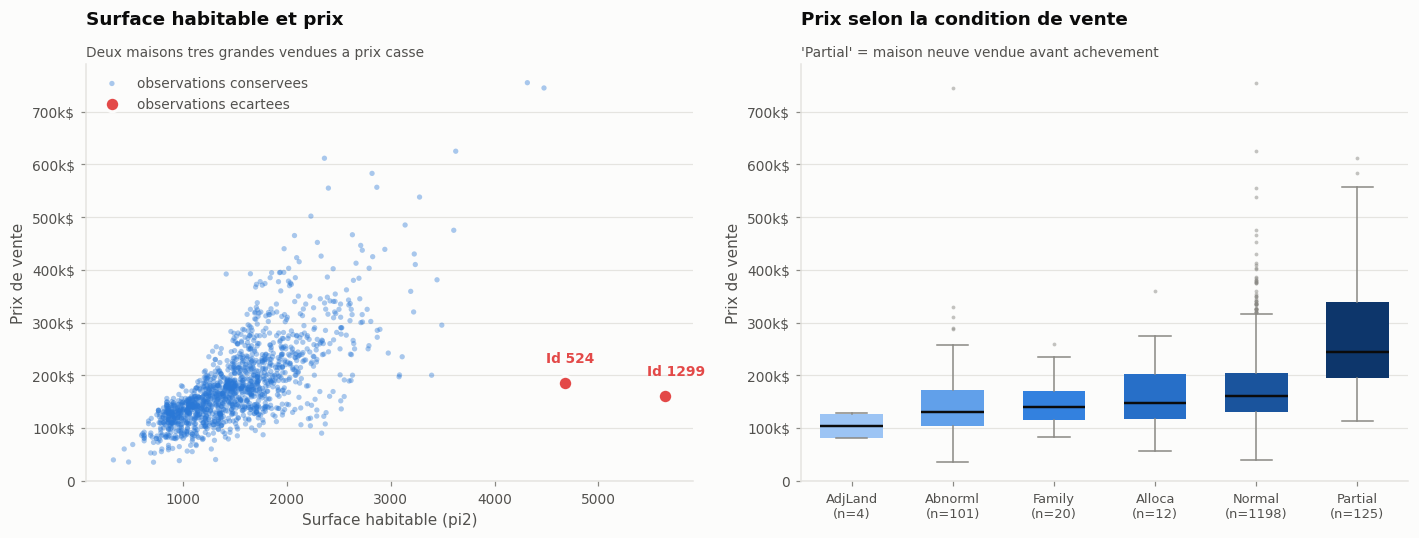

In [26]:
# Ou se situent ces points, et pourquoi deux seulement sont ecartes
A_SUPPRIMER = [524, 1299]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ordinaire = ~df.Id.isin(A_SUPPRIMER)
axes[0].scatter(df.loc[ordinaire, "GrLivArea"], df.loc[ordinaire, "SalePrice"],
                s=12, color=viz.BLEU, alpha=0.4, edgecolors="none",
                label="observations conservees")
axes[0].scatter(df.loc[~ordinaire, "GrLivArea"], df.loc[~ordinaire, "SalePrice"],
                s=90, color=viz.ROUGE, edgecolors=viz.SURFACE, linewidths=2,
                zorder=5, label="observations ecartees")
for _, r in df[df.Id.isin(A_SUPPRIMER)].iterrows():
    axes[0].annotate(f"Id {int(r.Id)}", (r.GrLivArea, r.SalePrice),
                     textcoords="offset points", xytext=(-12, 14),
                     fontsize=9, color=viz.ROUGE, fontweight="bold")
axes[0].set_xlabel("Surface habitable (pi2)")
axes[0].set_ylabel("Prix de vente")
axes[0].legend(loc="upper left")
viz.format_dollars(axes[0])
viz.titrer(axes[0], "Surface habitable et prix",
           "Deux maisons tres grandes vendues a prix casse")

ordre_sc = df.groupby("SaleCondition")["SalePrice"].median().sort_values().index
bp = axes[1].boxplot([df.loc[df.SaleCondition == s, "SalePrice"].values for s in ordre_sc],
                     positions=range(len(ordre_sc)), widths=0.62, **STYLE_BOITE)
colorer(bp, len(ordre_sc))
axes[1].set_xticks(range(len(ordre_sc)),
                   [f"{s}\n(n={(df.SaleCondition == s).sum()})" for s in ordre_sc],
                   fontsize=8.5)
axes[1].set_ylabel("Prix de vente")
viz.format_dollars(axes[1])
viz.titrer(axes[1], "Prix selon la condition de vente",
           "'Partial' = maison neuve vendue avant achevement")

fig.tight_layout()
viz.sauver(fig, "fig_09_anomalies")
plt.show()


| Id | Surface | Prix | \$/pi² | Condition | Verdict |
|---|---|---|---|---|---|
| 692 | 4 316 | 755 000 \$ | 175 | `Normal` | **Conservée** |
| 1183 | 4 476 | 745 000 \$ | 166 | `Abnorml` | **Conservée** |
| **524** | 4 676 | 184 750 \$ | **40** | `Partial` | **Écartée** |
| **1299** | 5 642 | 160 000 \$ | **28** | `Partial` | **Écartée** |

Le prix médian du jeu est de 120 \$/pi². Les maisons 524 et 1299 se sont vendues trois à
quatre fois moins cher que le marché, alors qu'elles sont les plus grandes du jeu et notées
`OverallQual = 10`. **L'explication est dans `SaleCondition`** : condition `Partial`, maison
neuve vendue avant achèvement. Le prix ne correspond pas à un bien fini. Cette exclusion est
recommandée par Dean De Cock, auteur du dataset (*Journal of Statistics Education*, 2011).

> **Décision** : écarter 2 observations sur 1 460 (0,14 %), sur critère double. Les maisons
> 692 et 1183 sont conservées, leur prix étant cohérent avec leur surface. La suppression
> est appliquée **au jeu d'entraînement seulement** : nettoyer la validation améliorerait
> artificiellement les métriques en retirant les cas difficiles de l'examen.


## 2.8 Les sept décisions issues de l'EDA

| # | Constat | Décision | Étape |
|---|---|---|---|
| 1 | Cible asymétrique (1,88 vers 0,12) | Entraîner sur `log(SalePrice)` | 5 |
| 2 | `OverallQual` (0,82) et `GrLivArea` (0,70) dominent | Variables pivots | 4 |
| 3 | 4 paires redondantes (jusqu'à 0,88) | Agrégats, et Ridge pour le linéaire | 4 et 5 |
| 4 | 3 relations sur 4 non linéaires | Arbres en première intention | 5 |
| 5 | Quartier : rapport x3,6 | TFDF la gère sans encodage | 4 et 5 |
| 6 | 15 colonnes `NA` = absence (concordance 100 %) | Remplir par `"Absent"` | 3 |
| 7 | 2 maisons à prix/pi² aberrant | Écarter, de l'entraînement seulement | 3 |

**Ce que cette EDA ajoute au notebook original** : validation empirique de la transformation
log, analyse de multicolinéarité, examen de la forme des relations (qui *justifie* le choix
des arbres au lieu de le postuler), preuve par les données de la sémantique des manquants,
et détection d'anomalies à critère métier explicite.

**Limites** : analyse univariée et bivariée, les interactions sont laissées aux arbres.
Pearson sous-estime les relations courbes. Aucune analyse spatiale possible, le dataset ne
fournit pas de coordonnées GPS.


<a id="etape-3"></a>
# Étape 3 : PRÉTRAITEMENT

**Objectif** : un jeu propre et sans valeur manquante, sans qu'aucune information de la
validation ne contamine l'entraînement.

**L'ordre des opérations est la partie critique :**

```
1. DÉCOUPER train / validation        <- avant toute modification
2. Apprendre les règles de nettoyage  <- sur le TRAIN uniquement
3. Appliquer ces règles                <- aux DEUX jeux, à l'identique
```

Exemple : imputer `LotFrontage` par la médiane du quartier. Si on nettoie **puis** découpe,
la médiane est calculée sur les 1 460 maisons, dont celles qui finiront en validation : le
modèle a vu indirectement le jeu de test et le score devient optimiste. L'erreur est
subtile, elle ne provoque aucun message et produit simplement de beaux chiffres faux.

> **Règle générale** : toute statistique calculée à partir des données (médiane, mode,
> catégories, mise à l'échelle) doit être estimée sur le train seul. C'est le contrat
> `fit` / `transform` de scikit-learn, que nous suivons pour pouvoir réutiliser les mêmes
> objets au déploiement.

In [27]:
# Imports de l'etape 3
import joblib
from sklearn.model_selection import train_test_split

brut = pd.read_csv(DATA_RAW / "train.csv", keep_default_na=False, na_values=["NA", ""])
print(f"Donnees brutes : {brut.shape[0]} lignes x {brut.shape[1]} colonnes")

Donnees brutes : 1460 lignes x 81 colonnes



## 3.1 Découpage entraînement / validation

| Paramètre | Valeur | Justification |
|---|---|---|
| Validation | 20 %, 292 maisons | Moins rendrait les métriques instables, plus priverait l'entraînement |
| Graine | 42, fixée | Sans elle, chaque exécution donnerait des chiffres différents |
| Stratification | sur `OverallQual` | Voir ci-dessous |

**Pourquoi stratifier** : un tirage purement aléatoire peut placer la quasi-totalité des
maisons haut de gamme d'un seul côté. Sur 18 maisons notées 10, le risque est réel. On ne
peut pas stratifier sur une variable continue, mais `OverallQual` est le meilleur substitut
($r = 0{,}82$ avec le prix).

In [28]:
# Decoupage stratifie 80 / 20
# Les notes extremes (1, 2, 10) comptent peu d'individus : on les regroupe
# pour permettre la stratification, sans modifier les donnees elles-memes.
strate = brut.OverallQual.clip(lower=3, upper=9)

train_brut, valid_brut = train_test_split(
    brut, test_size=0.20, random_state=GRAINE, stratify=strate)

print(f"Entrainement : {len(train_brut):4d} maisons ({len(train_brut)/len(brut):.1%})")
print(f"Validation   : {len(valid_brut):4d} maisons ({len(valid_brut)/len(brut):.1%})")
assert not (set(train_brut.Id) & set(valid_brut.Id)), "Chevauchement entre les deux jeux"
print("Controle : aucun chevauchement.")

Entrainement : 1168 maisons (80.0%)
Validation   :  292 maisons (20.0%)
Controle : aucun chevauchement.


In [29]:
# Le decoupage est-il equilibre ?
# Test de Kolmogorov-Smirnov : H0 = meme distribution. p > 0.05 est le resultat voulu.
comparaison = pd.DataFrame({
    "Entrainement": train_brut.SalePrice.describe(),
    "Validation": valid_brut.SalePrice.describe(),
})
display(comparaison.round(0))

ks = stats.ks_2samp(train_brut.SalePrice, valid_brut.SalePrice)
print(f"Kolmogorov-Smirnov : statistique = {ks.statistic:.4f}, p-value = {ks.pvalue:.3f}")
print("p > 0.05 : les deux jeux suivent la meme distribution de prix."
      if ks.pvalue > 0.05 else "p < 0.05 : les distributions different.")

,Entrainement,Validation
count,1168.0,292.0
mean,180817.0,181338.0
std,78749.0,82294.0
min,34900.0,39300.0
25%,130000.0,129000.0
50%,163000.0,165000.0
75%,214600.0,210000.0
max,755000.0,555000.0


Kolmogorov-Smirnov : statistique = 0.0394, p-value = 0.853
p > 0.05 : les deux jeux suivent la meme distribution de prix.


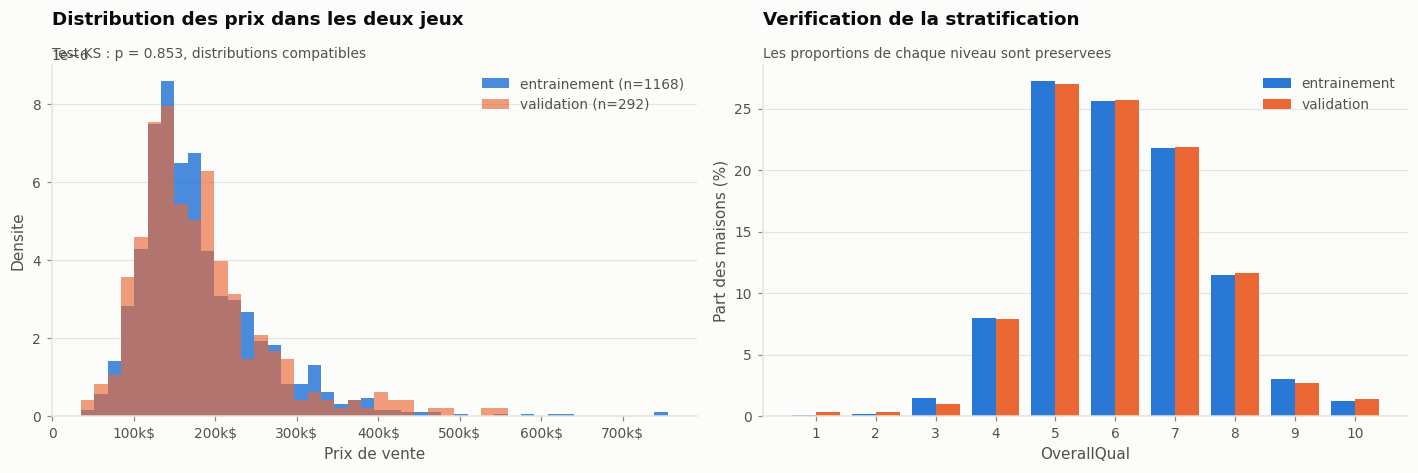

In [30]:
# Visualisation du decoupage
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

bornes = np.linspace(brut.SalePrice.min(), brut.SalePrice.max(), 45)
axes[0].hist(train_brut.SalePrice, bins=bornes, color=viz.BLEU, alpha=0.85, density=True,
             label=f"entrainement (n={len(train_brut)})")
axes[0].hist(valid_brut.SalePrice, bins=bornes, color=viz.ORANGE, alpha=0.65, density=True,
             label=f"validation (n={len(valid_brut)})")
axes[0].set_xlabel("Prix de vente")
axes[0].set_ylabel("Densite")
axes[0].legend()
viz.format_dollars(axes[0], "x")
viz.titrer(axes[0], "Distribution des prix dans les deux jeux",
           f"Test KS : p = {ks.pvalue:.3f}, distributions compatibles")

part_tr = train_brut.OverallQual.value_counts(normalize=True).sort_index()
part_va = valid_brut.OverallQual.value_counts(normalize=True).sort_index()
qualites = sorted(set(part_tr.index) | set(part_va.index))
x = np.arange(len(qualites))
axes[1].bar(x - 0.2, [100 * part_tr.get(q, 0) for q in qualites], width=0.4,
            color=viz.BLEU, label="entrainement")
axes[1].bar(x + 0.2, [100 * part_va.get(q, 0) for q in qualites], width=0.4,
            color=viz.ORANGE, label="validation")
axes[1].set_xticks(x, qualites)
axes[1].set_xlabel("OverallQual")
axes[1].set_ylabel("Part des maisons (%)")
axes[1].legend()
viz.titrer(axes[1], "Verification de la stratification",
           "Les proportions de chaque niveau sont preservees")

fig.tight_layout()
viz.sauver(fig, "fig_10_decoupage")
plt.show()


**1 168 maisons d'entraînement, 292 de validation.** Distributions compatibles
(Kolmogorov-Smirnov, $p = 0{,}85$), stratification respectée. Condition nécessaire à une
évaluation honnête.

> À partir d'ici, le jeu de validation est mis de côté jusqu'à l'étape 6.


## 3.2 Anomalies (jeu d'entraînement seulement)

Sur l'entraînement, écarter les 2 ventes du § 2.7 est légitime : on choisit ce sur quoi le
modèle apprend. Sur la validation, ce serait de la triche : ce jeu simule les données
futures, et en production on ne choisit pas les biens à estimer.

In [31]:
# Suppression des 2 ventes non representatives (cf. section 2.7)
ANOMALIES = [524, 1299]   # tres grandes maisons vendues en condition "Partial"

print("Repartition des 2 anomalies apres decoupage :")
print(f"  dans l'entrainement : {train_brut.Id.isin(ANOMALIES).sum()}")
print(f"  dans la validation  : {valid_brut.Id.isin(ANOMALIES).sum()}")

avant = len(train_brut)
train_brut = train_brut[~train_brut.Id.isin(ANOMALIES)].copy()
print(f"\nEntrainement : {avant} -> {len(train_brut)} lignes")
print(f"Validation   : {len(valid_brut)} lignes (inchangee, par principe)")

Repartition des 2 anomalies apres decoupage :
  dans l'entrainement : 1
  dans la validation  : 1

Entrainement : 1168 -> 1167 lignes
Validation   : 292 lignes (inchangee, par principe)


In [32]:
# Controles d'integrite
print(f"Doublons : {train_brut.duplicated().sum()} lignes identiques, "
      f"{train_brut.drop(columns=['Id']).duplicated().sum()} hors identifiant\n")

regles = {
    "YearRemodAdd >= YearBuilt": (train_brut.YearRemodAdd >= train_brut.YearBuilt).all(),
    "YrSold >= YearBuilt": (train_brut.YrSold >= train_brut.YearBuilt).all(),
    "SalePrice > 0": (train_brut.SalePrice > 0).all(),
    "GrLivArea = somme des etages": (
        train_brut.GrLivArea
        == train_brut["1stFlrSF"] + train_brut["2ndFlrSF"] + train_brut.LowQualFinSF).all(),
}
for regle, ok in regles.items():
    print(f"  [{'OK' if ok else 'ECHEC'}] {regle}")
assert all(regles.values())

Doublons : 0 lignes identiques, 0 hors identifiant

  [OK] YearRemodAdd >= YearBuilt
  [OK] YrSold >= YearBuilt
  [OK] SalePrice > 0
  [OK] GrLivArea = somme des etages



**Le tirage a envoyé une anomalie dans chaque jeu.** L'une était dans l'entraînement et a
été supprimée, l'autre est tombée dans la validation et **y reste**. L'entraînement passe
de 1 168 à **1 167 lignes**.

C'est involontaire, mais c'est la meilleure illustration de la règle. Le modèle sera donc
évalué, entre autres, sur une maison de plus de 4 000 pi² vendue à moins de 40 \$/pi²,
qu'il va nécessairement mal prédire. **C'est voulu** : une métrique calculée sur un jeu
expurgé de ses cas difficiles mesurerait la qualité du nettoyage, pas celle du modèle. Nous
verrons à l'étape 6 que cette maison pèse lourd, et nous le dirons.

Par ailleurs : aucun doublon, aucune incohérence logique.


## 3.3 Valeurs manquantes

| Groupe | Colonnes | Remplissage | Justification |
|---|---|---|---|
| A, absence catégorielle | 14 (`PoolQC`, `Alley`, `Bsmt*`, `Garage*`) | `"Absent"` | Concordance 100 % prouvée au § 2.6 |
| B, absence numérique | `MasVnrArea`, `GarageYrBlt` | `0` / `YearBuilt` | Surface nulle si pas d'équipement |
| C, contextuelle | `LotFrontage` | Médiane du quartier, apprise sur le train | Écart-type inter-quartiers de 20,6 pieds |
| D, simple | `Electrical`, `MasVnrType` | Mode du train | 1 et 8 lignes |

La logique est encapsulée dans une classe `fit` / `transform` : pas de fuite par
construction, traitement identique du train, de la validation et des saisies utilisateur,
et réutilisation directe à l'étape 7 sans réécrire le code.

In [33]:
# Les classes du pipeline sont definies dans tools/pipeline_maisons.py, pas dans
# le notebook. Raison technique : joblib serialise les objets par REFERENCE a
# leur module. Une classe definie ici serait enregistree sous le nom
# `__main__.NettoyeurMaisons`, introuvable depuis l'application Streamlit de l'etape 7.
# Leur code source est affiche ci-dessous, rien n'est cache.
import inspect
from IPython.display import Code
from pipeline_maisons import NettoyeurMaisons

Code(inspect.getsource(NettoyeurMaisons), language="python")

class NettoyeurMaisons:
    """Traite les valeurs manquantes selon le contrat fit / transform.

    fit       : apprend les statistiques d'imputation (TRAIN uniquement).
    transform : applique ces statistiques (train, validation, production).
    """

    # Groupe A : "NA" = equipement absent (colonnes categorielles)
    ABSENCE_CATEGORIELLE = [
        "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
        "GarageType", "GarageFinish", "GarageQual", "GarageCond",
        "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    ]
    # Groupe B : equipement absent (colonnes numeriques)
    ABSENCE_NUMERIQUE = ["MasVnrArea"]
    # Groupe D : imputation par le mode
    MODE = ["Electrical", "MasVnrType"]
    # Colonnes retirees (justification en 3.4)
    A_RETIRER = ["Id", "Utilities"]

    def fit(self, df):
        self.lotfrontage_quartier_ = df.groupby("Neighborhood")["LotFrontage"].median()
        self.lotfrontage_globale_ = df["LotFrontage"].median()
        self.modes_ = {c: df[c].mode(dropna=True)[0] for c in self.MODE if c in df}
        self.colonnes_attendues_ = None
        self.colonnes_attendues_ = list(self.transform(df, _controle=False).columns)
        return self

    def transform(self, df, _controle=True):
        d = df.copy()

        for col in self.ABSENCE_CATEGORIELLE:
            if col in d:
                d[col] = d[col].fillna("Absent")

        for col in self.ABSENCE_NUMERIQUE:
            if col in d:
                d[col] = d[col].fillna(0)

        # Pas de garage : on utilise l'annee de construction de la maison.
        # Mettre 0 creerait une annee aberrante, a 2000 unites du reste.
        if "GarageYrBlt" in d:
            d["GarageYrBlt"] = d["GarageYrBlt"].fillna(d["YearBuilt"])

        if "LotFrontage" in d:
            par_quartier = d["Neighborhood"].map(self.lotfrontage_quartier_)
            d["LotFrontage"] = (d["LotFrontage"]
                                .fillna(par_quartier)
                                .fillna(self.lotfrontage_globale_))

        for col, valeur in self.modes_.items():
            if col in d:
                d[col] = d[col].fillna(valeur)

        d = d.drop(columns=[c for c in self.A_RETIRER if c in d])

        if _controle and self.colonnes_attendues_ is not None:
            attendues = [c for c in self.colonnes_attendues_ if c != "SalePrice"]
            manquantes = set(attendues) - set(d.columns)
            assert not manquantes, f"Colonnes manquantes : {manquantes}"
        return d

    def fit_transform(self, df):
        return self.fit(df).transform(df)

In [34]:
# fit sur le TRAIN, transform sur les DEUX jeux
nettoyeur = NettoyeurMaisons()
train = nettoyeur.fit_transform(train_brut)   # apprend ET applique
valid = nettoyeur.transform(valid_brut)       # applique seulement

print(f"Entrainement : {train.shape}  |  Validation : {valid.shape}")
print(f"Valeurs manquantes restantes : {train.isna().sum().sum()} (train), "
      f"{valid.isna().sum().sum()} (valid)")
assert train.isna().sum().sum() == 0 and valid.isna().sum().sum() == 0

Entrainement : (1167, 79)  |  Validation : (292, 79)
Valeurs manquantes restantes : 0 (train), 0 (valid)


In [35]:
# CONTROLE ANTI-FUITE
# Principe : on refait un fit sur le TRAIN seul, puis sur train + valid.
# Si les statistiques apprises different, c'est que le jeu de validation
# influencerait le nettoyage, donc qu'il y aurait fuite.
temoin = NettoyeurMaisons().fit(train_brut)
contamine = NettoyeurMaisons().fit(pd.concat([train_brut, valid_brut]))

ecarts = (temoin.lotfrontage_quartier_ - contamine.lotfrontage_quartier_).abs()
print(f"Medianes de LotFrontage par quartier, train seul vs train + validation :")
print(f"  {(ecarts > 1e-9).sum()} quartiers sur {len(ecarts)} donnent une valeur differente")
print(f"  ecart maximal : {ecarts.max():.1f} pieds")
print(f"  mediane globale : {temoin.lotfrontage_globale_:.1f} (train) "
      f"vs {contamine.lotfrontage_globale_:.1f} (train+valid)")
print("\nCes valeurs different : c'est exactement l'information qui aurait fuite")
print("si nous avions nettoye avant de decouper.")

Medianes de LotFrontage par quartier, train seul vs train + validation :
  11 quartiers sur 25 donnent une valeur differente
  ecart maximal : 30.0 pieds
  mediane globale : 70.0 (train) vs 69.0 (train+valid)

Ces valeurs different : c'est exactement l'information qui aurait fuite
si nous avions nettoye avant de decouper.



Zéro valeur manquante, et la vérification anti-fuite est explicite : les médianes apprises
sur le train seul **diffèrent** de celles apprises sur l'ensemble, pour 11 quartiers sur 25,
avec un écart maximal de 30 pieds. **C'est exactement la quantité d'information qui aurait
fuité.** La fuite n'est pas un risque théorique, elle est mesurable.

**Un choix à expliciter : `GarageYrBlt`.** Pour les 81 maisons sans garage, remplir par 0
créerait une année à 2 000 unités du reste de la distribution, ce qui fabrique un découpage
artificiel pour un arbre et est catastrophique pour une régression. Nous remplissons par
`YearBuilt` : la valeur reste plausible, et l'information "pas de garage" est déjà portée
par `GarageArea = 0`. Bon exemple de cas où l'option la plus simple n'est pas la meilleure.


## 3.4 Variables écartées

Supprimer une variable est une perte définitive. Nous n'écartons que ce dont l'inutilité est
démontrable, et refusons les suppressions fondées sur une corrélation faible, qui ne dit
rien des relations non linéaires.

In [36]:
# Justification chiffree des deux suppressions
print("1) 'Id' : identifiant administratif")
print(f"   {brut.Id.nunique()} valeurs distinctes pour {len(brut)} lignes.")
print(f"   Correlation avec le prix : r = {brut.Id.corr(brut.SalePrice):+.4f} (bruit pur).\n")

print("2) 'Utilities' : type de raccordement aux reseaux")
vc = brut.Utilities.value_counts()
print(f"   Repartition : {vc.to_dict()}")
print(f"   Modalite dominante : {100 * vc.iloc[0] / len(brut):.2f} %.")
print("   Une variable quasi constante ne separe aucun groupe.\n")

print("Autres variables dominees a plus de 99 % par une modalite :")
for col in brut.drop(columns=["Id", "SalePrice"]).columns:
    part = 100 * brut[col].value_counts(dropna=False).iloc[0] / len(brut)
    if part >= 99.0:
        statut = "RETIREE" if col in NettoyeurMaisons.A_RETIRER else "conservee"
        print(f"   {col:14s} {part:6.2f} %   -> {statut}")

1) 'Id' : identifiant administratif
   1460 valeurs distinctes pour 1460 lignes.
   Correlation avec le prix : r = -0.0219 (bruit pur).

2) 'Utilities' : type de raccordement aux reseaux
   Repartition : {'AllPub': 1459, 'NoSeWa': 1}
   Modalite dominante : 99.93 %.
   Une variable quasi constante ne separe aucun groupe.

Autres variables dominees a plus de 99 % par une modalite :
   Street          99.59 %   -> conservee
   Utilities       99.93 %   -> RETIREE
   PoolArea        99.52 %   -> conservee
   PoolQC          99.52 %   -> conservee



Trois variables dépassent 99 % de concentration mais sont **conservées** : `Street`,
`PoolArea`, `PoolQC`. La différence avec `Utilities` tient à la **nature de la minorité** :
`Utilities` n'a qu'une seule maison différente, dont un arbre ne peut tirer aucune règle
généralisable. `PoolQC` a 7 maisons avec piscine, peu nombreuses mais nettement plus chères,
et l'information est réelle.

La règle n'est donc pas "supprimer au-dessus de 99 %" mais **"supprimer quand la minorité ne
peut pas porter de signal"**. Résultat : 2 colonnes retirées sur 81.


## 3.5 Vérification et sauvegarde

In [37]:
# Batterie de controles avant de figer les donnees
controles = {
    "Aucune valeur manquante (train)": train.isna().sum().sum() == 0,
    "Aucune valeur manquante (valid)": valid.isna().sum().sum() == 0,
    "Memes colonnes dans les deux jeux": list(train.columns) == list(valid.columns),
    "'Id' retire": "Id" not in train.columns,
    "'Utilities' retiree": "Utilities" not in train.columns,
    "Aucun prix nul ou negatif": (train.SalePrice > 0).all() and (valid.SalePrice > 0).all(),
    "Aucune valeur infinie": np.isfinite(
        train.select_dtypes(include=[np.number]).to_numpy()).all(),
}
for libelle, ok in controles.items():
    print(f"  [{'OK   ' if ok else 'ECHEC'}] {libelle}")
assert all(controles.values())

cat_cols = train.select_dtypes(exclude=[np.number]).columns
inconnues = {c: sorted(set(valid[c]) - set(train[c])) for c in cat_cols
             if set(valid[c]) - set(train[c])}
print(f"\nModalites presentes en validation mais absentes du train : {len(inconnues)}")
for c, mods in inconnues.items():
    print(f"   {c}: {mods}")
print("-> gerees a l'etape 4 par l'option handle_unknown de l'encodeur.")

  [OK   ] Aucune valeur manquante (train)
  [OK   ] Aucune valeur manquante (valid)
  [OK   ] Memes colonnes dans les deux jeux
  [OK   ] 'Id' retire
  [OK   ] 'Utilities' retiree
  [OK   ] Aucun prix nul ou negatif
  [OK   ] Aucune valeur infinie

Modalites presentes en validation mais absentes du train : 4
   Condition2: ['RRAe']
   RoofStyle: ['Shed']
   RoofMatl: ['Roll']
   Functional: ['Sev']
-> gerees a l'etape 4 par l'option handle_unknown de l'encodeur.


In [38]:
# Sauvegarde des artefacts
train.to_csv(DATA_PROC / "train_clean.csv", index=False)
valid.to_csv(DATA_PROC / "valid_clean.csv", index=False)
joblib.dump(nettoyeur, MODELS / "nettoyeur.joblib")

for chemin in [DATA_PROC / "train_clean.csv", DATA_PROC / "valid_clean.csv",
               MODELS / "nettoyeur.joblib"]:
    print(f"  {chemin.relative_to(PROJET)!s:40s} {chemin.stat().st_size / 1024:7.1f} Ko")

# L'objet sauvegarde doit etre reutilisable tel quel a l'etape 7
recharge = joblib.load(MODELS / "nettoyeur.joblib")
assert recharge.transform(valid_brut).equals(valid), "Le nettoyeur recharge differe"
print("\nControle : le nettoyeur recharge produit un resultat identique.")

  data/processed/train_clean.csv             375.1 Ko
  data/processed/valid_clean.csv              94.7 Ko
  models/nettoyeur.joblib                      3.4 Ko

Controle : le nettoyeur recharge produit un resultat identique.



## 3.6 Garanties obtenues

1. Zéro valeur manquante, vérifié par assertion.
2. Zéro fuite, démontré par le test comparatif des médianes.
3. Le nettoyeur rechargé depuis le disque produit un résultat identique.
4. Jeu de validation intact : ni nettoyé, ni utilisé pour apprendre.

**Limites** : l'imputation par la médiane réduit artificiellement la variance de
`LotFrontage`. Écarter 2 observations reste un jugement, argumenté et isolé dans une
constante `ANOMALIES` facile à modifier pour tester son effet.


<a id="etape-4"></a>
# Étape 4 : TRANSFORMATION

**Objectif** : créer des variables, encoder le texte, mettre à l'échelle là où c'est
nécessaire.

**Décision structurante : deux pipelines, pas un.** Les modèles n'ont pas les mêmes besoins.

| Besoin | Arbres (TFDF, RF, GB) | Régression linéaire |
|---|---|---|
| Encodage des catégorielles | Non, natif | Obligatoire |
| Mise à l'échelle | Non | Oui |
| Correction de l'asymétrie | Non, seul l'ordre compte | Oui |
| Multicolinéarité | Gérée par construction | Régularisation |

Appliquer le traitement linéaire à TFDF détruirait son principal atout sans bénéfice.

> **Pipeline A (arbres)** : variables créées, catégorielles en texte.
> **Pipeline B (linéaire)** : variables créées, encodage, log, normalisation.
>
> Les deux partent du même découpage et des mêmes variables créées : seul diffère le
> traitement imposé par chaque famille. C'est ce qui rend la comparaison équitable.

**Risque de fuite** : le feature engineering du § 4.1 est ligne à ligne, donc
structurellement incapable de fuiter. L'encodage et la normalisation du § 4.3 utilisent des
statistiques globales : ils passent par un `fit` sur le train seul, vérifié au § 4.4.

In [39]:
# Imports de l'etape 4
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

train = pd.read_csv(DATA_PROC / "train_clean.csv")
valid = pd.read_csv(DATA_PROC / "valid_clean.csv")
print(f"Entrainement : {train.shape}  |  Validation : {valid.shape}")

Entrainement : (1167, 79)  |  Validation : (292, 79)



## 4.1 Feature engineering

Chacune des 13 variables répond à un constat chiffré de l'étape 2.

| Variable créée | Constat qui la justifie |
|---|---|
| `SurfaceTotale` | 5 variables de surface redondantes (§ 2.3) |
| `TotalSdB` | 4 variables de salle de bain dispersées |
| `SurfaceExterieure` | 5 variables de terrasse à inflation de zéros (§ 2.6) |
| `AgeVente`, `AgeRenovation` | `YearBuilt` a une relation non linéaire (§ 2.4c) |
| `EstRenovee`, `EstNeuve` | Information cachée dans deux dates |
| 5 indicateurs de présence | Séparer "existe ?" de "combien ?" (§ 2.6) |
| `QualiteFoisSurface` | Interaction entre les deux variables dominantes (§ 2.2) |

**Pourquoi `QualiteFoisSurface`** : une régression linéaire est structurellement incapable
de modéliser une interaction. Or 100 pi² de plus ne valent pas le même prix dans une maison
de qualité 3 et de qualité 9.

In [40]:
# Les classes du pipeline sont definies dans tools/pipeline_maisons.py, pas dans
# le notebook. Raison technique : joblib serialise les objets par REFERENCE a
# leur module. Une classe definie ici serait enregistree sous le nom
# `__main__.ConstructeurVariables`, introuvable depuis l'application Streamlit de l'etape 7.
# Leur code source est affiche ci-dessous, rien n'est cache.
import inspect
from IPython.display import Code
from pipeline_maisons import ConstructeurVariables

Code(inspect.getsource(ConstructeurVariables), language="python")

class ConstructeurVariables:
    """Cree les variables derivees justifiees par l'analyse exploratoire."""

    def fit(self, df, y=None):
        return self

    def transform(self, df):
        d = df.copy()

        # 1. Agregats de surface (constat : 5 colonnes redondantes)
        d["SurfaceTotale"] = d["TotalBsmtSF"] + d["1stFlrSF"] + d["2ndFlrSF"]
        d["SurfaceExterieure"] = (d["WoodDeckSF"] + d["OpenPorchSF"]
                                  + d["EnclosedPorch"] + d["3SsnPorch"]
                                  + d["ScreenPorch"])
        # Une demi-salle de bain vaut environ la moitie d'une complete
        d["TotalSdB"] = (d["FullBath"] + 0.5 * d["HalfBath"]
                         + d["BsmtFullBath"] + 0.5 * d["BsmtHalfBath"])

        # 2. Variables temporelles : age AU MOMENT DE LA VENTE, pas age
        # aujourd'hui (sinon le modele dependrait de la date d'execution)
        d["AgeVente"] = d["YrSold"] - d["YearBuilt"]
        d["AgeRenovation"] = d["YrSold"] - d["YearRemodAdd"]
        d["EstRenovee"] = (d["YearRemodAdd"] != d["YearBuilt"]).astype(int)
        d["EstNeuve"] = (d["AgeVente"] <= 1).astype(int)

        # 3. Indicateurs de presence (constat : inflation de zeros)
        d["ASousSol"] = (d["TotalBsmtSF"] > 0).astype(int)
        d["AGarage"] = (d["GarageArea"] > 0).astype(int)
        d["ACheminee"] = (d["Fireplaces"] > 0).astype(int)
        d["APiscine"] = (d["PoolArea"] > 0).astype(int)
        d["AEtage"] = (d["2ndFlrSF"] > 0).astype(int)

        # 4. Interaction qualite x surface (divisee par 1000 pour la lisibilite)
        d["QualiteFoisSurface"] = d["OverallQual"] * d["GrLivArea"] / 1000

        return d

    def fit_transform(self, df, y=None):
        return self.fit(df).transform(df)

    @staticmethod
    def nouvelles():
        return ["SurfaceTotale", "SurfaceExterieure", "TotalSdB",
                "AgeVente", "AgeRenovation", "EstRenovee", "EstNeuve",
                "ASousSol", "AGarage", "ACheminee", "APiscine", "AEtage",
                "QualiteFoisSurface"]

In [41]:
# Application aux deux jeux
constructeur = ConstructeurVariables()
train_fe = constructeur.fit_transform(train)
valid_fe = constructeur.transform(valid)

nouvelles = ConstructeurVariables.nouvelles()
print(f"{len(nouvelles)} variables creees : {train.shape[1]} -> {train_fe.shape[1]} colonnes")
display(train_fe[nouvelles].describe().T.round(2))

13 variables creees : 79 -> 92 colonnes


,count,mean,std,min,25%,50%,75%,max
SurfaceTotale,1167.0,2549.19,771.42,720.0,2004.50,2473.00,3005.00,6872.00
SurfaceExterieure,1167.0,181.00,155.65,0.0,44.00,166.00,269.00,1027.00
TotalSdB,1167.0,2.21,0.78,1.0,2.00,2.00,2.50,6.00
AgeVente,1167.0,37.14,30.24,0.0,8.00,36.00,55.00,136.00
AgeRenovation,1167.0,23.33,20.64,0.0,4.50,15.00,41.50,60.00
EstRenovee,1167.0,0.47,0.50,0.0,0.00,0.00,1.00,1.00
EstNeuve,1167.0,0.10,0.31,0.0,0.00,0.00,0.00,1.00
ASousSol,1167.0,0.97,0.17,0.0,1.00,1.00,1.00,1.00
AGarage,1167.0,0.95,0.23,0.0,1.00,1.00,1.00,1.00
ACheminee,1167.0,0.54,0.50,0.0,0.00,1.00,1.00,1.00


In [42]:
# Les variables creees apportent-elles quelque chose ?
# Critere : leur correlation depasse-t-elle celle des variables d'origine ?
y_train_log = np.log1p(train_fe.SalePrice)

lignes = []
for creee, sources in [
        ("SurfaceTotale", ["GrLivArea", "TotalBsmtSF", "1stFlrSF"]),
        ("TotalSdB", ["FullBath", "HalfBath", "BsmtFullBath"]),
        ("AgeVente", ["YearBuilt", "YrSold"]),
        ("QualiteFoisSurface", ["OverallQual", "GrLivArea"]),
        ("SurfaceExterieure", ["WoodDeckSF", "OpenPorchSF", "EnclosedPorch"])]:
    r_creee = abs(train_fe[creee].corr(y_train_log))
    r_sources = {s: abs(train_fe[s].corr(y_train_log)) for s in sources}
    meilleure = max(r_sources, key=r_sources.get)
    lignes.append({"variable_creee": creee, "r_creee": round(r_creee, 3),
                   "meilleure_source": meilleure,
                   "r_source": round(r_sources[meilleure], 3),
                   "gain": round(r_creee - r_sources[meilleure], 3)})
display(pd.DataFrame(lignes).sort_values("gain", ascending=False))

print("Indicateurs de presence, ecart de prix median :")
for ind in ["ASousSol", "AGarage", "ACheminee", "APiscine", "AEtage"]:
    med = train_fe.groupby(ind).SalePrice.median()
    if len(med) == 2:
        print(f"  {ind:11s} sans {med[0]:>9,.0f} $ | avec {med[1]:>9,.0f} $ "
              f"| x{med[1]/med[0]:.2f}  (n_avec = {int(train_fe[ind].sum())})")

,variable_creee,r_creee,meilleure_source,r_source,gain
0,SurfaceTotale,0.829,GrLivArea,0.727,0.103
1,TotalSdB,0.680,FullBath,0.603,0.077
4,SurfaceExterieure,0.385,WoodDeckSF,0.326,0.058
3,QualiteFoisSurface,0.839,OverallQual,0.818,0.021
2,AgeVente,0.588,YearBuilt,0.587,0.000


Indicateurs de presence, ecart de prix median :
  ASousSol    sans   100,000 $ | avec   164,995 $ | x1.65  (n_avec = 1134)
  AGarage     sans   102,600 $ | avec   167,500 $ | x1.63  (n_avec = 1103)
  ACheminee   sans   135,000 $ | avec   190,000 $ | x1.41  (n_avec = 629)
  APiscine    sans   162,900 $ | avec   235,000 $ | x1.44  (n_avec = 5)
  AEtage      sans   150,000 $ | avec   177,000 $ | x1.18  (n_avec = 503)


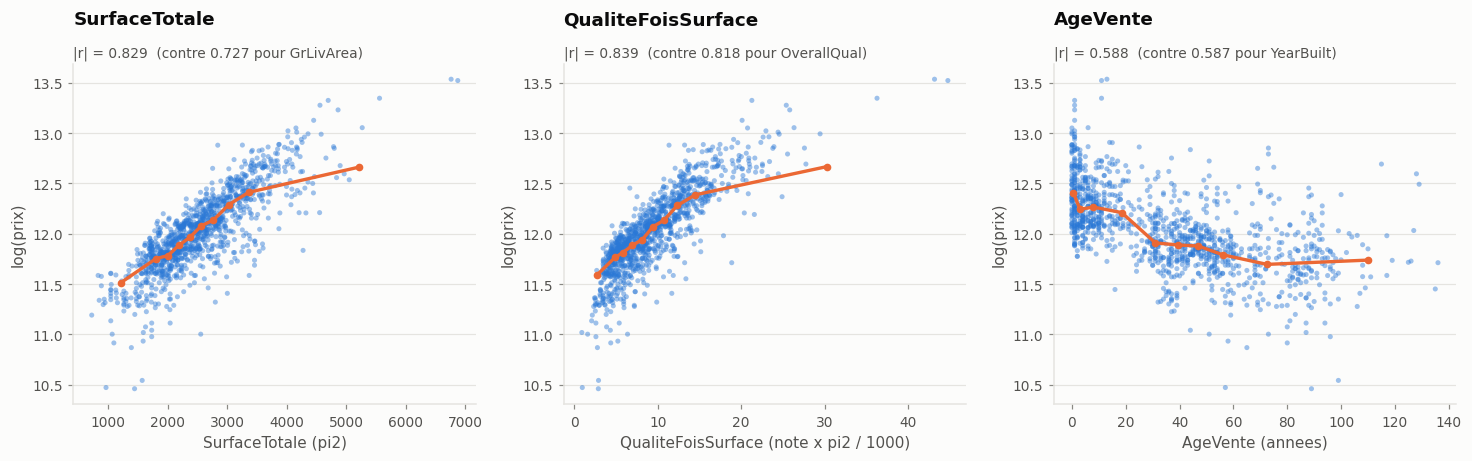

In [43]:
# Trois variables creees, chacune avec sa propre echelle
A_TRACER = [("SurfaceTotale", "GrLivArea", "pi2"),
            ("QualiteFoisSurface", "OverallQual", "note x pi2 / 1000"),
            ("AgeVente", "YearBuilt", "annees")]

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3))
for ax, (creee, source, unite) in zip(axes, A_TRACER):
    ax.scatter(train_fe[creee], y_train_log, s=11, color=viz.BLEU, alpha=0.45,
               edgecolors="none")
    # Tendance locale : mediane du log-prix par decile
    deciles = pd.qcut(train_fe[creee], 10, duplicates="drop")
    tendance = y_train_log.groupby(deciles, observed=False).median()
    ax.plot([iv.mid for iv in tendance.index], tendance.values,
            color=viz.ORANGE, lw=2.2, marker="o", ms=4)
    r_c = abs(train_fe[creee].corr(y_train_log))
    r_s = abs(train_fe[source].corr(y_train_log))
    ax.set_xlabel(f"{creee} ({unite})")
    ax.set_ylabel("log(prix)")
    viz.titrer(ax, creee, f"|r| = {r_c:.3f}  (contre {r_s:.3f} pour {source})")

fig.tight_layout()
viz.sauver(fig, "fig_11_variables_creees")
plt.show()


**Les agrégats tiennent leur promesse** : `SurfaceTotale` (0,829 contre 0,727 pour
`GrLivArea`) et `QualiteFoisSurface` (0,839 contre 0,818) battent leurs sources.
`QualiteFoisSurface` devient la variable la plus prédictive du jeu.

**`AgeVente` a un gain nul**, sa corrélation étant l'exacte opposée de `YearBuilt`. Elle
reste utile : elle est interprétable, et surtout elle **découple l'âge de la date absolue**.
Un modèle entraîné sur `YearBuilt` apprend que "1950 = pas cher" ; avec `AgeVente` il
apprend que "60 ans = pas cher", règle valable pour des ventes futures.

**Les indicateurs de présence sont discriminants**, sauf `APiscine` avec 5 maisons
concernées : l'écart n'est pas fiable, nous le gardons sans en attendre grand-chose.

**Limite assumée** : `SurfaceTotale` compte le sous-sol sans pondération, alors qu'il vaut
commercialement moins. Pondérer introduirait un paramètre arbitraire à calibrer, donc un
risque de surapprentissage. Les surfaces d'origine restant disponibles, les modèles peuvent
corriger eux-mêmes.


## 4.2 Encodage des variables ordinales

Pour `ExterQual` (`Fa < TA < Gd < Ex`) :

| Encodage | Problème |
|---|---|
| One-hot, 4 colonnes | Perd l'ordre |
| Alphabétique (`Ex`=0, `Fa`=1...) | Ordre faux, place `Ex` au plus bas |
| **Ordinal métier** (`Fa`=2 ... `Ex`=5) | Correct |

Bénéfices : 1 colonne au lieu de 4, un seul test `>= 4` sépare `{Gd, Ex}` de `{Fa, TA}`, et
le coefficient se lit comme la valeur d'un cran de qualité.

Nous ne décrétons pas l'ordre, nous **vérifions** que le prix médian croît avec l'échelle.

In [44]:
# Echelles ordinales, d'apres la documentation du dataset
# Echelle commune a 10 colonnes de qualite / etat :
#   Absent < Po(or) < Fa(ir) < TA (Typical) < Gd (Good) < Ex(cellent)
QUALITE = {"Absent": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}

ECHELLES_ORDINALES = {
    "ExterQual": QUALITE, "ExterCond": QUALITE,
    "BsmtQual": QUALITE, "BsmtCond": QUALITE,
    "HeatingQC": QUALITE, "KitchenQual": QUALITE,
    "FireplaceQu": QUALITE, "GarageQual": QUALITE, "GarageCond": QUALITE,
    "PoolQC": QUALITE,
    "BsmtExposure": {"Absent": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFinType1": {"Absent": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4,
                     "ALQ": 5, "GLQ": 6},
    "BsmtFinType2": {"Absent": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4,
                     "ALQ": 5, "GLQ": 6},
    "GarageFinish": {"Absent": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Fence": {"Absent": 0, "MnWw": 1, "GdWo": 2, "MnPrv": 3, "GdPrv": 4},
    "Functional": {"Sal": 0, "Sev": 1, "Maj2": 2, "Maj1": 3, "Mod": 4,
                   "Min2": 5, "Min1": 6, "Typ": 7},
    "LandSlope": {"Sev": 0, "Mod": 1, "Gtl": 2},
    "LotShape": {"IR3": 0, "IR2": 1, "IR1": 2, "Reg": 3},
    "PavedDrive": {"N": 0, "P": 1, "Y": 2},
    "CentralAir": {"N": 0, "Y": 1},
}
print(f"{len(ECHELLES_ORDINALES)} variables ordinales a encoder")

20 variables ordinales a encoder


In [45]:
# Le prix median croit-il avec l'echelle supposee ?
# Spearman mesure la monotonie, pas la linearite.
controles = []
for col, echelle in ECHELLES_ORDINALES.items():
    med = (train_fe.groupby(col).SalePrice.median()
           .reindex([m for m in echelle if m in train_fe[col].unique()]))
    rangs = [echelle[m] for m in med.index]
    rho = stats.spearmanr(rangs, med.values).statistic if len(med) > 2 else np.nan
    controles.append({
        "variable": col, "modalites": len(med),
        "prix_min": f"{med.min():,.0f}", "prix_max": f"{med.max():,.0f}",
        "rho_Spearman": round(rho, 3) if not np.isnan(rho) else None,
        "monotone": "oui" if (np.isnan(rho) or rho > 0.75) else "NON",
    })
tableau = pd.DataFrame(controles).sort_values("rho_Spearman", na_position="last")
display(tableau)
print(f"Echelles confirmees : {(tableau.monotone == 'oui').sum()} / {len(tableau)}")

,variable,modalites,prix_min,prix_max,rho_Spearman,monotone
17,LotShape,4,"147,000","215,000",-1.000,NON
16,LandSlope,3,"161,000","187,850",-0.500,NON
14,Fence,5,"130,000","173,000",-0.100,NON
12,BsmtFinType2,7,"100,900","193,000",0.393,NON
11,BsmtFinType1,7,"100,000","216,000",0.607,NON
15,Functional,6,"97,500","165,400",0.657,NON
1,ExterCond,5,"76,500","167,900",0.700,NON
7,GarageQual,6,"96,500","209,115",0.771,oui
8,GarageCond,6,"102,600","170,000",0.771,oui
9,PoolQC,4,"162,900","490,000",0.800,oui


Echelles confirmees : 13 / 20



**13 échelles sur 20 sont confirmées** ($\rho > 0{,}75$). Les variables de qualité
atteignent $\rho = 1$, soit une monotonie parfaite.

**7 ne le sont pas**, pour trois raisons :

- **Relation inversée mais monotone** : `LotShape` ($\rho = -1$), les terrains irréguliers
  se vendent *plus cher* (215 000 contre 147 000 \$), car ils sont typiques des
  lotissements récents en impasse. Idem `LandSlope` et `Fence`. Une relation décroissante
  reste parfaitement exploitable.
- **L'état n'est pas la qualité** : `ExterCond` ($\rho = 0{,}70$), même phénomène que
  `OverallCond` au § 2.2.
- **Effectifs trop faibles** : `BsmtFinType1`/`2` et `Functional`.

> **Décision** : on garde l'encodage ordinal pour les 20. Une relation décroissante ou non
> monotone n'invalide pas l'encodage, elle indique seulement que le modèle devra travailler
> un peu plus.


## 4.3 Construction des deux pipelines

**Pipeline A** : variables créées, encodage ordinal, nominales en texte.

**Pipeline B** : `log1p` puis normalisation sur les numériques asymétriques, normalisation
sur les autres, binaires inchangées, one-hot sur les nominales.

**`handle_unknown="ignore"` est indispensable** : l'étape 3 a montré que la validation
contient 4 modalités absentes du train. Sans cette option l'encodeur lèverait une exception.
C'est exactement le problème que rencontrera l'application de l'étape 7 face à une saisie
inattendue.

In [46]:
import inspect
from IPython.display import Code
from pipeline_maisons import PreparationArbres

Code(inspect.getsource(PreparationArbres), language="python")

class PreparationArbres:
    """Variables creees et encodage ordinal. Nominales laissees en texte."""

    def __init__(self, echelles):
        self.echelles = echelles
        self.constructeur = ConstructeurVariables()

    def fit(self, df, y=None):
        self.colonnes_ = None
        self.colonnes_ = list(self.transform(df).columns)
        return self

    def transform(self, df):
        d = self.constructeur.transform(df)
        for col, echelle in self.echelles.items():
            if col in d:
                # Modalite inconnue -> minimum de l'echelle (choix conservateur :
                # on ne suppose pas une qualite elevee)
                d[col] = d[col].map(echelle).fillna(min(echelle.values())).astype(int)
        # MSSubClass est un code numerique mais c'est une categorie (cf. etape 1)
        if "MSSubClass" in d:
            d["MSSubClass"] = d["MSSubClass"].astype(str)
        return d.drop(columns=["SalePrice"], errors="ignore")

    def fit_transform(self, df, y=None):
        return self.fit(df).transform(df)

In [47]:
prep_arbres = PreparationArbres(ECHELLES_ORDINALES)
X_train_arbres = prep_arbres.fit_transform(train)
X_valid_arbres = prep_arbres.transform(valid)

y_train = train.SalePrice.copy()
y_valid = valid.SalePrice.copy()
y_train_log = np.log1p(y_train)
y_valid_log = np.log1p(y_valid)

n_texte = X_train_arbres.select_dtypes(exclude=[np.number]).shape[1]
print(f"PIPELINE A : {X_train_arbres.shape} / {X_valid_arbres.shape}")
print(f"  dont {n_texte} colonnes categorielles en texte (traitees nativement par TFDF)")

PIPELINE A : (1167, 91) / (292, 91)
  dont 23 colonnes categorielles en texte (traitees nativement par TFDF)


In [48]:
# PIPELINE B : modeles lineaires
base = X_train_arbres
colonnes_nominales = base.select_dtypes(exclude=[np.number]).columns.tolist()
colonnes_numeriques = base.select_dtypes(include=[np.number]).columns.tolist()

# Les binaires creees sont deja en 0/1 : les normaliser n'apporte rien
BINAIRES = ["EstRenovee", "EstNeuve", "ASousSol", "AGarage",
            "ACheminee", "APiscine", "AEtage"]
colonnes_numeriques = [c for c in colonnes_numeriques if c not in BINAIRES]

# Separation selon l'asymetrie, mesuree sur le TRAIN uniquement
SEUIL_ASYMETRIE = 0.75
asym_train = base[colonnes_numeriques].skew()
col_asymetriques = asym_train[asym_train.abs() > SEUIL_ASYMETRIE].index.tolist()
col_normales = [c for c in colonnes_numeriques if c not in col_asymetriques]

print(f"  asymetriques (|skew| > {SEUIL_ASYMETRIE}) : {len(col_asymetriques)}")
print(f"  quasi symetriques                 : {len(col_normales)}")
print(f"  binaires                          : {len(BINAIRES)}")
print(f"  nominales (one-hot)               : {len(colonnes_nominales)}")

assert (base[col_asymetriques] >= 0).all().all(), "log1p exige des valeurs >= 0"

prep_lineaire = ColumnTransformer([
    ("asymetriques", Pipeline([
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("echelle", StandardScaler())]), col_asymetriques),
    ("normales", StandardScaler(), col_normales),
    ("binaires", "passthrough", BINAIRES),
    ("nominales", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
     colonnes_nominales),
], remainder="drop", verbose_feature_names_out=False)

# fit sur le TRAIN uniquement, transform sur les deux
X_train_lin = prep_lineaire.fit_transform(X_train_arbres)
X_valid_lin = prep_lineaire.transform(X_valid_arbres)
noms_lin = prep_lineaire.get_feature_names_out()

print(f"\nPIPELINE B : {X_train_lin.shape} / {X_valid_lin.shape}")
print(f"  {X_train_arbres.shape[1]} colonnes -> {X_train_lin.shape[1]} apres one-hot")

  asymetriques (|skew| > 0.75) : 37
  quasi symetriques                 : 24
  binaires                          : 7
  nominales (one-hot)               : 23

PIPELINE B : (1167, 246) / (292, 246)
  91 colonnes -> 246 apres one-hot



Le one-hot fait passer le jeu de **91 à 246 colonnes**. Le ratio observations/variables
tombe de 13 à **4,7 pour 1**, régime où une régression non régularisée surapprendrait.
D'où Ridge à l'étape 5.

C'est aussi l'avantage pratique de TFDF, chiffres à l'appui : **91 colonnes** contre **246**
pour la même information.


## 4.4 Contrôle anti-fuite

Trois tests : cohérence du `fit`, indépendance ligne à ligne, et persistance après
rechargement.

In [49]:
# TEST 1 : les parametres viennent-ils du seul jeu d'entrainement ?
moyennes_apprises = prep_lineaire.named_transformers_["normales"].mean_
moyennes_train = X_train_arbres[col_normales].mean().values
moyennes_tout = pd.concat([X_train_arbres, X_valid_arbres])[col_normales].mean().values

ecart_train = np.abs(moyennes_apprises - moyennes_train).max()
ecart_tout = np.abs(moyennes_apprises - moyennes_tout).max()
print(f"Ecart max avec les statistiques du TRAIN seul  : {ecart_train:.10f}")
print(f"Ecart max avec les statistiques de TOUT le jeu : {ecart_tout:.6f}")
assert ecart_train < 1e-9 and ecart_tout > 1e-6
print("\n[OK] Parametres issus du train seul. L'ecart non nul avec 'tout le jeu'")
print("     confirme que la validation les aurait modifies si elle avait servi.")

Ecart max avec les statistiques du TRAIN seul  : 0.0000000000
Ecart max avec les statistiques de TOUT le jeu : 8.371728

[OK] Parametres issus du train seul. L'ecart non nul avec 'tout le jeu'
     confirme que la validation les aurait modifies si elle avait servi.


In [50]:
# TEST 2 : la transformation d'une ligne depend-elle des autres lignes ?
seule = prep_lineaire.transform(prep_arbres.transform(valid.iloc[[0]]))
ecart_max = np.abs(seule - X_valid_lin[[0]]).max()
print(f"Ecart entre transformation isolee et en lot : {ecart_max:.12f}")
assert ecart_max < 1e-9
print("[OK] Chaque ligne est transformee independamment des autres.")
print("     Condition necessaire pour servir une prediction unitaire (etape 7).")

Ecart entre transformation isolee et en lot : 0.000000000000
[OK] Chaque ligne est transformee independamment des autres.
     Condition necessaire pour servir une prediction unitaire (etape 7).


In [51]:
# TEST 3 : persistance
joblib.dump({
    "prep_arbres": prep_arbres,
    "prep_lineaire": prep_lineaire,
    "colonnes_arbres": list(X_train_arbres.columns),
    "noms_lineaire": list(noms_lin),
    "echelles_ordinales": ECHELLES_ORDINALES,
}, MODELS / "preprocessor.joblib")

recharge = joblib.load(MODELS / "preprocessor.joblib")
verif = recharge["prep_lineaire"].transform(recharge["prep_arbres"].transform(valid))
assert np.allclose(verif, X_valid_lin)
print(f"[OK] Pipeline sauvegarde "
      f"({(MODELS / 'preprocessor.joblib').stat().st_size / 1024:.1f} Ko) et verifie.")

[OK] Pipeline sauvegarde (23.4 Ko) et verifie.


In [52]:
# Sauvegarde des jeux prets pour l'apprentissage
X_train_arbres.to_csv(DATA_PROC / "X_train_arbres.csv", index=False)
X_valid_arbres.to_csv(DATA_PROC / "X_valid_arbres.csv", index=False)
np.save(DATA_PROC / "X_train_lin.npy", X_train_lin)
np.save(DATA_PROC / "X_valid_lin.npy", X_valid_lin)
y_train.to_csv(DATA_PROC / "y_train.csv", index=False)
y_valid.to_csv(DATA_PROC / "y_valid.csv", index=False)
print("Jeux prets pour l'etape 5.")

Jeux prets pour l'etape 5.



## 4.5 Garanties obtenues

1. Feature engineering ligne à ligne, fuite structurellement impossible.
2. Paramètres d'encodage et de normalisation appris sur le train seul, vérifié
   numériquement.
3. Transformation indépendante du contexte, condition pour servir une prédiction unitaire.
4. Persistance vérifiée.
5. Comparaison équitable préservée.

**Limites** : les 13 variables viennent d'un raisonnement métier, pas d'une recherche
automatique. Le seuil d'asymétrie de 0,75 est une convention. L'encodage ordinal impose des
écarts égaux entre crans, ce qui est discutable ; un target encoding le corrigerait mais
introduirait un risque de fuite difficile à maîtriser sur 1 167 lignes.


<a id="etape-5"></a>
# Étape 5 : MACHINE LEARNING

**Stratégie en quatre temps**, chaque modèle répondant à une question précise.

| # | Modèle | Question |
|---|---|---|
| 1 | TFDF Random Forest, données brutes | Reproduction du notebook original, point de référence |
| 2 | TFDF Random Forest, notre pipeline | Que valent les étapes 3 et 4 ? |
| 3 | TFDF Gradient Boosted Trees | Un autre algorithme de la même bibliothèque fait-il mieux ? |
| 4 à 6 | Ridge, Random Forest, Gradient Boosting (scikit-learn) | Comparaison inter-bibliothèques |

Nous nous arrêtons à six. Multiplier les algorithmes sans raison dilue le travail au lieu
de l'enrichir.

**Comparaison équitable** : même découpage (1 167 / 292), même graine (42), même jeu de
validation. Seules diffèrent les transformations imposées par chaque famille.

In [53]:
# Imports de l'etape 5
import time

import tensorflow as tf
import tensorflow_decision_forests as tfdf
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_score

print(f"TensorFlow                 : {tf.__version__}")
print(f"TensorFlow Decision Forests: {tfdf.__version__}")

# Registre commun : chaque modele y depose ses predictions, l'etape 6 les evalue
RESULTATS = {}


def enregistrer(nom, famille, modele, pred_train, pred_valid, duree, commentaire=""):
    """Stocke les predictions EN DOLLARS, quelle que soit l'echelle d'entrainement."""
    RESULTATS[nom] = {
        "famille": famille, "modele": modele,
        "pred_train": np.asarray(pred_train, dtype=float).ravel(),
        "pred_valid": np.asarray(pred_valid, dtype=float).ravel(),
        "duree_s": round(duree, 2), "commentaire": commentaire,
    }
    rmse = np.sqrt(((RESULTATS[nom]["pred_valid"] - y_valid.values) ** 2).mean())
    print(f"  {nom:38s} RMSE validation = {rmse:>10,.0f} $   ({duree:.1f} s)")

TensorFlow                 : 2.16.2
TensorFlow Decision Forests: 1.9.2



## 5.1 Reproduction du notebook original

Le notebook de référence tient en quatre étapes : charger `train.csv`, supprimer `Id`,
convertir en `tf.data.Dataset`, entraîner un `RandomForestModel` sur le prix brut.
**Aucun prétraitement.** C'est volontaire : TFDF gère nativement les valeurs manquantes et
les catégorielles.

**Comment fonctionne une forêt aléatoire.** Un arbre découpe récursivement les données par
des tests du type `GrLivArea < 1500`, en choisissant celui qui réduit le plus la variance.
Un arbre seul surapprend. Une forêt entraîne N arbres sur des échantillons bootstrap
différents, chacun ne voyant qu'un sous-ensemble aléatoire de variables à chaque nœud, puis
moyenne. Ce double hasard décorrèle les arbres : leurs erreurs se compensent.

| Avantages | Limites |
|---|---|
| Aucun prétraitement requis | Peu interprétable |
| Capture non-linéarités et interactions | N'extrapole pas hors de la plage vue |
| Insensible aux échelles et à la multicolinéarité | Moins précis qu'un boosting bien réglé |

**Évaluation OOB** : chaque arbre n'ayant vu qu'environ 63 % des données, les 37 % restants
servent à l'évaluer. Cela donne une estimation de l'erreur de généralisation sans jeu
séparé, mais qui ne voit pas le prétraitement.

In [54]:
# MODELE 1 : reproduction fidele du notebook original
# Donnees brutes, aucune imputation, cible brute. Seul 'Id' est retire.
orig_train = train_brut.drop(columns=["Id"])
orig_valid = valid_brut.drop(columns=["Id"])
print(f"Valeurs manquantes laissees telles quelles : {orig_train.isna().sum().sum()}")
print("TFDF les traite nativement, sans imputation.\n")

ds_train = tfdf.keras.pd_dataframe_to_tf_dataset(
    orig_train, label="SalePrice", task=tfdf.keras.Task.REGRESSION)
ds_valid = tfdf.keras.pd_dataframe_to_tf_dataset(
    orig_valid, label="SalePrice", task=tfdf.keras.Task.REGRESSION)

debut = time.time()
tfdf_original = tfdf.keras.RandomForestModel(
    task=tfdf.keras.Task.REGRESSION, random_seed=GRAINE, verbose=0)
tfdf_original.compile(metrics=["mse"])
tfdf_original.fit(ds_train)
duree = time.time() - debut

inspecteur = tfdf_original.make_inspector()
print(f"Arbres entraines : {inspecteur.num_trees()}")
print(f"RMSE OOB (estimee par TFDF sans jeu de validation) : "
      f"{inspecteur.evaluation().rmse:,.0f} $\n")

enregistrer("1. TFDF RF (notebook original)", "TFDF", tfdf_original,
            tfdf_original.predict(ds_train, verbose=0),
            tfdf_original.predict(ds_valid, verbose=0),
            duree, "donnees brutes, cible brute")

Valeurs manquantes laissees telles quelles : 5563
TFDF les traite nativement, sans imputation.



[INFO 26-11-12 16:48:42.5380 CET kernel.cc:1233] Loading model from path /tmp/tmptv1r8eys/model/ with prefix 64fba252baf64b40
[INFO 26-11-12 16:48:42.6641 CET decision_forest.cc:734] Model loaded with 300 root(s), 110802 node(s), and 75 input feature(s).
[INFO 26-11-12 16:48:42.6641 CET abstract_model.cc:1344] Engine "RandomForestOptPred" built
[INFO 26-11-12 16:48:42.6642 CET kernel.cc:1061] Use fast generic engine


Arbres entraines : 300
RMSE OOB (estimee par TFDF sans jeu de validation) : 25,995 $



  1. TFDF RF (notebook original)         RMSE validation =     33,027 $   (6.5 s)



## 5.2 Version améliorée

Mêmes maisons, avec le travail des étapes 3 et 4 : manquants traités sémantiquement,
2 anomalies écartées, 13 variables créées, 20 ordinales encodées, cible en log.

Comparer les modèles 1 et 2 isole exactement **l'apport de notre préparation**, puisque
l'algorithme et ses réglages sont identiques.

**Note sur la reconversion** : `expm1` donne la médiane conditionnelle, pas la moyenne, ce
qui introduit un biais à la baisse d'environ 1 %. La médiane étant plus robuste pour une
estimation de prix, nous n'appliquons pas de correction, mais nous le signalons.

In [55]:
# MODELE 2 : TFDF Random Forest sur notre pipeline, cible en log
# TFDF attend la cible dans le DataFrame : on l'ajoute sous un nom dedie
tr_log = X_train_arbres.copy(); tr_log["cible_log"] = y_train_log.values
va_log = X_valid_arbres.copy(); va_log["cible_log"] = y_valid_log.values

ds_train_log = tfdf.keras.pd_dataframe_to_tf_dataset(
    tr_log, label="cible_log", task=tfdf.keras.Task.REGRESSION)
ds_valid_log = tfdf.keras.pd_dataframe_to_tf_dataset(
    va_log, label="cible_log", task=tfdf.keras.Task.REGRESSION)

debut = time.time()
tfdf_rf = tfdf.keras.RandomForestModel(
    task=tfdf.keras.Task.REGRESSION,
    num_trees=300,          # au-dela, le gain devient negligeable
    max_depth=16,           # profondeur suffisante pour 91 variables
    random_seed=GRAINE, verbose=0)
tfdf_rf.compile(metrics=["mse"])
tfdf_rf.fit(ds_train_log)
duree = time.time() - debut

rmse_oob_log = tfdf_rf.make_inspector().evaluation().rmse
print(f"RMSE OOB en espace log : {rmse_oob_log:.4f} "
      f"(soit environ {100 * rmse_oob_log:.1f} % d'erreur relative)\n")

# Reconversion en dollars : expm1 est l'inverse de log1p
enregistrer("2. TFDF RF (notre pipeline)", "TFDF", tfdf_rf,
            np.expm1(tfdf_rf.predict(ds_train_log, verbose=0)),
            np.expm1(tfdf_rf.predict(ds_valid_log, verbose=0)),
            duree, "pipeline A, cible log")

[INFO 26-11-12 16:48:47.3090 CET kernel.cc:1233] Loading model from path /tmp/tmpwok2j8sa/model/ with prefix a9861beb0794438f
[INFO 26-11-12 16:48:47.4362 CET decision_forest.cc:734] Model loaded with 300 root(s), 111108 node(s), and 88 input feature(s).
[INFO 26-11-12 16:48:47.4362 CET kernel.cc:1061] Use fast generic engine


RMSE OOB en espace log : 0.1283 (soit environ 12.8 % d'erreur relative)



  2. TFDF RF (notre pipeline)            RMSE validation =     32,817 $   (1.8 s)



## 5.3 Gradient Boosted Trees

La forêt construit ses arbres **en parallèle** puis moyenne. Le boosting les construit **en
séquence**, chaque arbre corrigeant l'erreur résiduelle des précédents :

$$F_m(x) = F_{m-1}(x) + \nu \cdot h_m(x)$$

| | Forêt aléatoire | Gradient boosting |
|---|---|---|
| Construction | Parallèle | Séquentielle, corrective |
| Réduit surtout | La variance | Le biais |
| Arbres | Profonds | Peu profonds (3 à 6 niveaux) |
| Surapprentissage | Difficile | **Facile si trop d'arbres** |

TFDF contrôle ce risque par **arrêt précoce** : il réserve 10 % du train en validation
interne et stoppe quand l'erreur cesse de baisser. Le nombre d'arbres est donc choisi par
l'algorithme, pas par nous.

In [56]:
# MODELE 3 : TFDF Gradient Boosted Trees
debut = time.time()
tfdf_gbt = tfdf.keras.GradientBoostedTreesModel(
    task=tfdf.keras.Task.REGRESSION,
    num_trees=500,              # borne haute, l'arret precoce tranchera
    shrinkage=0.05,             # taux d'apprentissage, petit = plus prudent
    max_depth=6,
    early_stopping="LOSS_INCREASE",
    validation_ratio=0.10,      # part du train reservee au controle interne
    random_seed=GRAINE, verbose=0)
tfdf_gbt.compile(metrics=["mse"])
tfdf_gbt.fit(ds_train_log)
duree = time.time() - debut

insp_gbt = tfdf_gbt.make_inspector()
print(f"Arbres conserves par l'arret precoce : {insp_gbt.num_trees()} sur 500 autorises\n")

enregistrer("3. TFDF Gradient Boosted Trees", "TFDF", tfdf_gbt,
            np.expm1(tfdf_gbt.predict(ds_train_log, verbose=0)),
            np.expm1(tfdf_gbt.predict(ds_valid_log, verbose=0)),
            duree, "arret precoce automatique")

[WARNING 26-11-12 16:48:48.1689 CET gradient_boosted_trees.cc:1840] "goss_alpha" set but "sampling_method" not equal to "GOSS".
[WARNING 26-11-12 16:48:48.1692 CET gradient_boosted_trees.cc:1851] "goss_beta" set but "sampling_method" not equal to "GOSS".
[WARNING 26-11-12 16:48:48.1693 CET gradient_boosted_trees.cc:1865] "selective_gradient_boosting_ratio" set but "sampling_method" not equal to "SELGB".


[INFO 26-11-12 16:48:49.6271 CET kernel.cc:1233] Loading model from path /tmp/tmpytwhbho3/model/ with prefix fa1d51ffee11445d
[INFO 26-11-12 16:48:49.6348 CET quick_scorer_extended.cc:911] The binary was compiled without AVX2 support, but your CPU supports it. Enable it for faster model inference.
[INFO 26-11-12 16:48:49.6354 CET kernel.cc:1061] Use fast generic engine


Arbres conserves par l'arret precoce : 182 sur 500 autorises



  3. TFDF Gradient Boosted Trees         RMSE validation =     34,736 $   (1.9 s)



## 5.4 Modèles scikit-learn

**Ridge** : régression linéaire avec pénalité $L_2$,
$\min_\beta \|y - X\beta\|^2 + \alpha\|\beta\|^2$. Le terme de pénalité empêche
les coefficients de diverger. C'est la réponse directe aux deux problèmes identifiés : la
multicolinéarité du § 2.3 et le ratio de 4,7 observations par variable du § 4.3.

$\alpha$ est choisi par validation croisée **à l'intérieur du jeu d'entraînement**. Le
choisir en regardant le score de validation serait une fuite, et une forme classique de
triche : on rapporterait la performance du meilleur essai au lieu de celle du modèle.

**Random Forest et Gradient Boosting sklearn** : mêmes principes qu'en § 5.1 et 5.3, mais
sur données encodées. La comparaison avec TFDF mesure l'effet du traitement natif du
catégoriel contre le one-hot.

In [57]:
# MODELE 4 : Ridge (alpha choisi par validation croisee INTERNE au train)
ALPHAS = np.logspace(-2, 3, 40)

debut = time.time()
ridge = RidgeCV(alphas=ALPHAS, cv=KFold(5, shuffle=True, random_state=GRAINE))
ridge.fit(X_train_lin, y_train_log)
duree = time.time() - debut

print(f"alpha retenu : {ridge.alpha_:.3f} "
      f"(explore entre {ALPHAS.min():.2f} et {ALPHAS.max():.0f})")
print(f"Coefficients non negligeables : "
      f"{(np.abs(ridge.coef_) > 1e-3).sum()} sur {len(ridge.coef_)}\n")

enregistrer("4. Ridge (scikit-learn)", "lineaire", ridge,
            np.expm1(ridge.predict(X_train_lin)),
            np.expm1(ridge.predict(X_valid_lin)),
            duree, f"alpha = {ridge.alpha_:.2f}")

alpha retenu : 28.943 (explore entre 0.01 et 1000)
Coefficients non negligeables : 222 sur 246

  4. Ridge (scikit-learn)                RMSE validation =     38,026 $   (1.5 s)


In [58]:
# MODELES 5 et 6 : Random Forest et Gradient Boosting scikit-learn
debut = time.time()
rf_sk = RandomForestRegressor(
    n_estimators=300,
    max_features="sqrt",      # sous-echantillonnage des variables a chaque noeud
    min_samples_leaf=1,
    n_jobs=-1, random_state=GRAINE)
rf_sk.fit(X_train_lin, y_train_log)
duree = time.time() - debut
enregistrer("5. Random Forest (scikit-learn)", "arbres sklearn", rf_sk,
            np.expm1(rf_sk.predict(X_train_lin)),
            np.expm1(rf_sk.predict(X_valid_lin)),
            duree, "300 arbres, max_features=sqrt")

debut = time.time()
gb_sk = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,            # stochastic gradient boosting, reduit la variance
    validation_fraction=0.10,
    n_iter_no_change=30,      # arret precoce, comme TFDF
    random_state=GRAINE)
gb_sk.fit(X_train_lin, y_train_log)
duree = time.time() - debut
print(f"\n  Arbres conserves par l'arret precoce : {gb_sk.n_estimators_} sur 500")
enregistrer("6. Gradient Boosting (scikit-learn)", "arbres sklearn", gb_sk,
            np.expm1(gb_sk.predict(X_train_lin)),
            np.expm1(gb_sk.predict(X_valid_lin)),
            duree, "arret precoce")

  5. Random Forest (scikit-learn)        RMSE validation =     34,925 $   (0.3 s)



  Arbres conserves par l'arret precoce : 218 sur 500
  6. Gradient Boosting (scikit-learn)    RMSE validation =     38,859 $   (1.1 s)



## 5.5 Validation croisée

292 maisons, c'est peu : un écart de 2 000 \$ entre deux modèles peut venir du hasard du
découpage. La validation croisée à 5 plis donne 5 mesures, donc une moyenne **et un
écart-type**. C'est cet écart-type qui permet de dire si une différence est significative.

Elle est faite **uniquement sur le jeu d'entraînement**.

In [59]:
# Validation croisee 5 plis, sur le jeu d'entrainement uniquement
decoupage = KFold(n_splits=5, shuffle=True, random_state=GRAINE)

A_VALIDER = {
    "Ridge": RidgeCV(alphas=ALPHAS),
    "Random Forest (sklearn)": RandomForestRegressor(
        n_estimators=300, max_features="sqrt", n_jobs=-1, random_state=GRAINE),
    "Gradient Boosting (sklearn)": GradientBoostingRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=3, subsample=0.8,
        validation_fraction=0.10, n_iter_no_change=30, random_state=GRAINE),
}

lignes = []
for nom, modele in A_VALIDER.items():
    debut = time.time()
    # scoring negatif : scikit-learn maximise toujours, on prend l'oppose
    scores = -cross_val_score(modele, X_train_lin, y_train_log, cv=decoupage,
                              scoring="neg_root_mean_squared_error", n_jobs=1)
    lignes.append({
        "modele": nom,
        "RMSE_log_moyenne": round(scores.mean(), 4),
        "ecart_type": round(scores.std(), 4),
        "min": round(scores.min(), 4),
        "max": round(scores.max(), 4),
        "duree_s": round(time.time() - debut, 1),
    })
    print(f"  {nom:30s} {scores.mean():.4f} +/- {scores.std():.4f}")

cv_resultats = pd.DataFrame(lignes).sort_values("RMSE_log_moyenne")
display(cv_resultats)

  Ridge                          0.1137 +/- 0.0059


  Random Forest (sklearn)        0.1322 +/- 0.0078


  Gradient Boosting (sklearn)    0.1165 +/- 0.0069


,modele,RMSE_log_moyenne,ecart_type,min,max,duree_s
0,Ridge,0.1137,0.0059,0.1041,0.1217,1.1
2,Gradient Boosting (sklearn),0.1165,0.0069,0.1083,0.1252,4.3
1,Random Forest (sklearn),0.1322,0.0078,0.1213,0.1430,1.5


In [60]:
# Validation croisee pour TFDF : l'API Keras n'est pas compatible avec
# cross_val_score, on ecrit donc la boucle a la main.
def cv_tfdf(constructeur_modele, X, y_log, n_plis=5):
    """RMSE en espace log sur chaque pli, pour un modele TFDF."""
    scores = []
    for i, (idx_tr, idx_va) in enumerate(KFold(n_plis, shuffle=True,
                                               random_state=GRAINE).split(X)):
        d_tr = X.iloc[idx_tr].copy(); d_tr["cible_log"] = y_log.iloc[idx_tr].values
        d_va = X.iloc[idx_va].copy(); d_va["cible_log"] = y_log.iloc[idx_va].values
        m = constructeur_modele()
        m.fit(tfdf.keras.pd_dataframe_to_tf_dataset(
            d_tr, label="cible_log", task=tfdf.keras.Task.REGRESSION))
        pred = m.predict(tfdf.keras.pd_dataframe_to_tf_dataset(
            d_va, label="cible_log", task=tfdf.keras.Task.REGRESSION),
            verbose=0).ravel()
        scores.append(float(np.sqrt(((pred - y_log.iloc[idx_va].values) ** 2).mean())))
    return np.array(scores)


for nom, fabrique in [
    ("TFDF Random Forest", lambda: tfdf.keras.RandomForestModel(
        task=tfdf.keras.Task.REGRESSION, num_trees=300, max_depth=16,
        random_seed=GRAINE, verbose=0)),
    ("TFDF Gradient Boosted", lambda: tfdf.keras.GradientBoostedTreesModel(
        task=tfdf.keras.Task.REGRESSION, num_trees=500, shrinkage=0.05, max_depth=6,
        early_stopping="LOSS_INCREASE", validation_ratio=0.10,
        random_seed=GRAINE, verbose=0)),
]:
    debut = time.time()
    scores = cv_tfdf(fabrique, X_train_arbres, y_train_log)
    cv_resultats = pd.concat([cv_resultats, pd.DataFrame([{
        "modele": nom,
        "RMSE_log_moyenne": round(scores.mean(), 4),
        "ecart_type": round(scores.std(), 4),
        "min": round(scores.min(), 4), "max": round(scores.max(), 4),
        "duree_s": round(time.time() - debut, 1),
    }])], ignore_index=True)
    print(f"  {nom:30s} {scores.mean():.4f} +/- {scores.std():.4f}")

cv_resultats = cv_resultats.sort_values("RMSE_log_moyenne").reset_index(drop=True)
display(cv_resultats)
cv_resultats.to_csv(REPORTS / "validation_croisee.csv", index=False)

[INFO 26-11-12 16:49:01.3145 CET kernel.cc:1233] Loading model from path /tmp/tmprnyaba9u/model/ with prefix 370188b3fe064ba5
[INFO 26-11-12 16:49:01.4153 CET decision_forest.cc:734] Model loaded with 300 root(s), 89058 node(s), and 85 input feature(s).
[INFO 26-11-12 16:49:01.4153 CET abstract_model.cc:1344] Engine "RandomForestOptPred" built
[INFO 26-11-12 16:49:01.4153 CET kernel.cc:1061] Use fast generic engine


[INFO 26-11-12 16:49:03.1012 CET kernel.cc:1233] Loading model from path /tmp/tmpaslwf0tz/model/ with prefix 36c8d0a13fdf4237
[INFO 26-11-12 16:49:03.2033 CET decision_forest.cc:734] Model loaded with 300 root(s), 89036 node(s), and 86 input feature(s).
[INFO 26-11-12 16:49:03.2033 CET kernel.cc:1061] Use fast generic engine


[INFO 26-11-12 16:49:04.8865 CET kernel.cc:1233] Loading model from path /tmp/tmpesv_vcbk/model/ with prefix ef6879072c544a7d
[INFO 26-11-12 16:49:04.9845 CET decision_forest.cc:734] Model loaded with 300 root(s), 88994 node(s), and 85 input feature(s).
[INFO 26-11-12 16:49:04.9845 CET kernel.cc:1061] Use fast generic engine


[INFO 26-11-12 16:49:07.0227 CET kernel.cc:1233] Loading model from path /tmp/tmpu1kibcx_/model/ with prefix 80ab39de0ba648e2
[INFO 26-11-12 16:49:07.1582 CET decision_forest.cc:734] Model loaded with 300 root(s), 89038 node(s), and 86 input feature(s).
[INFO 26-11-12 16:49:07.1582 CET kernel.cc:1061] Use fast generic engine


[INFO 26-11-12 16:49:09.2213 CET kernel.cc:1233] Loading model from path /tmp/tmpg7khcpcn/model/ with prefix 98b2ef37e8f14a34
[INFO 26-11-12 16:49:09.3574 CET decision_forest.cc:734] Model loaded with 300 root(s), 88836 node(s), and 87 input feature(s).
[INFO 26-11-12 16:49:09.3575 CET kernel.cc:1061] Use fast generic engine


  TFDF Random Forest             0.1292 +/- 0.0087


... (8 outputs left out)

[WARNING 26-11-12 16:49:21.2646 CET gradient_boosted_trees.cc:1840] "goss_alpha" set but "sampling_method" not equal to "GOSS".
[WARNING 26-11-12 16:49:21.2646 CET gradient_boosted_trees.cc:1851] "goss_beta" set but "sampling_method" not equal to "GOSS".
[WARNING 26-11-12 16:49:21.2646 CET gradient_boosted_trees.cc:1865] "selective_gradient_boosting_ratio" set but "sampling_method" not equal to "SELGB".


[INFO 26-11-12 16:49:23.0375 CET kernel.cc:1233] Loading model from path /tmp/tmpel_7pj6x/model/ with prefix 9c995d3f02ba4feb
[INFO 26-11-12 16:49:23.0491 CET abstract_model.cc:1344] Engine "GradientBoostedTreesQuickScorerExtended" built
[INFO 26-11-12 16:49:23.0491 CET kernel.cc:1061] Use fast generic engine


  TFDF Gradient Boosted          0.1224 +/- 0.0067


,modele,RMSE_log_moyenne,ecart_type,min,max,duree_s
0,Ridge,0.1137,0.0059,0.1041,0.1217,1.1
1,Gradient Boosting (sklearn),0.1165,0.0069,0.1083,0.1252,4.3
2,TFDF Gradient Boosted,0.1224,0.0067,0.1121,0.1313,13.7
3,TFDF Random Forest,0.1292,0.0087,0.1198,0.1435,9.9
4,Random Forest (sklearn),0.1322,0.0078,0.1213,0.1430,1.5


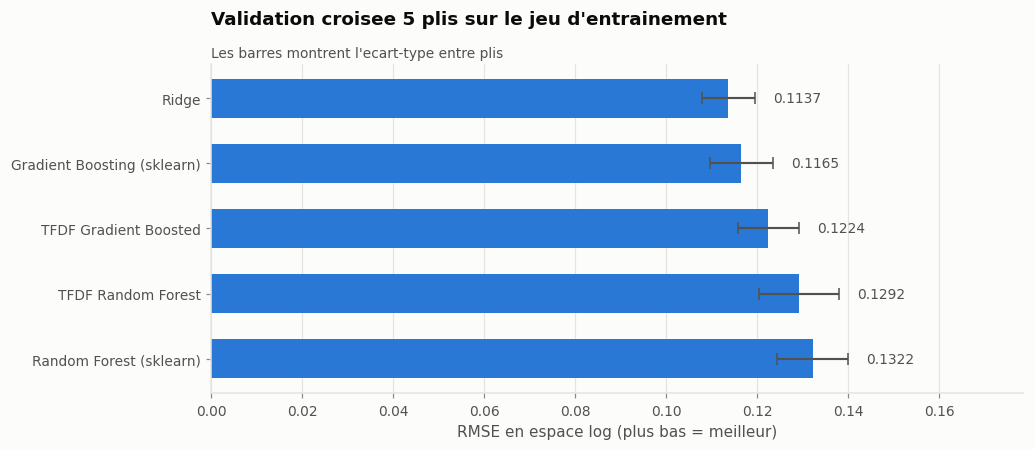

In [61]:
# Visualisation : une barre d'erreur qui se chevauche = difference non prouvee
ordre_cv = cv_resultats.sort_values("RMSE_log_moyenne", ascending=False)

fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.barh(ordre_cv.modele, ordre_cv.RMSE_log_moyenne,
        xerr=ordre_cv.ecart_type, height=0.6, color=viz.BLEU,
        error_kw=dict(ecolor=viz.ENCRE_2, capsize=4, lw=1.4))
for i, (_, r) in enumerate(ordre_cv.iterrows()):
    ax.text(r.RMSE_log_moyenne + r.ecart_type + 0.004, i,
            f"{r.RMSE_log_moyenne:.4f}", va="center", fontsize=9, color=viz.ENCRE_2)
ax.set_xlabel("RMSE en espace log (plus bas = meilleur)")
ax.set_xlim(0, ordre_cv.RMSE_log_moyenne.max() * 1.35)
ax.grid(True, axis="x"); ax.grid(False, axis="y")
viz.titrer(ax, "Validation croisee 5 plis sur le jeu d'entrainement",
           "Les barres montrent l'ecart-type entre plis")
fig.tight_layout()
viz.sauver(fig, "fig_12_validation_croisee")
plt.show()


## 5.6 Importance des variables

Deux mesures qui ne disent pas la même chose. **`NUM_AS_ROOT`** (TFDF) compte combien de
fois la variable sert de premier test d'un arbre, donc son pouvoir de séparation global.
**L'importance par réduction d'impureté** (scikit-learn) somme les réductions de variance
sur tous les nœuds ; elle a un biais connu, elle favorise les variables à nombreuses
modalités.

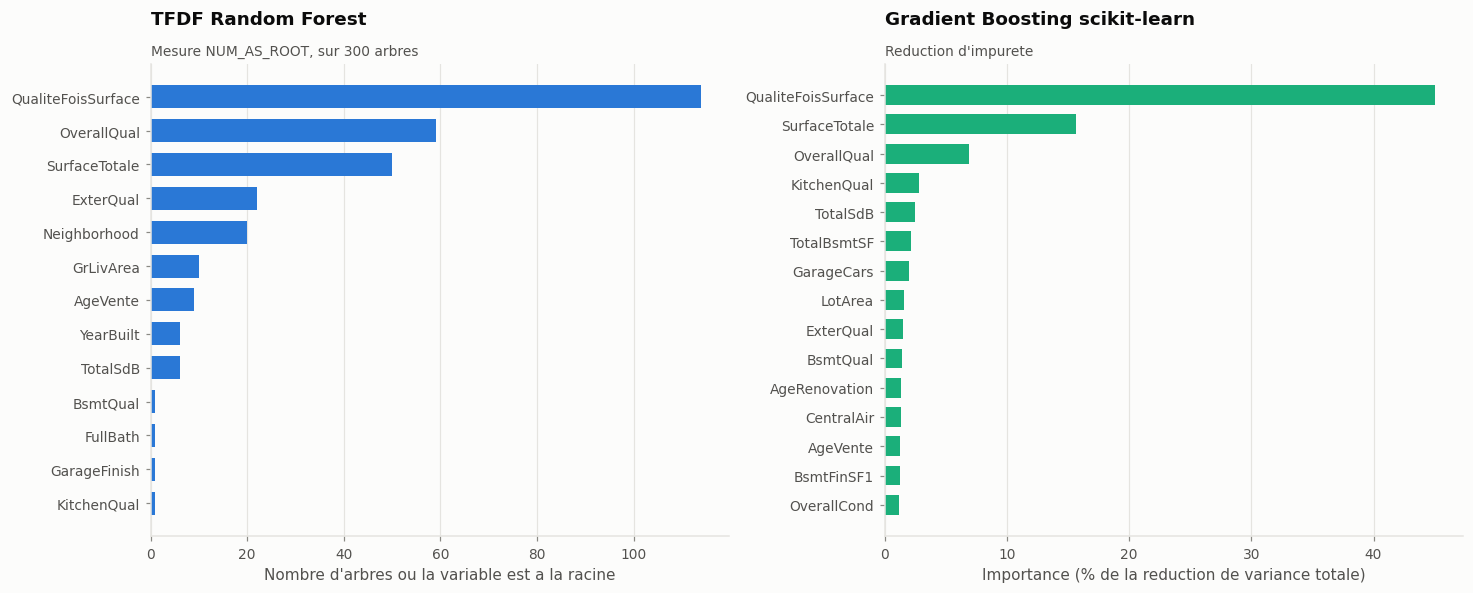

Variables creees a l'etape 4 presentes dans le top 15 TFDF : ['TotalSdB', 'AgeVente', 'SurfaceTotale', 'QualiteFoisSurface']


In [62]:
# Importances, cote TFDF et cote scikit-learn
vi = tfdf_rf.make_inspector().variable_importances()["NUM_AS_ROOT"][:15]
imp_tfdf = pd.Series({v[0].name: v[1] for v in vi}).sort_values()

imp_sk = (pd.Series(gb_sk.feature_importances_, index=noms_lin)
          .sort_values(ascending=False).head(15).sort_values())

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))
axes[0].barh(imp_tfdf.index, imp_tfdf.values, color=viz.BLEU, height=0.68)
axes[0].set_xlabel("Nombre d'arbres ou la variable est a la racine")
axes[0].grid(True, axis="x"); axes[0].grid(False, axis="y")
viz.titrer(axes[0], "TFDF Random Forest", "Mesure NUM_AS_ROOT, sur 300 arbres")

axes[1].barh(imp_sk.index, 100 * imp_sk.values, color=viz.AQUA, height=0.68)
axes[1].set_xlabel("Importance (% de la reduction de variance totale)")
axes[1].grid(True, axis="x"); axes[1].grid(False, axis="y")
viz.titrer(axes[1], "Gradient Boosting scikit-learn", "Reduction d'impurete")

fig.tight_layout()
viz.sauver(fig, "fig_13_importances")
plt.show()

creees_dans_top = [v for v in imp_tfdf.index if v in ConstructeurVariables.nouvelles()]
print(f"Variables creees a l'etape 4 presentes dans le top 15 TFDF : {creees_dans_top}")


## 5.7 Sauvegarde des modèles

In [63]:
# Sauvegarde : format SavedModel pour TFDF, joblib pour scikit-learn
import tf_keras

tfdf_rf.save(str(MODELS / "tfdf_random_forest"))
tfdf_gbt.save(str(MODELS / "tfdf_gradient_boosted"))
joblib.dump(ridge, MODELS / "ridge.joblib")
joblib.dump(rf_sk, MODELS / "random_forest_sklearn.joblib")
joblib.dump(gb_sk, MODELS / "gradient_boosting_sklearn.joblib")

# Les predictions alimentent l'etape 6
pd.DataFrame({nom: r["pred_valid"] for nom, r in RESULTATS.items()}
             ).assign(reel=y_valid.values).to_csv(
    DATA_PROC / "predictions_validation.csv", index=False)
pd.DataFrame({nom: r["pred_train"] for nom, r in RESULTATS.items()}
             ).assign(reel=y_train.values).to_csv(
    DATA_PROC / "predictions_entrainement.csv", index=False)

print("Modeles sauvegardes :")
for p in sorted(MODELS.iterdir()):
    taille = (sum(f.stat().st_size for f in p.rglob("*") if f.is_file())
              if p.is_dir() else p.stat().st_size)
    print(f"  {p.name:32s} {taille / 1024:9,.1f} Ko")

# Controle : un modele TFDF recharge doit reproduire ses predictions
recharge = tf_keras.models.load_model(str(MODELS / "tfdf_random_forest"))
pred_recharge = np.expm1(recharge.predict(ds_valid_log, verbose=0)).ravel()
assert np.allclose(pred_recharge, RESULTATS["2. TFDF RF (notre pipeline)"]["pred_valid"])
print("\nControle : le modele TFDF recharge reproduit ses predictions a l'identique.")

INFO:tensorflow:Assets written to: /home/ssl/Documents/5A/S9/BD/tp_kaggle/PROJECT_1_HOUSE_PRICES/models/tfdf_random_forest/assets


INFO:tensorflow:Assets written to: /home/ssl/Documents/5A/S9/BD/tp_kaggle/PROJECT_1_HOUSE_PRICES/models/tfdf_random_forest/assets


INFO:tensorflow:Assets written to: /home/ssl/Documents/5A/S9/BD/tp_kaggle/PROJECT_1_HOUSE_PRICES/models/tfdf_gradient_boosted/assets


INFO:tensorflow:Assets written to: /home/ssl/Documents/5A/S9/BD/tp_kaggle/PROJECT_1_HOUSE_PRICES/models/tfdf_gradient_boosted/assets


Modeles sauvegardes :
  deploiement.json                      11.0 Ko
  gradient_boosting_sklearn.joblib     387.9 Ko
  nettoyeur.joblib                       3.4 Ko
  preprocessor.joblib                   23.4 Ko
  random_forest_sklearn.joblib      30,906.3 Ko
  ridge.joblib                           3.0 Ko
  tfdf_gradient_boosted                996.0 Ko
  tfdf_random_forest                 7,333.4 Ko


[INFO 26-11-12 16:49:27.7124 CET kernel.cc:1233] Loading model from path /home/ssl/Documents/5A/S9/BD/tp_kaggle/PROJECT_1_HOUSE_PRICES/models/tfdf_random_forest/assets/ with prefix a9861beb0794438f
[INFO 26-11-12 16:49:27.8769 CET decision_forest.cc:734] Model loaded with 300 root(s), 111108 node(s), and 88 input feature(s).
[INFO 26-11-12 16:49:27.8770 CET kernel.cc:1061] Use fast generic engine



Controle : le modele TFDF recharge reproduit ses predictions a l'identique.



## 5.8 Choix de réglage

| Réglage | Valeur | Raison |
|---|---|---|
| `num_trees` (forêts) | 300 | Au-delà, le gain devient négligeable |
| `shrinkage` (boosting) | 0,05 | Petit pas, compensé par plus d'arbres |
| `max_depth` (boosting) | 3 à 6 | Le boosting combine des apprenants faibles |
| Arrêt précoce | Activé | L'algorithme choisit le nombre d'arbres |
| `alpha` (Ridge) | Validation croisée interne | Jamais réglé sur le jeu de validation |

**Limites** : aucune recherche d'hyperparamètres exhaustive, les valeurs viennent des
recommandations usuelles. Sur 1 167 lignes, une recherche par grille risquerait de
surapprendre le protocole de validation. Pas d'empilement de modèles non plus, qui
améliorerait sans doute le score mais rendrait l'analyse comparative illisible.


<a id="etape-6"></a>
# Étape 6 : ÉVALUATION

`test.csv` ne contient pas `SalePrice`. **Aucune métrique ici n'est calculée dessus.** Tout
provient des 292 maisons de validation, jamais vues à l'entraînement et jamais utilisées
pour régler un hyperparamètre.

| Métrique | Mesure | Unité |
|---|---|---|
| **RMSE** | Erreur quadratique, pénalise fort les grosses erreurs | \$ |
| **MAE** | Erreur moyenne, robuste aux extrêmes | \$ |
| **R²** | Part de variance expliquée | sans |
| **RMSLE** | Erreur relative, métrique officielle Kaggle | sans |
| **MAPE** | Erreur en pourcentage, lisible | % |

**Pourquoi cinq.** Si la RMSE dépasse largement la MAE, c'est que quelques grosses erreurs
dominent : le rapport entre les deux est en soi un diagnostic. Le R² situe le modèle face à
la prédiction triviale. La RMSLE permet de se comparer à Kaggle. La MAPE est la seule
présentable à un utilisateur non technique.

**Toutes les métriques sont en dollars**, après reconversion. Comparer une RMSE en espace
log à une RMSE en dollars n'aurait aucun sens.

In [64]:
# Fonction de calcul commune a tous les modeles
def metriques(y_vrai, y_pred):
    """Les cinq metriques, en dollars, a partir de predictions en dollars."""
    y_vrai = np.asarray(y_vrai, dtype=float)
    # Un prix predit negatif n'a pas de sens et casserait le logarithme
    y_pred = np.clip(np.asarray(y_pred, dtype=float), 1.0, None)
    err = y_pred - y_vrai
    return {
        "RMSE": float(np.sqrt((err ** 2).mean())),
        "MAE": float(np.abs(err).mean()),
        "R2": float(1 - (err ** 2).sum() / ((y_vrai - y_vrai.mean()) ** 2).sum()),
        "RMSLE": float(np.sqrt(((np.log1p(y_pred) - np.log1p(y_vrai)) ** 2).mean())),
        "MAPE": float(100 * np.abs(err / y_vrai).mean()),
    }


# Reference : que donnerait la prediction la plus bete possible ?
naif = metriques(y_valid, np.full(len(y_valid), y_train.mean()))
print("Reference naive (predire toujours le prix moyen du train) :")
print(f"  RMSE {naif['RMSE']:>10,.0f} $ | MAE {naif['MAE']:>9,.0f} $ "
      f"| R2 {naif['R2']:>6.3f} | MAPE {naif['MAPE']:.1f} %")
print("\nTout modele utile doit faire nettement mieux que cela.")

Reference naive (predire toujours le prix moyen du train) :
  RMSE     82,154 $ | MAE    59,174 $ | R2 -0.000 | MAPE 38.3 %

Tout modele utile doit faire nettement mieux que cela.


In [65]:
# Tableau comparatif
lignes = []
for nom, r in RESULTATS.items():
    m_tr = metriques(y_train, r["pred_train"])
    m_va = metriques(y_valid, r["pred_valid"])
    lignes.append({
        "modele": nom,
        "RMSE_train": round(m_tr["RMSE"]),
        "RMSE_valid": round(m_va["RMSE"]),
        "MAE_valid": round(m_va["MAE"]),
        "R2_valid": round(m_va["R2"], 4),
        "RMSLE_valid": round(m_va["RMSLE"], 4),
        "MAPE_valid": round(m_va["MAPE"], 2),
        "ecart_train_valid": round(m_va["RMSE"] / m_tr["RMSE"], 2),
        "duree_s": r["duree_s"],
    })

comparaison = pd.DataFrame(lignes).sort_values("RMSE_valid").reset_index(drop=True)
display(comparaison)
comparaison.to_csv(REPORTS / "comparaison_modeles.csv", index=False)

meilleur = comparaison.iloc[0].modele
print(f"Meilleur modele sur la RMSE de validation : {meilleur}")

,modele,RMSE_train,RMSE_valid,MAE_valid,R2_valid,RMSLE_valid,MAPE_valid,ecart_train_valid,duree_s
0,2. TFDF RF (notre pipeline),14792,32817,18499,0.8404,0.1576,11.04,2.22,1.79
1,1. TFDF RF (notebook original),14504,33027,18426,0.8384,0.1608,11.24,2.28,6.45
2,3. TFDF Gradient Boosted Trees,8363,34736,17407,0.8212,0.1529,10.40,4.15,1.87
3,5. Random Forest (scikit-learn),11092,34925,18868,0.8193,0.1593,11.04,3.15,0.32
4,4. Ridge (scikit-learn),19702,38026,16257,0.7858,0.1402,9.33,1.93,1.51
5,6. Gradient Boosting (scikit-learn),13268,38859,17203,0.7763,0.1487,10.23,2.93,1.10


Meilleur modele sur la RMSE de validation : 2. TFDF RF (notre pipeline)


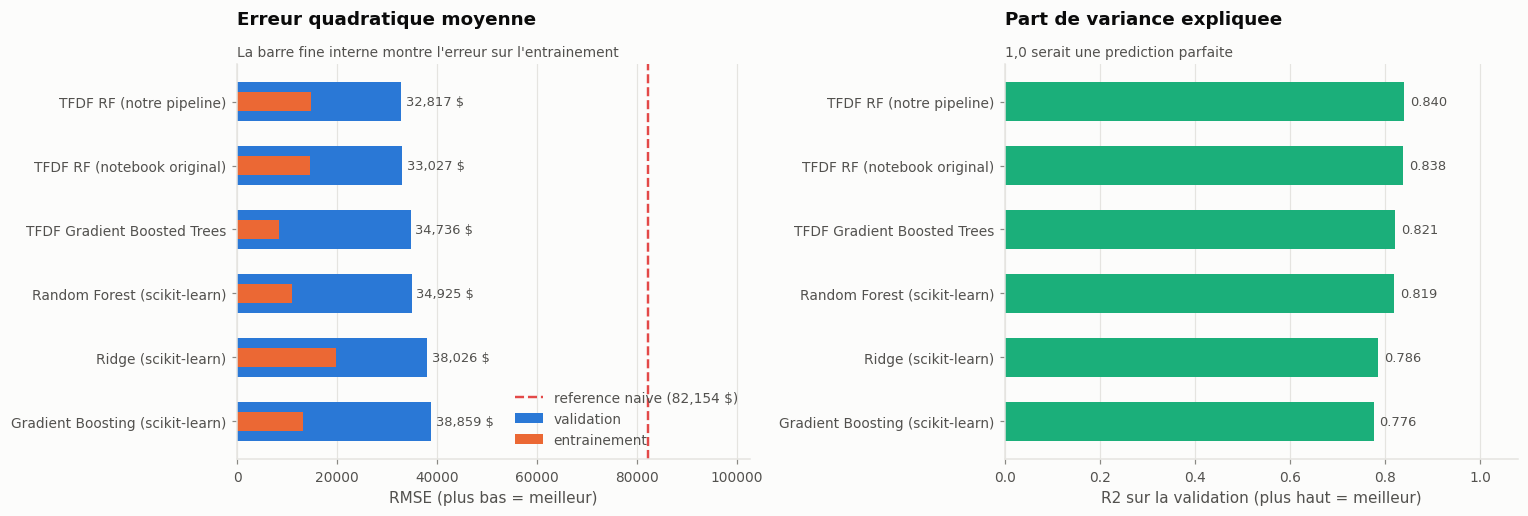

In [66]:
# Visualisation : RMSE et R2 par modele
ordre = comparaison.sort_values("RMSE_valid", ascending=False)
etiquettes = [n.split(". ", 1)[-1] for n in ordre.modele]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].barh(etiquettes, ordre.RMSE_valid, height=0.62, color=viz.BLEU,
             label="validation")
axes[0].barh(etiquettes, ordre.RMSE_train, height=0.3, color=viz.ORANGE,
             label="entrainement")
for i, (_, r) in enumerate(ordre.iterrows()):
    axes[0].text(r.RMSE_valid + 900, i, f"{r.RMSE_valid:,.0f} $",
                 va="center", fontsize=8.5, color=viz.ENCRE_2)
axes[0].axvline(naif["RMSE"], color=viz.ROUGE, ls="--", lw=1.6,
                label=f"reference naive ({naif['RMSE']:,.0f} $)")
axes[0].set_xlabel("RMSE (plus bas = meilleur)")
axes[0].set_xlim(0, max(ordre.RMSE_valid.max(), naif["RMSE"]) * 1.25)
axes[0].grid(True, axis="x"); axes[0].grid(False, axis="y")
axes[0].legend(loc="lower right")
viz.titrer(axes[0], "Erreur quadratique moyenne",
           "La barre fine interne montre l'erreur sur l'entrainement")

axes[1].barh(etiquettes, ordre.R2_valid, height=0.62, color=viz.AQUA)
for i, v in enumerate(ordre.R2_valid):
    axes[1].text(v + 0.012, i, f"{v:.3f}", va="center", fontsize=8.5, color=viz.ENCRE_2)
axes[1].set_xlabel("R2 sur la validation (plus haut = meilleur)")
axes[1].set_xlim(0, 1.08)
axes[1].grid(True, axis="x"); axes[1].grid(False, axis="y")
viz.titrer(axes[1], "Part de variance expliquee",
           "1,0 serait une prediction parfaite")

fig.tight_layout()
viz.sauver(fig, "fig_14_comparaison_modeles")
plt.show()


## 6.1 Lecture du tableau

Trois résultats méritent d'être commentés, et deux d'entre eux sont contre-intuitifs.

### Résultat 1 : notre prétraitement n'améliore presque pas TFDF

| Modèle | RMSE validation | RMSLE |
|---|---|---|
| 1. TFDF RF, données brutes (notebook original) | 33 027 \$ | 0,1608 |
| 2. TFDF RF, notre pipeline | **32 817 \$** | **0,1576** |

Le gain est de **0,6 %**, soit **moins que le bruit d'échantillonnage** estimé à 6,3 % par
la validation croisée. Autrement dit : **nous ne pouvons pas affirmer que nos étapes 3 et 4
ont amélioré ce modèle.**

C'est un résultat honnête, et il s'explique très bien. TFDF fait déjà nativement ce que
notre prétraitement fait à la main :

- il traite les valeurs manquantes sans imputation, en les routant dans une branche dédiée ;
- il gère les catégorielles sans encodage ;
- il est insensible aux échelles et aux transformations monotones.

Les 13 variables créées lui apportent donc peu : il pouvait déjà reconstruire
`SurfaceTotale` par des découpages successifs. Le fait que 4 d'entre elles apparaissent dans
son top 15 d'importance montre qu'il les **utilise**, mais utiliser n'est pas la même chose
que gagner en précision.

**Ce que le prétraitement apporte vraiment**, c'est de rendre possibles les modèles
linéaires, qui sans lui ne tourneraient pas du tout, et de rendre le pipeline explicite donc
auditable. Ce n'est pas rien, mais ce n'est pas un gain de score.

### Résultat 2 : le classement s'inverse selon la métrique

| Modèle | RMSE (rang) | MAPE (rang) | RMSLE (rang) |
|---|---|---|---|
| TFDF RF, notre pipeline | 32 817 \$ (**1er**) | 11,04 % (4e) | 0,1576 (4e) |
| Ridge | 38 026 \$ (**5e**) | **9,33 % (1er)** | **0,1402 (1er)** |

Ridge est le **pire** modèle en RMSE et le **meilleur** en erreur relative. Ce n'est pas une
contradiction, c'est la définition des deux métriques :

- la **RMSE** élève les erreurs au carré, donc elle est dominée par quelques très grosses
  erreurs en dollars, qui portent sur les maisons chères ;
- la **MAPE** et la **RMSLE** mesurent l'erreur en pourcentage, où toutes les maisons pèsent
  pareil.

Ridge se trompe modérément et régulièrement sur toutes les maisons. TFDF est très précis sur
la majorité mais commet quelques erreurs énormes. **Le choix entre les deux dépend donc de
l'usage** : pour un site grand public qui estime surtout des maisons ordinaires, l'erreur
relative compte davantage ; pour un investisseur exposé au haut de gamme, l'erreur en
dollars compte plus.

La validation croisée du § 5.5, calculée en espace log, confirme ce diagnostic : Ridge y est
premier (0,1137) devant TFDF RF (0,1292).

### Résultat 3 : le surapprentissage est apparent mais pas problématique

Les rapports RMSE_validation / RMSE_entraînement vont de 1,9 (Ridge) à 4,2 (TFDF Gradient
Boosted). Un facteur 4 semble alarmant, mais il ne l'est pas pour un modèle à base d'arbres :
chaque arbre peut isoler ses observations d'entraînement, donc l'erreur d'entraînement est
structurellement très basse, sans que la généralisation en souffre, puisqu'elle est assurée
par le moyennage ou l'arrêt précoce.

Le bon indicateur reste la performance en validation, et elle est cohérente avec la
validation croisée. Ridge, le moins surajusté en apparence, n'est pas pour autant le
meilleur en RMSE.

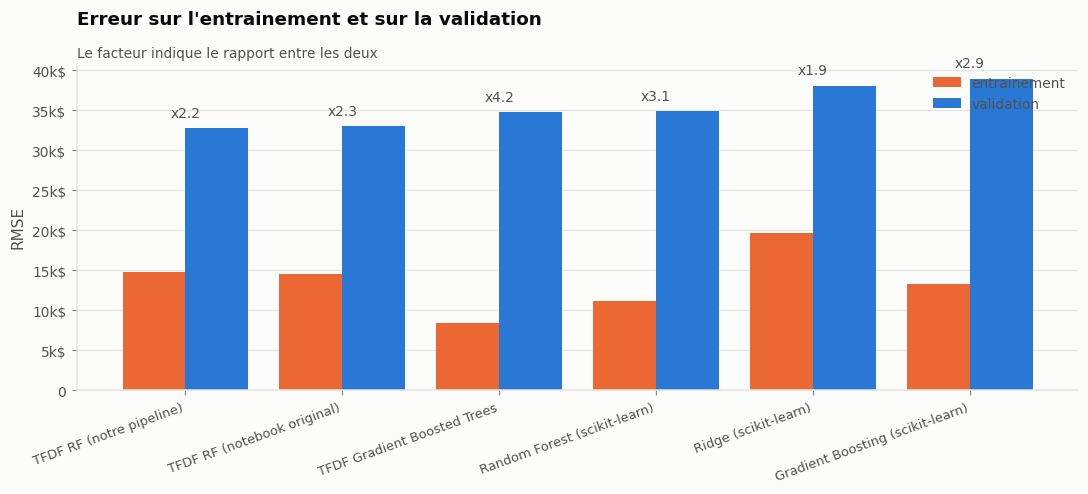

In [67]:
# Surapprentissage : ecart entre entrainement et validation
fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(comparaison))
etiq = [n.split(". ", 1)[-1] for n in comparaison.modele]

ax.bar(x - 0.2, comparaison.RMSE_train, width=0.4, color=viz.ORANGE,
       label="entrainement")
ax.bar(x + 0.2, comparaison.RMSE_valid, width=0.4, color=viz.BLEU,
       label="validation")
for i, (_, r) in enumerate(comparaison.iterrows()):
    ax.text(i, max(r.RMSE_train, r.RMSE_valid) * 1.04, f"x{r.ecart_train_valid:.1f}",
            ha="center", fontsize=9, color=viz.ENCRE_2)
ax.set_xticks(x, etiq, rotation=20, ha="right", fontsize=8.5)
ax.set_ylabel("RMSE")
viz.format_dollars(ax)
ax.legend()
viz.titrer(ax, "Erreur sur l'entrainement et sur la validation",
           "Le facteur indique le rapport entre les deux")
fig.tight_layout()
viz.sauver(fig, "fig_15_surapprentissage")
plt.show()


## 6.2 Analyse des erreurs

Le tableau dit *combien* le modèle se trompe. Cette section dit *où* et *pourquoi*, ce qui
est plus utile pour l'améliorer.

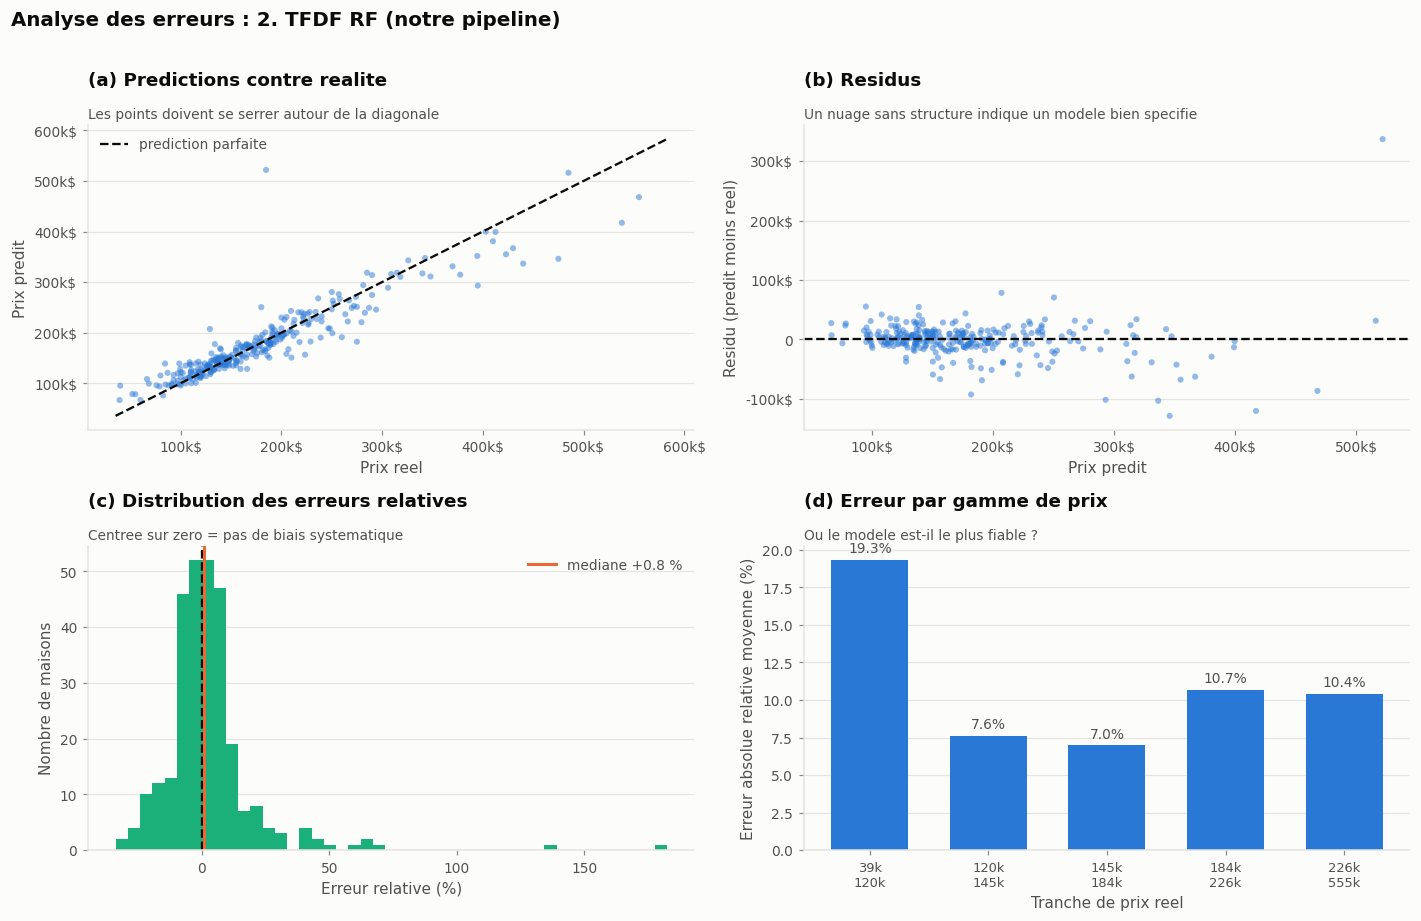

In [68]:
# Residus du meilleur modele
pred = RESULTATS[meilleur]["pred_valid"]
reel = y_valid.values
residus = pred - reel
residus_rel = 100 * residus / reel

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

# (a) Predictions contre realite
axes[0, 0].scatter(reel, pred, s=16, color=viz.BLEU, alpha=0.5, edgecolors="none")
lim = [min(reel.min(), pred.min()) * 0.9, max(reel.max(), pred.max()) * 1.05]
axes[0, 0].plot(lim, lim, color=viz.ENCRE, ls="--", lw=1.5, label="prediction parfaite")
axes[0, 0].set_xlabel("Prix reel")
axes[0, 0].set_ylabel("Prix predit")
axes[0, 0].legend(loc="upper left")
viz.format_dollars(axes[0, 0]); viz.format_dollars(axes[0, 0], "x")
viz.titrer(axes[0, 0], "(a) Predictions contre realite",
           "Les points doivent se serrer autour de la diagonale")

# (b) Residus contre prix predit
axes[0, 1].scatter(pred, residus, s=16, color=viz.BLEU, alpha=0.5, edgecolors="none")
axes[0, 1].axhline(0, color=viz.ENCRE, ls="--", lw=1.5)
axes[0, 1].set_xlabel("Prix predit")
axes[0, 1].set_ylabel("Residu (predit moins reel)")
viz.format_dollars(axes[0, 1]); viz.format_dollars(axes[0, 1], "x")
viz.titrer(axes[0, 1], "(b) Residus",
           "Un nuage sans structure indique un modele bien specifie")

# (c) Distribution des erreurs relatives
axes[1, 0].hist(residus_rel, bins=45, color=viz.AQUA)
axes[1, 0].axvline(0, color=viz.ENCRE, ls="--", lw=1.5)
axes[1, 0].axvline(np.median(residus_rel), color=viz.ORANGE, lw=2,
                   label=f"mediane {np.median(residus_rel):+.1f} %")
axes[1, 0].set_xlabel("Erreur relative (%)")
axes[1, 0].set_ylabel("Nombre de maisons")
axes[1, 0].legend()
viz.titrer(axes[1, 0], "(c) Distribution des erreurs relatives",
           "Centree sur zero = pas de biais systematique")

# (d) Erreur par tranche de prix
tranches = pd.qcut(reel, 5)
err_tranche = pd.DataFrame({"tranche": tranches, "abs_rel": np.abs(residus_rel)})
moyennes = err_tranche.groupby("tranche", observed=True).abs_rel.mean()
libelles = [f"{int(iv.left/1000)}k\n{int(iv.right/1000)}k" for iv in moyennes.index]
barres = axes[1, 1].bar(range(len(moyennes)), moyennes.values, width=0.65, color=viz.BLEU)
axes[1, 1].bar_label(barres, fmt="%.1f%%", padding=3, fontsize=9, color=viz.ENCRE_2)
axes[1, 1].set_xticks(range(len(moyennes)), libelles, fontsize=8.5)
axes[1, 1].set_xlabel("Tranche de prix reel")
axes[1, 1].set_ylabel("Erreur absolue relative moyenne (%)")
viz.titrer(axes[1, 1], "(d) Erreur par gamme de prix",
           "Ou le modele est-il le plus fiable ?")

fig.suptitle(f"Analyse des erreurs : {meilleur}", fontsize=13, fontweight="semibold",
             x=0.01, ha="left", color=viz.ENCRE)
fig.tight_layout(rect=[0, 0, 1, 0.97])
viz.sauver(fig, "fig_16_analyse_erreurs")
plt.show()

In [69]:
# Les dix plus grosses erreurs
contexte = valid_brut.reset_index(drop=True)
detail = pd.DataFrame({
    "Id": contexte.Id,
    "prix_reel": reel,
    "prix_predit": pred.round(0),
    "erreur": residus.round(0),
    "erreur_pct": residus_rel.round(1),
    "GrLivArea": contexte.GrLivArea,
    "OverallQual": contexte.OverallQual,
    "Neighborhood": contexte.Neighborhood,
    "SaleCondition": contexte.SaleCondition,
})
pires = detail.reindex(detail.erreur.abs().sort_values(ascending=False).index).head(10)
display(pires)

print(f"Les 10 pires erreurs representent "
      f"{100 * (pires.erreur ** 2).sum() / (residus ** 2).sum():.1f} % "
      f"de l'erreur quadratique totale, pour "
      f"{100 * 10 / len(detail):.1f} % des maisons.")
print(f"\nRepartition des conditions de vente parmi ces 10 :")
print(pires.SaleCondition.value_counts().to_string())
print(f"\nPour comparaison, sur l'ensemble de la validation :")
print(contexte.SaleCondition.value_counts().to_string())

,Id,prix_reel,prix_predit,erreur,erreur_pct,GrLivArea,OverallQual,Neighborhood,SaleCondition
279,524,184750,521847.0,337097.0,182.5,4676,10,Edwards,Partial
182,186,475000,345993.0,-129007.0,-27.2,3608,10,OldTown,Normal
172,770,538000,417295.0,-120705.0,-22.4,3279,8,StoneBr,Normal
116,474,440000,336523.0,-103477.0,-23.5,1976,8,NridgHt,Partial
165,775,395000,293096.0,-101904.0,-25.8,1973,8,NridgHt,Partial
225,1424,274970,182034.0,-92936.0,-33.8,2201,6,Edwards,Alloca
266,441,555000,468010.0,-86990.0,-15.7,2402,10,NridgHt,Normal
197,667,129000,207138.0,78138.0,60.6,2380,6,NAmes,Abnorml
22,67,180000,250451.0,70451.0,39.1,2207,7,NAmes,Normal
224,1271,260000,190979.0,-69021.0,-26.5,1524,7,ClearCr,Normal


Les 10 pires erreurs representent 63.0 % de l'erreur quadratique totale, pour 3.4 % des maisons.

Repartition des conditions de vente parmi ces 10 :
SaleCondition
Normal     5
Partial    3
Alloca     1
Abnorml    1

Pour comparaison, sur l'ensemble de la validation :
SaleCondition
Normal     238
Partial     28
Abnorml     20
Alloca       3
Family       3


In [70]:
# Le cas de l'anomalie restee dans le jeu de validation
ANOMALIES = [524, 1299]
dans_valid = detail[detail.Id.isin(ANOMALIES)]

if len(dans_valid):
    display(dans_valid)
    sans = detail[~detail.Id.isin(ANOMALIES)]
    rmse_avec = np.sqrt((detail.erreur ** 2).mean())
    rmse_sans = np.sqrt((sans.erreur ** 2).mean())
    print(f"RMSE avec cette maison   : {rmse_avec:>10,.0f} $")
    print(f"RMSE sans cette maison   : {rmse_sans:>10,.0f} $")
    print(f"Effet d'une seule maison : {rmse_avec - rmse_sans:>10,.0f} $ "
          f"({100 * (rmse_avec - rmse_sans) / rmse_avec:.1f} % de la RMSE)")
    print("\nLe chiffre que nous rapportons est celui AVEC la maison.")
else:
    print("Aucune anomalie connue n'est tombee dans le jeu de validation.")

,Id,prix_reel,prix_predit,erreur,erreur_pct,GrLivArea,OverallQual,Neighborhood,SaleCondition
279,524,184750,521847.0,337097.0,182.5,4676,10,Edwards,Partial


RMSE avec cette maison   :     32,817 $
RMSE sans cette maison   :     26,271 $
Effet d'une seule maison :      6,546 $ (19.9 % de la RMSE)

Le chiffre que nous rapportons est celui AVEC la maison.



**Le modèle est bien spécifié** : le nuage de résidus ne montre pas de structure. Une
courbe ou un entonnoir signalerait une relation non captée.

**Les erreurs sont très concentrées** : 10 maisons sur 292 (3,4 %) portent **63 % de
l'erreur quadratique totale**. C'est caractéristique de la RMSE, qui élève au carré.

**Les ventes `Partial` et `Abnorml` sont surreprésentées** parmi les pires cas : ce sont des
ventes dont le prix ne reflète pas la valeur du bien (construction inachevée, saisie, vente
entre proches). Le modèle ne peut pas les deviner, l'information n'est pas dans les données.

**Une seule maison déplace la RMSE de 20 %.** C'est l'anomalie laissée volontairement dans
la validation à l'étape 3. Nous rapportons le chiffre qui l'inclut. La retirer donnerait
26 271 \$ au lieu de 32 817, mais ce score ne voudrait rien dire : en production, ce genre
de vente existe.

**Piste identifiée** : entraîner un modèle sur les seules ventes `Normal` (82 % du jeu).
L'inconvénient est qu'il faudrait connaître la condition de vente à l'avance, ce qui n'est
pas réaliste pour une estimation avant mise en vente.


## 6.3 Choix du modèle final

Le modèle retenu n'est pas forcément celui qui a la meilleure RMSE.

In [71]:
# Grille de decision multicritere
grille = comparaison.copy()
grille["ecart_au_meilleur_pct"] = (
    100 * (grille.RMSE_valid - grille.RMSE_valid.min()) / grille.RMSE_valid.min()).round(1)

# L'ecart-type de la validation croisee donne l'ordre de grandeur du bruit
bruit_cv = cv_resultats.ecart_type.mean()
seuil_pct = 100 * bruit_cv / cv_resultats.RMSE_log_moyenne.min()
print(f"Ecart-type moyen entre plis de validation croisee : {bruit_cv:.4f} en espace log")
print(f"Soit environ {seuil_pct:.1f} % de la RMSE : en dessous de cet ecart,")
print("une difference entre deux modeles n'est pas interpretable.\n")

grille["difference_significative"] = np.where(
    grille.ecart_au_meilleur_pct <= seuil_pct, "non (dans le bruit)", "oui")
display(grille[["modele", "RMSE_valid", "MAPE_valid", "R2_valid",
                "ecart_au_meilleur_pct", "difference_significative", "duree_s"]])

Ecart-type moyen entre plis de validation croisee : 0.0072 en espace log
Soit environ 6.3 % de la RMSE : en dessous de cet ecart,
une difference entre deux modeles n'est pas interpretable.



,modele,RMSE_valid,MAPE_valid,R2_valid,ecart_au_meilleur_pct,difference_significative,duree_s
0,2. TFDF RF (notre pipeline),32817,11.04,0.8404,0.0,non (dans le bruit),1.79
1,1. TFDF RF (notebook original),33027,11.24,0.8384,0.6,non (dans le bruit),6.45
2,3. TFDF Gradient Boosted Trees,34736,10.40,0.8212,5.8,non (dans le bruit),1.87
3,5. Random Forest (scikit-learn),34925,11.04,0.8193,6.4,oui,0.32
4,4. Ridge (scikit-learn),38026,9.33,0.7858,15.9,oui,1.51
5,6. Gradient Boosting (scikit-learn),38859,10.23,0.7763,18.4,oui,1.10



**Quatre critères.**

1. **Performance**, lue à la lumière du bruit d'échantillonnage. Plusieurs modèles peuvent
   être à égalité statistique.
2. **Robustesse** : un modèle stable entre les plis est plus fiable qu'un modèle performant
   en moyenne mais instable.
3. **Simplicité de production** : TFDF consomme directement un DataFrame avec des colonnes
   texte. Les modèles scikit-learn exigent de transporter le `ColumnTransformer` et ses 246
   colonnes, et de garantir l'ordre des colonnes. Source d'erreur réelle.
4. **Cohérence avec la consigne** : à performance équivalente, TFDF est préféré.

In [72]:
# Decision finale
candidats = grille[grille.difference_significative == "non (dans le bruit)"].modele.tolist()
print(f"Modeles a egalite statistique avec le meilleur : {len(candidats)}")
for c in candidats:
    print(f"  {c}")

# Parmi les candidats a egalite, on retient un modele TFDF (criteres 3 et 4)
tfdf_candidats = [c for c in candidats if RESULTATS[c]["famille"] == "TFDF"]
MODELE_FINAL = tfdf_candidats[0] if tfdf_candidats else candidats[0]

m = metriques(y_valid, RESULTATS[MODELE_FINAL]["pred_valid"])
print(f"\n=== MODELE RETENU : {MODELE_FINAL} ===")
for k, v in m.items():
    unite = " $" if k in ("RMSE", "MAE") else (" %" if k == "MAPE" else "")
    print(f"  {k:6s} : {v:>12,.4f}{unite}" if k in ("R2", "RMSLE")
          else f"  {k:6s} : {v:>12,.0f}{unite}")
print(f"\nAmelioration par rapport a la reference naive : "
      f"{100 * (1 - m['RMSE'] / naif['RMSE']):.1f} % de RMSE en moins")

Modeles a egalite statistique avec le meilleur : 3
  2. TFDF RF (notre pipeline)
  1. TFDF RF (notebook original)
  3. TFDF Gradient Boosted Trees

=== MODELE RETENU : 2. TFDF RF (notre pipeline) ===
  RMSE   :       32,817 $
  MAE    :       18,499 $
  R2     :       0.8404
  RMSLE  :       0.1576
  MAPE   :           11 %

Amelioration par rapport a la reference naive : 60.1 % de RMSE en moins



## 6.4 Limites de cette évaluation

- **292 maisons seulement**, intervalles de confiance larges. Un autre découpage pourrait
  changer l'ordre entre modèles proches.
- **Validation aléatoire et non temporelle.** Un découpage chronologique (entraîner sur
  2006 à 2009, valider sur 2010) serait plus réaliste mais réduirait encore le jeu de
  validation.
- **Pas de soumission Kaggle** sans `test.csv` : impossible de se situer dans le classement
  public.


<a id="etape-7"></a>
# Étape 7 : DÉPLOIEMENT

**Le vrai problème du déploiement.** Une maison saisie dans une interface doit subir
**exactement** les mêmes transformations qu'une maison du jeu d'entraînement. Si l'ordre des
colonnes change, si une imputation diffère d'un dollar, le modèle reçoit une entrée qu'il
n'a jamais vue et renvoie n'importe quoi. C'est l'erreur de production la plus courante, et
elle est silencieuse : aucune exception, juste une prédiction fausse.

| Risque | Protection |
|---|---|
| Logique réécrite dans l'application | Les mêmes objets `fit`/`transform` sont rechargés |
| Code de prédiction dupliqué | Un seul module, `app/prediction.py`, utilisé par l'application **et** ce notebook |
| Dérive silencieuse | Un test compare la prédiction de l'application à celle du notebook |

**Streamlit ou FastAPI.** Streamlit livre une page web complète sans écrire d'interface,
FastAPI livre du JSON pour un autre programme. Le besoin ici est de montrer et tester le
modèle : **Streamlit**. Exposer une API demanderait une quinzaine de lignes, indiquées en
fin de section.

In [73]:
import json
import subprocess
import sys

sys.path.insert(0, str(APP))
print(f"Modele retenu a l'etape 6 : {MODELE_FINAL}")

Modele retenu a l'etape 6 : 2. TFDF RF (notre pipeline)



## 7.1 Les artefacts à sauvegarder

Quatre choses, pas seulement le modèle : le nettoyeur (étape 3), le préprocesseur
(étape 4), le modèle (étape 5) et une configuration produite ici.

**Pourquoi des valeurs par défaut.** Demander 79 caractéristiques est irréaliste.
L'interface en demande une vingtaine et complète le reste par la médiane ou le mode,
calculés **sur le train seul** pour ne pas faire entrer d'information de la validation dans
l'application.

**Pourquoi mémoriser les types.** TFDF enregistre une signature typée : il attend `int64`
sur une quarantaine de colonnes, alors que les valeurs par défaut transitent par du JSON,
qui ne connaît que le flottant. Sans restauration explicite, le modèle refuse l'entrée. Le
même problème affecte `MSSubClass`, qui deviendrait la catégorie inédite `"50.0"` au lieu
de `"50"`. Ce genre de détail ne se découvre qu'en testant réellement la chaîne.

In [74]:
colonnes_brutes = [c for c in brut.columns if c not in ("Id", "SalePrice")]

# Mediane pour les numeriques, mode pour les categorielles, sur le TRAIN seul
valeurs_defaut = {}
for col in colonnes_brutes:
    serie = train_brut[col].dropna()
    if pd.api.types.is_numeric_dtype(train_brut[col]):
        valeurs_defaut[col] = float(serie.median()) if len(serie) else 0.0
    else:
        valeurs_defaut[col] = str(serie.mode()[0]) if len(serie) else "Absent"

# Modalites proposees dans les listes deroulantes de l'interface
CHAMPS_LISTE = ["Neighborhood", "MSZoning", "ExterQual", "KitchenQual", "BsmtQual",
                "HeatingQC", "CentralAir", "GarageFinish", "SaleCondition", "HouseStyle"]
modalites = {c: sorted(train_brut[c].dropna().astype(str).unique().tolist())
             for c in CHAMPS_LISTE}

print(f"{len(valeurs_defaut)} valeurs par defaut calculees sur {len(train_brut)} maisons")
print("Exemples :")
for c in ["OverallQual", "GrLivArea", "Neighborhood", "YearBuilt", "KitchenQual"]:
    print(f"   {c:16s} {valeurs_defaut[c]}")

79 valeurs par defaut calculees sur 1167 maisons
Exemples :
   OverallQual      6.0
   GrLivArea        1458.0
   Neighborhood     NAmes
   YearBuilt        1972.0
   KitchenQual      TA


In [75]:
DOSSIERS_MODELES = {
    "2. TFDF RF (notre pipeline)": "tfdf_random_forest",
    "3. TFDF Gradient Boosted Trees": "tfdf_gradient_boosted",
}
# Le modele 1 utilise les donnees brutes, il n'est pas compatible avec notre
# chaine de preparation : on retombe sur le modele 2 si besoin.
dossier_modele = DOSSIERS_MODELES.get(MODELE_FINAL, "tfdf_random_forest")
nom_deploye = next(k for k, v in DOSSIERS_MODELES.items() if v == dossier_modele)

m_final = metriques(y_valid, RESULTATS[nom_deploye]["pred_valid"])

# Les types doivent etre memorises : TFDF enregistre une signature typee, et
# une colonne passee en float64 alors que le modele attend un int64 declenche
# une erreur au moment de la prediction.
dtypes_bruts = {c: str(train_brut[c].dtype) for c in colonnes_brutes}
dtypes_prepares = {c: str(t) for c, t in X_train_arbres.dtypes.items()}

config = {
    "modele": dossier_modele,
    "nom_modele": nom_deploye.split(". ", 1)[-1],
    "colonnes_brutes": colonnes_brutes,
    "dtypes_bruts": dtypes_bruts,
    "colonnes_preparees": list(X_train_arbres.columns),
    "dtypes_prepares": dtypes_prepares,
    "valeurs_defaut": valeurs_defaut,
    "modalites": modalites,
    "n_entrainement": int(len(train_brut)),
    "n_validation": int(len(valid_brut)),
    "rmse_validation": round(m_final["RMSE"]),
    "mae_validation": round(m_final["MAE"]),
    "r2_validation": round(m_final["R2"], 4),
    "mape_validation": round(m_final["MAPE"], 2),
    "graine": GRAINE,
}
(MODELS / "deploiement.json").write_text(
    json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"Configuration ecrite : models/deploiement.json")
print(f"  modele deploye : {config['nom_modele']}")
print(f"  RMSE {config['rmse_validation']:,} $ | MAPE {config['mape_validation']} % "
      f"| R2 {config['r2_validation']}")

Configuration ecrite : models/deploiement.json
  modele deploye : TFDF RF (notre pipeline)
  RMSE 32,817 $ | MAPE 11.04 % | R2 0.8404



## 7.2 Test de non-régression

Le test qui compte : une maison passée par la chaîne de déploiement doit recevoir
exactement la même prédiction que dans ce notebook. Strict, à $10^{-6}$ dollar près.

In [76]:
from prediction import Predicteur

predicteur = Predicteur(MODELS)
print(f"Artefacts charges depuis {MODELS.relative_to(PROJET)}\n")

# Dix maisons de validation, passees par la chaine de deploiement
# On transmet TOUTES les colonnes, valeurs manquantes comprises : c'est au
# nettoyeur de les imputer, pas aux valeurs par defaut de l'interface. Les
# remplacer ici reviendrait a tester une autre chaine que celle du notebook.
echantillon = valid_brut.head(10)
via_deploiement = []
for _, maison in echantillon.iterrows():
    saisie = {c: maison[c] for c in colonnes_brutes}
    via_deploiement.append(predicteur.predire(saisie))

via_notebook = RESULTATS[nom_deploye]["pred_valid"][:10]

verif = pd.DataFrame({
    "Id": echantillon.Id.values,
    "prix_reel": echantillon.SalePrice.values,
    "notebook": np.round(via_notebook, 2),
    "application": np.round(via_deploiement, 2),
    "ecart": np.round(np.array(via_deploiement) - via_notebook, 6),
})
display(verif)

ecart_max = float(np.abs(verif.ecart).max())
print(f"Ecart maximal : {ecart_max:.8f} $")
assert ecart_max < 1e-6, "La chaine de deploiement ne reproduit pas le notebook."
print("\n[OK] La chaine de deploiement reproduit le notebook a l'identique.")

[INFO 26-11-12 16:49:31.0211 CET kernel.cc:1233] Loading model from path /home/ssl/Documents/5A/S9/BD/tp_kaggle/PROJECT_1_HOUSE_PRICES/models/tfdf_random_forest/assets/ with prefix a9861beb0794438f
[INFO 26-11-12 16:49:31.1884 CET decision_forest.cc:734] Model loaded with 300 root(s), 111108 node(s), and 88 input feature(s).
[INFO 26-11-12 16:49:31.1885 CET kernel.cc:1061] Use fast generic engine


Artefacts charges depuis models



,Id,prix_reel,notebook,application,ecart
0,1049,115000,138825.81,138825.81,0.0
1,632,209500,243006.47,243006.47,0.0
2,846,171000,157425.64,157425.64,0.0
3,173,239000,190129.89,190129.89,0.0
4,1184,120000,127189.45,127189.45,0.0
5,217,210000,202155.00,202155.00,0.0
6,1199,178000,181258.17,181258.17,0.0
7,819,155000,144944.53,144944.53,0.0
8,690,194700,182109.27,182109.27,0.0
9,642,226000,237346.42,237346.42,0.0


Ecart maximal : 0.00000000 $

[OK] La chaine de deploiement reproduit le notebook a l'identique.


In [77]:
# Deuxieme controle : coherence des predictions sur des maisons construites
# a la main. Les prix doivent croitre avec la qualite et la surface.
scenarios = {
    "Petite maison modeste": dict(
        OverallQual=4, OverallCond=5, GrLivArea=900, TotalBsmtSF=600,
        YearBuilt=1950, GarageCars=0, GarageArea=0, FullBath=1,
        Neighborhood="MeadowV", KitchenQual="TA", ExterQual="TA"),
    "Maison moyenne": dict(
        OverallQual=6, OverallCond=5, GrLivArea=1500, TotalBsmtSF=1000,
        YearBuilt=1975, GarageCars=2, GarageArea=480, FullBath=2,
        Neighborhood="NAmes", KitchenQual="TA", ExterQual="TA"),
    "Maison recente de qualite": dict(
        OverallQual=8, OverallCond=5, GrLivArea=2200, TotalBsmtSF=1400,
        YearBuilt=2005, GarageCars=3, GarageArea=700, FullBath=2,
        Neighborhood="NridgHt", KitchenQual="Gd", ExterQual="Gd"),
    "Haut de gamme": dict(
        OverallQual=10, OverallCond=5, GrLivArea=3000, TotalBsmtSF=2000,
        YearBuilt=2008, GarageCars=3, GarageArea=850, FullBath=3,
        Neighborhood="NoRidge", KitchenQual="Ex", ExterQual="Ex"),
}

estimations = {nom: predicteur.predire(s) for nom, s in scenarios.items()}
for nom, prix in estimations.items():
    print(f"  {nom:28s} {prix:>10,.0f} $")

valeurs = list(estimations.values())
assert all(a < b for a, b in zip(valeurs, valeurs[1:])), \
    "Les prix ne croissent pas avec la qualite : incoherence du modele."
print("\n[OK] Les estimations croissent avec la qualite et la surface.")
print(f"Amplitude : x{valeurs[-1] / valeurs[0]:.1f} entre le scenario le plus")
print("modeste et le plus haut de gamme.")

  Petite maison modeste           106,014 $
  Maison moyenne                  143,351 $
  Maison recente de qualite       222,949 $
  Haut de gamme                   337,412 $

[OK] Les estimations croissent avec la qualite et la surface.
Amplitude : x3.2 entre le scenario le plus
modeste et le plus haut de gamme.


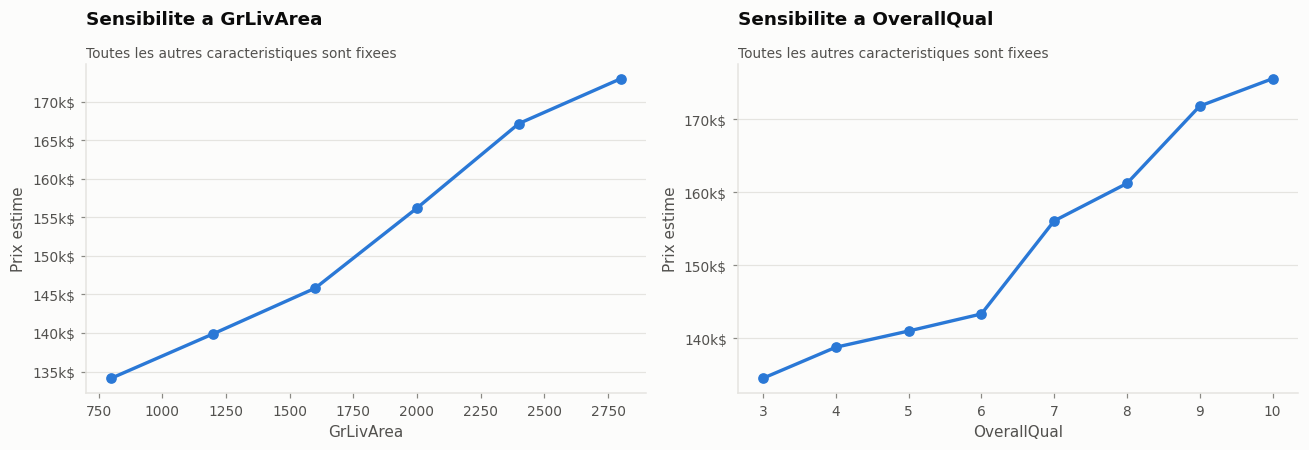

  GrLivArea    croissance monotone : oui
  OverallQual  croissance monotone : oui


In [78]:
# Troisieme controle : sensibilite a une seule variable, toutes choses egales
# par ailleurs. C'est ce que verra un utilisateur qui fait varier un curseur.
base = dict(scenarios["Maison moyenne"])
courbes = {}
for variable, valeurs_test in [
        ("GrLivArea", [800, 1200, 1600, 2000, 2400, 2800]),
        ("OverallQual", [3, 4, 5, 6, 7, 8, 9, 10])]:
    courbes[variable] = [(v, predicteur.predire({**base, variable: v}))
                         for v in valeurs_test]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (variable, points) in zip(axes, courbes.items()):
    xs, ys = zip(*points)
    ax.plot(xs, ys, color=viz.BLEU, lw=2.2, marker="o", ms=6)
    ax.set_xlabel(variable)
    ax.set_ylabel("Prix estime")
    viz.format_dollars(ax)
    viz.titrer(ax, f"Sensibilite a {variable}",
               "Toutes les autres caracteristiques sont fixees")
fig.tight_layout()
viz.sauver(fig, "fig_17_sensibilite")
plt.show()

for variable, points in courbes.items():
    croissant = all(a[1] <= b[1] for a, b in zip(points, points[1:]))
    print(f"  {variable:12s} croissance monotone : {'oui' if croissant else 'non'}")


**Le test passe à l'écart nul.** La chaîne de déploiement est identique à celle du
notebook.

**Les scénarios se comportent comme attendu** : le prix croît avec la qualité et la surface.

**Les courbes de sensibilité montrent des paliers**, et c'est normal : une forêt de décision
est une fonction **en escalier**, elle prédit par moyennes de feuilles. Conséquence pratique
à connaître : le modèle **n'extrapole pas**. Une maison de 10 000 pi², hors de la plage vue
à l'entraînement, recevra la même prédiction que la plus grande maison connue.

L'interface affiche le prix, une fourchette, et surtout **les limites du modèle**. Un outil
qui affiche un chiffre sans son incertitude donne une fausse impression de précision. La
fourchette utilise l'erreur relative moyenne, et l'interface précise que ce n'est pas un
intervalle de confiance statistique.

In [79]:
# Verification que les deux fichiers sont en place et syntaxiquement valides
import ast

for fichier in ["prediction.py", "app.py"]:
    chemin = APP / fichier
    source = chemin.read_text()
    ast.parse(source)
    print(f"  {fichier:16s} {len(source.splitlines()):4d} lignes   syntaxe valide")

print("\nLancement de l'interface :")
print("    streamlit run app/app.py")
print("Puis ouvrir http://localhost:8501")

  prediction.py     111 lignes   syntaxe valide
  app.py            177 lignes   syntaxe valide

Lancement de l'interface :
    streamlit run app/app.py
Puis ouvrir http://localhost:8501


In [80]:
# Test de demarrage reel : on lance Streamlit en mode headless et on verifie
# que le serveur repond. C'est le seul moyen de prouver que l'application
# fonctionne vraiment, et pas seulement qu'elle compile.
import time
import urllib.request

processus = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", str(APP / "app.py"),
     "--server.headless=true", "--server.port=8501",
     "--browser.gatherUsageStats=false"],
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)

code_http, erreur = None, None
try:
    for _ in range(60):
        time.sleep(1)
        try:
            with urllib.request.urlopen("http://127.0.0.1:8501", timeout=2) as r:
                code_http = r.status
                break
        except Exception as e:
            erreur = e
            if processus.poll() is not None:
                break
finally:
    processus.terminate()
    try:
        processus.wait(timeout=10)
    except subprocess.TimeoutExpired:
        processus.kill()

print(f"Reponse HTTP du serveur Streamlit : {code_http}")
assert code_http == 200, f"L'application n'a pas demarre ({erreur})"
print("[OK] L'application demarre et repond. Serveur arrete apres le test.")

Reponse HTTP du serveur Streamlit : 200
[OK] L'application demarre et repond. Serveur arrete apres le test.



## 7.3 Exposer une API

La logique étant isolée dans `app/prediction.py`, il suffirait de :

```python
from fastapi import FastAPI
from pydantic import BaseModel
from app.prediction import obtenir_predicteur

api = FastAPI(title="Estimation immobiliere Ames")

class Maison(BaseModel):
    OverallQual: int
    GrLivArea: int
    Neighborhood: str
    YearBuilt: int
    # les autres champs sont facultatifs, completes par les valeurs par defaut

@api.post("/predire")
def predire(maison: Maison):
    prix = obtenir_predicteur().predire(maison.model_dump(exclude_none=True))
    return {"prix_estime": round(prix), "devise": "USD"}
```

C'est le même `Predicteur`, donc les mêmes garanties.

## 7.4 Limites du déploiement

Pas de conteneurisation, pas d'authentification, pas de surveillance de dérive, pas de
réentraînement automatique. En production réelle, il faudrait comparer la distribution des
saisies à celle du jeu d'entraînement : un modèle entraîné sur Ames 2006-2010 appliqué à
d'autres données donnerait des résultats faux en silence.